# 34753 Robotics: Exam Solver, explained step by step

**What this is.** A calculator notebook for the MCQ exam. Every solver
1. says **which formula** it uses,
2. prints the **numbers substituted** into it, so you can follow and check every step,
3. ends with a line **`✅ ANSWER: ...`** that you compare with the answer options.

It is the explained companion of `Robotics_Exam_Toolkit.ipynb`. That file is short; this one teaches while it solves. This notebook is self-contained: it does not need the other one.

## How to use it in the exam (3 steps)
1. Open this file in VS Code. Top right: **Select Kernel → Python 3.14** (the global Python: it has numpy, sympy and matplotlib). Do not pick `.venvrobotics`: it has no Jupyter.
2. Click **Run All** once (about 30 s). This loads every tool and solves the past exam as examples. The last cell must print **ALL CHECKS PASSED**.
3. Find your question type in the **Quick finder** below, go to that cell, change the numbers marked `# <-- CHANGE`, press **Shift+Enter**, and read the steps and the ✅ ANSWER line.

> Only want the answers, without the steps? Set `EXPLAIN = False` in the setup cell, or pass `explain=False` to one solver.

## Conventions (read once)
| Thing | Convention |
|---|---|
| Angles you type | **degrees** (`deg=True` everywhere). Pass `deg=False` for radians. |
| Joint rates, Jacobians, $\omega$ | **radians** per second, always. |
| Lengths | any unit, but **one unit for the whole problem** (mm *or* m). Vision: the same unit as $\lambda$ (mm). |
| Symbols | `sp.symbols('L ell')` gives exact algebra. A symbolic angle is in **radians**; a plain number such as `90` is still degrees. |
| `atan2` | always `atan2(y, x)` (Python order). The slides write `Atan2(x, y)`: same function, other argument order. |
| Output | `▶` = a step, `·` = a detail, `✅ ANSWER` = the result to match with the options. |

## Quick finder: "the question says …" → go to
> **Looks like a past exam, a weekly exercise or a lecture example?** Go to **Section 10, the exercise bank**: 30 solved problems with the official answers (index table at its top). Copy the closest one and change the numbers.

| The question says / shows | Cell | Solver |
|---|---|---|
| "rotate … about the **current** / **fixed** axis, then translate …", fill the columns of $T$ | **1A** | `compose` |
| a frame drawn in a room or on a box, with symbols $L, H, \ell, a$ | **1B** | `frame_from_axes` |
| "is this a rotation matrix?", fill the missing column | **1C** | `check_rotation`, `complete_rotation` |
| inverse of $T$, $T^1_2$ from $T^0_1$ and $T^0_2$, a point or a vector in another frame | **1D** | `Hinv`, `relative`, `transform_point` |
| Euler ZYZ, roll-pitch-yaw, axis–angle (both directions) | **1E** | `zyz_from_R`, `rpy_from_R`, `axis_angle_from_R` |
| skew matrix $S$, angular velocity $\omega$, $\dot R$ | **1F** | `omega_from_S`, `omega_from_R` |
| frame from 3 points (task frame) | **1G** | `frame_from_points` |
| "how many joints / links?", "which joint does this motor drive?" | **2 (rules)** | read the markdown of Section 2 |
| DH table given → frames, $T^0_n$, compare with the figure | **2A** | `Robot`, `print_frames`, `plot` |
| figure with frames → **fill the DH table** | **2B** | `dh_from_frames` |
| one $A_i$ matrix given → its DH parameters | **2C** | `dh_from_A` |
| a DH matrix with **missing entries** (?) → parameters and the missing entries | **10.6** | `dh_from_partial` |
| a fixed gripper / camera offset after the last joint | **10.10, 10.12** | `Robot(..., tool=trans(z=a3))` |
| forward kinematics with symbols, template robots (SCARA, Stanford, …) | **2D** | `Robot(...).fk([q1, q2])` |
| 2-link planar IK, elbow up / down | **3A** | `ik_2r` |
| 3-link planar arm with a tool angle $\varphi$ | **3B** | `ik_3r_planar` |
| elbow (articulated) arm, wrist centre, spherical wrist | **3C** | `ik_elbow`, `wrist_center`, `ik_spherical_wrist` |
| 4-DoF arm: base + 3 pitch joints (like the project robot) | **3D** | `ik_4dof` |
| any other robot: numerical IK | **3E** | `ik_numeric` |
| "given $J$, the tip velocity is …", joint rates for a wanted tip velocity | **4A** | `apply_jacobian`, `joint_rates` |
| read the arm geometry back from a given planar $J$ | **4B** | `geometry_from_planar_J` |
| build $J$ from a DH table, Jacobian of a point (centre of mass, point A) | **4C, 4D** | `geometric_jacobian`, `point_jacobian` |
| singular configurations, $\det J$ | **4D** | `singularities`, `jacobian_numbers` |
| joint torques to hold a force, gravity load on the motors | **4E** | `statics`, `gravity_torques` |
| a velocity / force in another frame | **4F** | `transform_vector`, `twist_to_frame` |
| quintic / cubic coefficients | **5A, 5B** | `quintic`, `cubic` |
| several joints at once, polynomial through any conditions, via points | **5C, 5D** | `multi_joint`, `poly_from_conditions`, `piecewise_cubic` |
| trapezoidal velocity (LSPB), minimum time, constant jerk | **5E, 5F** | `lspb`, `bang_bang`, `jerk_profile` |
| jerk or acceleration given **piecewise** (sines, ramps, unknown $T$): $v_{max}$, $s(t)$, find $T$ | **10.14–10.17** | `motion_profile`, `profile_extrema` |
| 3D point → image plane $(u,v)$ → pixels $(r,c)$ | **6A, 6B** | `Camera`, `project` |
| camera points ↔ base frame, the camera moved | **6C, 6D** | `to_frame`, `world_to_pixel`, `pixel_to_world` |
| distance in pixels → mm → metres, depth from a known size | **6E** | `pixel_distance`, `depth_from_size`, `size_from_depth` |
| stereo depth, pixel → 3D point | **6F** | `stereo_depth`, `pixel_to_camera` |
| task frame seen by the camera from 3 pixels, object → robot base | **10.19** | `task_frame_from_pixels` |
| number of poles of a motor model | **7A** | `dc_motor_tf`, `tf_info` |
| steady-state error with P / PD / PI and a load torque | **7B, 7C** | `motor_position_loop`, `joint_loop` |
| block diagram → closed loop, $e_{ss}$, condition on a gain | **7D** | `solve_loop`, `series`, `parallel`, `feedback`, `final_value` |
| "derive $q(s)=(F q_r - G D)/N$" for a PI / PID loop with a disturbance | **10.23, 10.25** | `loop_tf` |
| for which gains is the loop stable? (Routh) | **7E** | `routh` |
| overshoot, settling time, $\zeta$, $\omega_n$, PD design, step response | **7F** | `second_order_specs`, `pd_design`, `step_response` |
| Laplace / inverse Laplace, initial / final value | **7G** | `laplace`, `inverse_laplace`, `final_value` |
| equations of motion, $D(q)$, $C(q,\dot q)$, $g(q)$ | **8** | `euler_lagrange`, `robot_dynamics` |
| any matrix (det, inverse, eigenvalues), any linear system, any equations | **9** | `matrix_info`, `lin_solve`, `solve_eqs` |
| a problem like a past exam / weekly exercise / lecture example | **10** | the exercise bank (index at its top) |
| "does everything still work?" | **11** | the self-test, must say ALL CHECKS PASSED |

In [1]:
# =====================================================================
# 0. SETUP: imports and printing helpers (Run All runs this first)
# =====================================================================
import numpy as np                 # numbers, vectors, matrices
import sympy as sp                 # symbols (L, H, theta1, s, ...) and exact algebra
import matplotlib.pyplot as plt    # plots: trajectories, step responses, robot frames
from math import factorial
try:                               # inside Jupyter: sympy results are shown as nice maths
    from IPython.display import display
except ImportError:                # plain Python: fall back to print
    display = print

np.set_printoptions(precision=4, suppress=True, linewidth=120)   # 4 decimals, hide 1e-17 noise
sp.init_printing(use_latex='mathjax')   # sympy results are shown as LaTeX maths in the notebook

EXPLAIN = True     # <-- True: every solver prints its working. False: only the ✅ ANSWER lines.
SILENT = False     # used by the self-test at the end to hide the ✅ lines; leave it False

DEG = np.pi / 180                  # degrees * DEG = radians
s, t = sp.symbols('s t')           # s = Laplace variable, t = time (Sections 5 and 7). Don't reuse these names!


# ---------- printing helpers used by every solver ----------
def _ex(flag):
    """Each solver has explain=None by default, which means: use the global EXPLAIN."""
    return EXPLAIN if flag is None else flag


def title(text):
    """A big header for one solver run."""
    print("\n" + "=" * 74 + f"\n{text}\n" + "=" * 74)


def step(text):
    """One step of the working."""
    print(f"\n▶ {text}")


def note(text):
    """A detail inside a step."""
    print(f"   · {text}")


def answer(text):
    """The final result you compare with the MCQ options."""
    if not SILENT:
        print(f"\n✅ ANSWER: {text}")


def _quiet(fn, *args, **kwargs):
    """Call a solver with no printing at all (used when one solver needs another one internally)."""
    global SILENT
    old = SILENT
    SILENT = True
    try:
        return fn(*args, explain=False, **kwargs)
    finally:
        SILENT = old


def clean(x, dec=4):
    """Round to `dec` decimals and turn -0.0 into 0.0, so printed matrices look clean."""
    return np.round(np.asarray(x, dtype=float), dec) + 0.0


def num(x, dec=4):
    """One number, printed compactly: 3, -400, 0.7854, 1.2e-05."""
    x = float(x)
    if abs(x - round(x)) < 1e-9 and abs(x) < 1e9:
        return str(int(round(x)))
    if abs(x) < 1e-3 or abs(x) >= 1e6:
        return f"{x:.{dec}g}"
    return f"{round(x, dec)}"


def par(x, dec=4):
    """A number for a printed formula: negative numbers in brackets, e.g. 8·(-30)/500."""
    txt = num(x, dec)
    return f"({txt})" if txt.startswith('-') else txt


def pm(name, M, dec=4):
    """Print a matrix or vector with a name. Works for numpy and sympy objects."""
    if isinstance(M, (sp.Basic, sp.MatrixBase)):
        print(f"{name} =")
        display(M)
        return
    A = clean(M, dec)
    if A.ndim <= 1:
        print(f"{name} = {A}")
    else:
        print(f"{name} =\n{A}")


def _is_sym(*xs):
    """True if any argument is a sympy object: then the solvers do exact / symbolic maths."""
    return any(isinstance(x, (sp.Basic, sp.MatrixBase)) for x in xs)


def atan2d(y, x):
    """atan2 in degrees, Python order (y first).
    Values below 1e-12 are snapped to 0 (so round-off gives 180 and not -180)."""
    y = 0.0 if abs(float(y)) < 1e-12 else float(y)
    x = 0.0 if abs(float(x)) < 1e-12 else float(x)
    return float(np.degrees(np.arctan2(y, x))) + 0.0


def wrap180(a):
    """Wrap an angle in degrees to (-180, 180]."""
    a = (np.asarray(a, dtype=float) + 180.0) % 360.0 - 180.0
    a = np.where(np.isclose(a, -180.0), 180.0, a) + 0.0
    return float(a) if a.ndim == 0 else a


print("setup done ✔   EXPLAIN =", EXPLAIN)

setup done ✔   EXPLAIN = True


---
# 1. Rotations and homogeneous transforms (MCQ Section 1: Q1.1, Q1.2)

### Theory in 60 seconds
* A rotation matrix $R^0_1=[\,x^0_1\;\;y^0_1\;\;z^0_1\,]$: its **columns are the axes of frame 1 written in frame 0**. $R^TR=I$, $\det R=+1$, $R^{-1}=R^T$.
* $R_x=\begin{bmatrix}1&0&0\\0&c&-s\\0&s&c\end{bmatrix}$, $\;R_y=\begin{bmatrix}c&0&s\\0&1&0\\-s&0&c\end{bmatrix}$, $\;R_z=\begin{bmatrix}c&-s&0\\s&c&0\\0&0&1\end{bmatrix}$. In $R_y$ the minus sign is **bottom-left**.
* Homogeneous transform $T^0_1=\begin{bmatrix}R^0_1&o^0_1\\0&1\end{bmatrix}$: columns 1–3 = the new axes, **column 4 = the origin of the new frame**, all written in the old frame.
* A **point** changes frame with $p^0=R\,p^1+o$ (append a 1). A **free vector** (velocity, force, axis direction) only rotates: $v^0=R\,v^1$ (append a 0).
* $T^{-1}=\begin{bmatrix}R^T&-R^To\\0&1\end{bmatrix}$. Chains: $T^0_2=T^0_1\,T^1_2$. Relative pose: $T^1_2=(T^0_1)^{-1}\,T^0_2$.

### The composition rule (the #1 exam trap)
| The move is about / along the … | Multiply the new matrix on the … |
|---|---|
| **current** axis (moving, body, new, "its own") | **right**: $T \leftarrow T\,M$ |
| **fixed** axis (global, world, base, original, reference) | **left**: $T \leftarrow M\,T$ |

The fixed moves pile up on the left (the last fixed move is leftmost). The current moves pile up on the right (the last current move is rightmost). `compose` prints the product, so you can see the order.

### Exam traps
* A translation "along the current $y$" happens **after** the earlier rotations, so it moves the origin by $R\,[0,50,0]^T$, not by $[0,50,0]^T$.
* Wrong options often come from the wrong multiplication order. If your column 4 matches an option and the rotation columns don't (or the other way round), re-check the order.
* Frames in a figure: write each new axis as $\pm$ an old axis first, then fill the columns. Check that $x\times y=z$ (right-handed).

In [2]:
# =====================================================================
# 1. TOOLS: rotations · homogeneous transforms · Euler/RPY · angular velocity
#    Run this cell once (Run All does it). The INPUT cells come after it.
# =====================================================================

def _cs(angle, deg, sym):
    """cos(angle), sin(angle).
    Plain numbers are DEGREES when deg=True. Sympy symbols are RADIANS
    (a sympy *number* such as sp.Integer(90) is still read as degrees)."""
    if sym:
        a = sp.sympify(angle)
        if deg and a.is_number:
            a = a * sp.pi / 180
        return sp.cos(a), sp.sin(a)
    a = np.deg2rad(angle) if deg else angle
    return np.cos(a), np.sin(a)


def _mat(rows, sym):
    """A numpy array, or a simplified sympy Matrix when the entries are symbolic."""
    return sp.simplify(sp.Matrix(rows)) if sym else np.array(rows, dtype=float)


# ---------- the three basic rotations (3x3) ----------
def rotx(th, deg=True):
    """R_x(th) = [[1, 0, 0], [0, c, -s], [0, s, c]]    (x stays, y and z turn)"""
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[1, 0, 0], [0, c, -s_], [0, s_, c]], sym)


def roty(th, deg=True):
    """R_y(th) = [[c, 0, s], [0, 1, 0], [-s, 0, c]]    (the minus sign is BOTTOM-LEFT)"""
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[c, 0, s_], [0, 1, 0], [-s_, 0, c]], sym)


def rotz(th, deg=True):
    """R_z(th) = [[c, -s, 0], [s, c, 0], [0, 0, 1]]    (z stays, x and y turn)"""
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[c, -s_, 0], [s_, c, 0], [0, 0, 1]], sym)


def rot(axis, th, deg=True):
    """rot('x' | 'y' | 'z', angle): pick a basic rotation by its axis name."""
    return {'x': rotx, 'y': roty, 'z': rotz}[axis.lower()](th, deg)


def mul(*Ms):
    """Multiply matrices from left to right: mul(A, B, C) = A·B·C (numpy or sympy)."""
    out = Ms[0]
    for M in Ms[1:]:
        if isinstance(out, sp.MatrixBase) or isinstance(M, sp.MatrixBase):
            out = sp.Matrix(out) * sp.Matrix(M)
        else:
            out = np.asarray(out, dtype=float) @ np.asarray(M, dtype=float)
    return sp.simplify(out) if isinstance(out, sp.MatrixBase) else out


# ---------- 4x4 homogeneous matrices ----------
def H(R=None, p=(0, 0, 0)):
    """4x4 homogeneous matrix [[R, p], [0 0 0 1]] from a 3x3 rotation R and a 3-vector p."""
    sym = isinstance(R, sp.MatrixBase) or _is_sym(*p)
    if sym:
        T = sp.eye(4)
        T[:3, :3] = sp.eye(3) if R is None else sp.Matrix(R)
        T[:3, 3] = sp.Matrix(list(p))
        return T
    T = np.eye(4)
    if R is not None:
        T[:3, :3] = np.asarray(R, dtype=float)
    T[:3, 3] = np.asarray(p, dtype=float)
    return T


def trans(x=0, y=0, z=0):
    """Pure translation Trans(x, y, z)."""
    return H(None, (x, y, z))


def Hrot(axis, th, deg=True):
    """Pure rotation as a 4x4 matrix: Rot_axis(th)."""
    return H(rot(axis, th, deg))


def Hinv(T):
    """Inverse of a homogeneous matrix WITHOUT a numeric inversion:  [[R^T, -R^T o], [0, 1]]."""
    if isinstance(T, sp.MatrixBase):
        R, o = T[:3, :3], T[:3, 3]
        Ti = sp.eye(4); Ti[:3, :3] = R.T; Ti[:3, 3] = -R.T * o
        return sp.simplify(Ti)
    T = np.asarray(T, dtype=float)
    R, o = T[:3, :3], T[:3, 3]
    return H(R.T, -R.T @ o)


# ---------- directions written as text: '+x', '-Y', 'z0', ... ----------
_AX = {'x': 0, 'y': 1, 'z': 2}


def vec(d):
    """Turn a direction into a 3-vector.
    Strings: '+x', '-y', 'z', '+Z', '-x0' -> unit vectors (case and a trailing frame number are ignored).
    Lists / tuples / arrays are passed through (sympy entries stay symbolic)."""
    if isinstance(d, str):
        d = d.strip().lower()
        sign = -1.0 if d.startswith('-') else 1.0
        v = np.zeros(3); v[_AX[d.lstrip('+-')[0]]] = sign
        return v
    if _is_sym(*d):
        return sp.Matrix(list(d))
    return np.asarray(d, dtype=float)


def axis_name(v, names=('X', 'Y', 'Z'), tol=1e-6):
    """Name a direction if it lies along a base axis: (0, -1, 0) -> '-Y'. Otherwise the rounded vector."""
    v = np.asarray(v, dtype=float)
    for k in range(3):
        e = np.zeros(3); e[k] = 1
        if np.allclose(v, e, atol=tol):
            return '+' + names[k]
        if np.allclose(v, -e, atol=tol):
            return '-' + names[k]
    return str(clean(v, 3))


def describe_T(T, old='0', new='1'):
    """Explain the 4 columns of a homogeneous matrix in words."""
    if isinstance(T, sp.MatrixBase):
        for k, what in enumerate([f"x{new}", f"y{new}", f"z{new}", f"origin o{new}"]):
            print(f"   column {k+1} = {what} seen from frame {old}: {list(T[:3, k])}")
        return
    T = np.asarray(T, dtype=float)
    names = (f"x{old}", f"y{old}", f"z{old}")
    for k, what in enumerate([f"x{new}", f"y{new}", f"z{new}"]):
        print(f"   column {k+1} = {what} written in frame {old}: {clean(T[:3, k])}   ({what} = {axis_name(T[:3, k], names)})")
    print(f"   column 4 = origin o{new} written in frame {old}: {clean(T[:3, 3])}")


def compose(steps, deg=True, explain=None, start=None):
    """Build T from a list of elementary moves, using the current/fixed rule.

    steps : list of tuples (op, axis, value, frame)
        op    : 'rot' (value = angle, degrees by default)  or  'trans' (value = distance)
        axis  : 'x', 'y' or 'z'
        frame : 'current' -> about/along the MOVING frame -> multiply on the RIGHT (T = T·M)
                'global'  -> about/along the FIXED frame  -> multiply on the LEFT  (T = M·T)
                ('fixed', 'world', 'base' mean 'global'; 'body', 'moving', 'new', 'local' mean 'current')
    start : optional start matrix (default: identity = the new frame starts on top of the old one)
    Returns the 4x4 matrix T (numpy, or sympy if a value is a symbol)."""
    ex = _ex(explain)
    sym = any(_is_sym(v) for _, _, v, _ in steps)
    T = (sp.eye(4) if sym else np.eye(4)) if start is None else start
    formula = "I" if start is None else "T_start"
    if ex:
        title("compose: a sequence of moves → homogeneous matrix T")
    for k, (op, axis, val, frame) in enumerate(steps, 1):
        frame = frame.lower()
        if op.lower().startswith('rot'):
            M = Hrot(axis, val, deg)
            label = f"Rot_{axis}({val}{'°' if deg and not _is_sym(val) else ''})"
        else:
            M = trans(**{axis.lower(): val})
            label = f"Trans_{axis}({val})"
        if sym and not isinstance(M, sp.MatrixBase):
            M = sp.Matrix(M)
        if frame in ('current', 'body', 'moving', 'new', 'local'):
            T = T * M if sym else T @ M                     # post-multiply
            formula = label if formula == "I" else f"{formula} · {label}"
            side = "CURRENT axis → multiply on the RIGHT"
        elif frame in ('global', 'fixed', 'world', 'base', 'original'):
            T = M * T if sym else M @ T                     # pre-multiply
            formula = label if formula == "I" else f"{label} · {formula}"
            side = "FIXED/global axis → multiply on the LEFT"
        else:
            raise ValueError("frame must be 'current' or 'global'")
        if ex:
            step(f"move {k}: {op} {axis} by {val}, {frame} frame  ({side})")
            note(f"T so far = {formula}")
    if sym:
        T = sp.simplify(T)
    if ex:
        step("final product: fixed moves on the left, current moves on the right")
        print(f"   T = {formula}")
        pm("T", T)
        step("what the columns mean")
        describe_T(T)
    answer("the 4 columns of T above (column 4 = origin of the new frame)")
    return T


def check_rotation(R, tol=1e-3, explain=None):
    """Is R a valid rotation matrix?
    Checks: every column has length 1, the columns are perpendicular, det R = +1
    (det = -1 is a mirror image: one axis has the wrong sign)."""
    ex = _ex(explain)
    if isinstance(R, sp.MatrixBase):
        R = R[:3, :3]
        RtR = sp.simplify(R.T * R); d = sp.simplify(R.det())
        ok = bool(RtR == sp.eye(3)) and bool(d == 1)
        if ex:
            pm("R^T R (must be I)", RtR); print("det R =", d)
        answer("valid rotation ✔" if ok else "NOT a valid rotation ✘")
        return ok
    R = np.asarray(R, dtype=float)[:3, :3]
    norms = np.linalg.norm(R, axis=0)
    dots = [R[:, 0] @ R[:, 1], R[:, 0] @ R[:, 2], R[:, 1] @ R[:, 2]]
    det = np.linalg.det(R)
    ortho = np.allclose(norms, 1, atol=tol) and np.allclose(dots, 0, atol=tol)
    ok = ortho and abs(det - 1) < tol
    if ex:
        title("is R a rotation matrix?")
        step("length of each column (must all be 1)"); note(clean(norms))
        step("dot products col1·col2, col1·col3, col2·col3 (must all be 0)"); note(clean(dots))
        step("determinant (must be +1)"); note(f"det R = {det:.4f}")
        if ortho and abs(det + 1) < tol:
            note("orthonormal but det = -1 → left-handed: flip the sign of one column")
    answer("valid rotation ✔" if ok else "NOT a valid rotation ✘")
    return ok


def complete_rotation(c1=None, c2=None, c3=None, explain=None):
    """Fill in the missing column of a rotation matrix from the other two (right-hand rule):
        c3 = c1 × c2,   c1 = c2 × c3,   c2 = c3 × c1.
    Give exactly two columns (lists, or strings like '+y'), leave the unknown one as None."""
    ex = _ex(explain)
    cols = [c1, c2, c3]
    missing = [i for i, c in enumerate(cols) if c is None]
    assert len(missing) == 1, "give exactly two columns and leave one as None"
    i = missing[0]
    a_, b_ = vec(cols[(i + 1) % 3]), vec(cols[(i + 2) % 3])
    cols[i] = np.cross(a_, b_)
    R = np.column_stack([vec(c) for c in cols])
    if ex:
        title("complete a rotation matrix")
        step(f"missing column {i+1} = column {(i+1)%3+1} × column {(i+2)%3+1}  (x = y × z, y = z × x, z = x × y)")
        note(f"{clean(a_)} × {clean(b_)} = {clean(cols[i])}")
        pm("R", R)
    answer(f"column {i+1} = {clean(cols[i])}")
    return R


def frame_from_axes(x1=None, y1=None, z1=None, origin=(0, 0, 0), old='0', new='1', explain=None):
    """T^old_new from the axes of the NEW frame written in the OLD frame (read them off the figure).
    Each axis: a string like '+y0' / '-z' or a 3-vector. Leave ONE axis as None and it is computed
    with the right-hand rule. origin: position of the new origin in the old frame (numbers or symbols)."""
    ex = _ex(explain)
    axes = [x1, y1, z1]
    missing = [k for k, ax_ in enumerate(axes) if ax_ is None]
    assert len(missing) <= 1, "give at least two of the three axes"
    V = [None if ax_ is None else np.asarray(vec(ax_), dtype=float) for ax_ in axes]
    if ex:
        title(f"frame {new} from its axes written in frame {old}")
    if missing:
        k = missing[0]
        V[k] = np.cross(V[(k + 1) % 3], V[(k + 2) % 3])
        if ex:
            note(f"{'xyz'[k]}{new} = {'xyz'[(k+1)%3]}{new} × {'xyz'[(k+2)%3]}{new} = {clean(V[k])}")
    R = np.column_stack(V)
    right = np.allclose(np.cross(V[0], V[1]), V[2], atol=1e-6)
    if _is_sym(*origin):
        Rm = sp.Matrix(np.round(R).astype(int).tolist()) if np.allclose(R, np.round(R)) else sp.Matrix(R)
        T = H(Rm, origin)
    else:
        T = H(R, origin)
    if ex:
        names = (f"x{old}", f"y{old}", f"z{old}")
        for k, nm in enumerate('xyz'):
            note(f"{nm}{new} = {axis_name(V[k], names)}  → column {k+1} = {clean(V[k])}")
        note(f"origin o{new} = {list(origin)}  → column 4")
        note(f"right-handed (x{new} × y{new} = z{new}): {'yes ✔' if right else 'NO ✘ (one axis has the wrong sign)'}")
        pm(f"T{old}{new}", T)
    answer(f"T{old}{new}: columns = x{new}, y{new}, z{new} in frame {old}, then the origin")
    return T


def transform_point(T, p, explain=None):
    """A POINT p given in frame 1 → frame 0:  p0 = R·p1 + o  (homogeneous: append a 1)."""
    ex = _ex(explain)
    sym = isinstance(T, sp.MatrixBase) or _is_sym(*p)
    if sym:
        p0 = (sp.Matrix(T) * sp.Matrix([*p, 1]))[:3, 0]
    else:
        p0 = (np.asarray(T, dtype=float) @ np.r_[np.asarray(p, dtype=float), 1])[:3]
    if ex:
        title("point from frame 1 to frame 0:  p0 = R p1 + o")
        note(f"p1 = {list(p)} (a point → it is rotated AND shifted by the origin)")
    answer(f"p0 = {p0 if sym else clean(p0)}")
    return p0


def transform_vector(T_or_R, v, explain=None):
    """A FREE VECTOR (velocity, force, axis direction) in frame 1 → frame 0:  v0 = R·v1 (no translation)."""
    ex = _ex(explain)
    M = T_or_R
    if isinstance(M, sp.MatrixBase):
        v0 = M[:3, :3] * sp.Matrix(list(v))
    else:
        v0 = np.asarray(M, dtype=float)[:3, :3] @ np.asarray(v, dtype=float)
    if ex:
        title("free vector from frame 1 to frame 0:  v0 = R v1")
        note(f"v1 = {list(v)} (a vector → only rotated, the origin does not matter)")
    answer(f"v0 = {v0 if isinstance(v0, sp.MatrixBase) else clean(v0)}")
    return v0


def relative(T0a, T0b, a='a', b='b', explain=None):
    """Pose of frame b seen from frame a, when both are known in frame 0:  T^a_b = (T^0_a)^-1 · T^0_b."""
    ex = _ex(explain)
    Tab = mul(Hinv(T0a), T0b)
    if ex:
        title(f"relative pose  T{a}{b} = (T0{a})^-1 · T0{b}")
        pm(f"(T0{a})^-1", Hinv(T0a))
        pm(f"T{a}{b}", Tab)
        describe_T(Tab, a, b)
    answer(f"T{a}{b} as printed above")
    return Tab


def chain(*Ts, explain=None):
    """T0n = T01 · T12 · ... · T(n-1)n : multiply left to right (each matrix is relative to the previous frame)."""
    out = mul(*Ts)
    if _ex(explain):
        pm("chain product", out)
    return out


# ---------- Euler angles, roll-pitch-yaw, axis-angle ----------
def R_from_zyz(phi, theta, psi, deg=True):
    """ZYZ Euler angles:  R = Rz(phi) · Ry(theta) · Rz(psi)  (z, then the NEW y, then the NEW z)."""
    return mul(rotz(phi, deg), roty(theta, deg), rotz(psi, deg))


def zyz_from_R(R, explain=None):
    """ZYZ Euler angles (phi, theta, psi) in degrees, with R = Rz(phi) Ry(theta) Rz(psi). Two solutions:
        theta = atan2(+-sqrt(1 - r33^2), r33)
        phi   = atan2(+-r23, +-r13)
        psi   = atan2(+-r32, -+r31)
    Singular when sin(theta) = 0 (r33 = +-1): only phi + psi (or phi - psi) is defined; phi is set to 0.
    A SYMBOLIC R (sympy Matrix) gives the formulas of solution 1 instead of numbers."""
    ex = _ex(explain)
    if isinstance(R, sp.MatrixBase):
        r = lambda i, j: R[i - 1, j - 1]
        th = sp.atan2(sp.sqrt(1 - r(3, 3)**2), r(3, 3)); ph = sp.atan2(r(2, 3), r(1, 3)); ps = sp.atan2(r(3, 2), -r(3, 1))
        if ex:
            title("ZYZ formulas of a symbolic R  (theta in (0, 180))")
            print("phi ="); display(ph); print("theta ="); display(th); print("psi ="); display(ps)
        answer("phi, theta, psi formulas printed above")
        return [(ph, th, ps)]
    R = np.asarray(R, dtype=float)[:3, :3]
    r = lambda i, j: R[i - 1, j - 1]                     # 1-based like the slides: r(1, 3) = r13
    if ex:
        title("ZYZ Euler angles from R")
        note(f"r13 = {r(1,3):.4f}, r23 = {r(2,3):.4f}, r33 = {r(3,3):.4f}, r31 = {r(3,1):.4f}, r32 = {r(3,2):.4f}")
    st = np.hypot(r(1, 3), r(2, 3))                      # |sin(theta)| = sqrt(1 - r33^2)
    if st < 1e-9:
        if r(3, 3) > 0:                                  # theta = 0: R = Rz(phi + psi)
            sol = [(0.0, 0.0, atan2d(r(2, 1), r(1, 1)))]
            msg = "theta = 0 → only phi + psi = atan2(r21, r11) is defined"
        else:                                            # theta = 180
            sol = [(0.0, 180.0, atan2d(r(1, 2), -r(1, 1)))]
            msg = "theta = 180° → only psi - phi = atan2(r12, -r11) is defined"
        if ex:
            note("SINGULAR: " + msg + "; we set phi = 0")
        answer(f"(phi, theta, psi) = {tuple(round(v, 4) for v in sol[0])} deg  (singular case)")
        return sol
    sols = []
    for sg in (+1, -1):
        th = atan2d(sg * st, r(3, 3))
        ph = atan2d(sg * r(2, 3), sg * r(1, 3))
        ps = atan2d(sg * r(3, 2), -sg * r(3, 1))
        sols.append((round(ph, 4), round(th, 4), round(ps, 4)))
    if ex:
        step("solution 1 (theta in (0, 180)): theta = atan2(+sqrt(1-r33²), r33), phi = atan2(r23, r13), psi = atan2(r32, -r31)")
        note(f"(phi, theta, psi) = {sols[0]}")
        step("solution 2 (theta in (-180, 0)): all signs inside atan2 flipped")
        note(f"(phi, theta, psi) = {sols[1]}")
    answer(f"ZYZ (phi, theta, psi) = {sols[0]}  or  {sols[1]}  [deg]")
    return sols


def R_from_rpy(roll, pitch, yaw, deg=True):
    """Roll-pitch-yaw (fixed axes x, then y, then z):  R = Rz(yaw) · Ry(pitch) · Rx(roll).
    Spong's names: yaw = phi (about z), pitch = theta (about y), roll = psi (about x)."""
    return mul(rotz(yaw, deg), roty(pitch, deg), rotx(roll, deg))


def rpy_from_R(R, explain=None):
    """Roll (about x), pitch (about y), yaw (about z) in degrees, with R = Rz(yaw) Ry(pitch) Rx(roll).
        pitch = atan2(-r31, +-sqrt(r11^2 + r21^2))
        yaw   = atan2(+-r21, +-r11)       roll = atan2(+-r32, +-r33)     (+ for cos(pitch) > 0)
    Singular when pitch = +-90°: only roll - yaw (pitch = +90) or roll + yaw (pitch = -90) is defined.
    A SYMBOLIC R (sympy Matrix) gives the formulas instead of numbers (e.g. week-3 Stanford arm, Q3)."""
    ex = _ex(explain)
    if isinstance(R, sp.MatrixBase):
        r = lambda i, j: R[i - 1, j - 1]
        yaw = sp.atan2(r(2, 1), r(1, 1))
        pitch = sp.atan2(-r(3, 1), sp.sqrt(r(1, 1)**2 + r(2, 1)**2))
        roll = sp.atan2(r(3, 2), r(3, 3))
        if ex:
            title("roll-pitch-yaw formulas of a symbolic R   (R = Rz(yaw) Ry(pitch) Rx(roll), cos pitch > 0)")
            print("yaw (about z) = atan2(r21, r11) ="); display(yaw)
            print("pitch (about y) = atan2(-r31, sqrt(r11² + r21²)) ="); display(pitch)
            print("roll (about x) = atan2(r32, r33) ="); display(roll)
        answer("roll, pitch, yaw formulas printed above")
        return [(roll, pitch, yaw)]
    R = np.asarray(R, dtype=float)[:3, :3]
    r = lambda i, j: R[i - 1, j - 1]
    cp = np.hypot(r(1, 1), r(2, 1))                      # |cos(pitch)|
    if ex:
        title("roll-pitch-yaw from R   (R = Rz(yaw) Ry(pitch) Rx(roll))")
        note(f"r11 = {r(1,1):.4f}, r21 = {r(2,1):.4f}, r31 = {r(3,1):.4f}, r32 = {r(3,2):.4f}, r33 = {r(3,3):.4f}")
    if cp < 1e-9:
        if -r(3, 1) > 0:                                 # pitch = +90: r12 = sin(roll - yaw), r22 = cos(roll - yaw)
            sol = (atan2d(r(1, 2), r(2, 2)), 90.0, 0.0); msg = "pitch = +90° → only roll - yaw = atan2(r12, r22)"
        else:                                            # pitch = -90: r12 = -sin(roll + yaw), r22 = cos(roll + yaw)
            sol = (atan2d(-r(1, 2), r(2, 2)), -90.0, 0.0); msg = "pitch = -90° → only roll + yaw = atan2(-r12, r22)"
        if ex:
            note("SINGULAR: " + msg + "; we set yaw = 0")
        answer(f"(roll, pitch, yaw) = {tuple(round(v, 4) for v in sol)} deg  (singular case)")
        return [sol]
    sols = []
    for sg in (+1, -1):
        pitch = atan2d(-r(3, 1), sg * cp)
        yaw = atan2d(sg * r(2, 1), sg * r(1, 1))
        roll = atan2d(sg * r(3, 2), sg * r(3, 3))
        sols.append((round(roll, 4), round(pitch, 4), round(yaw, 4)))
    if ex:
        step("solution 1 (cos pitch > 0): pitch = atan2(-r31, +sqrt(r11²+r21²)), yaw = atan2(r21, r11), roll = atan2(r32, r33)")
        note(f"(roll, pitch, yaw) = {sols[0]}")
        step("solution 2 (cos pitch < 0): the signs inside atan2 flipped")
        note(f"(roll, pitch, yaw) = {sols[1]}")
    answer(f"(roll_x, pitch_y, yaw_z) = {sols[0]}  or  {sols[1]}  [deg]")
    return sols


def skew(w):
    """Skew-symmetric matrix S(w) = [[0, -wz, wy], [wz, 0, -wx], [-wy, wx, 0]], so that S(w)·r = w × r."""
    if _is_sym(*w):
        wx, wy, wz = w
        return sp.Matrix([[0, -wz, wy], [wz, 0, -wx], [-wy, wx, 0]])
    wx, wy, wz = np.asarray(w, dtype=float)
    return np.array([[0, -wz, wy], [wz, 0, -wx], [-wy, wx, 0]])


def unskew(S):
    """The vector w of a skew matrix S(w): w = (S32, S13, S21)."""
    if isinstance(S, sp.MatrixBase):
        return sp.Matrix([S[2, 1], S[0, 2], S[1, 0]])
    S = np.asarray(S, dtype=float)
    return np.array([S[2, 1], S[0, 2], S[1, 0]])


def R_from_axis_angle(k, theta, deg=True, explain=None):
    """Rodrigues: rotation by theta about the unit axis k:  R = I + sin(th) S(k) + (1 - cos(th)) S(k)^2."""
    k = np.asarray(k, dtype=float); k = k / np.linalg.norm(k)
    th = np.deg2rad(theta) if deg else theta
    K = skew(k)
    R = np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K
    if _ex(explain):
        title("axis-angle → R (Rodrigues formula)")
        note(f"unit axis k = {clean(k)}, angle = {theta}{'°' if deg else ' rad'}")
        pm("R", R)
    return R


def axis_angle_from_R(R, explain=None):
    """Axis k and angle theta of a rotation:
        theta = acos((trace R - 1) / 2),   k = (r32 - r23, r13 - r31, r21 - r12) / (2 sin theta)."""
    ex = _ex(explain)
    R = np.asarray(R, dtype=float)[:3, :3]
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if abs(np.sin(th)) > 1e-9:
        k = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]]) / (2 * np.sin(th))
        how = "k = (r32 - r23, r13 - r31, r21 - r12) / (2 sin θ)"
    elif th < 1e-9:
        k = np.array([0, 0, 1.0]); how = "θ = 0: no rotation, any axis works"
    else:                                                # theta = 180°
        B = (R + np.eye(3)) / 2; i = int(np.argmax(np.diag(B))); k = B[:, i] / np.sqrt(B[i, i])
        how = "θ = 180°: k from (R + I)/2"
    if ex:
        title("R → axis-angle")
        note(f"trace R = {np.trace(R):.4f} → θ = acos((trace - 1)/2) = {np.degrees(th):.4f}°")
        note(how)
    answer(f"axis k = {clean(k)}, angle θ = {np.degrees(th):.4f}°  (or -k with -θ)")
    return k, float(np.degrees(th))


def omega_from_S(S, explain=None):
    """Angular velocity from a skew-symmetric matrix S(ω) = [[0,-wz,wy],[wz,0,-wx],[-wy,wx,0]].
    Also returns the speed |ω| (the θ-dot about the axis) and the unit axis k = ω/|ω|."""
    ex = _ex(explain)
    S = np.asarray(S, dtype=float)
    is_skew = np.allclose(S, -S.T, atol=1e-9)
    w = unskew(S); speed = np.linalg.norm(w)
    if ex:
        title("ω from a skew-symmetric matrix")
        note(f"S + Sᵀ = 0 ? {'yes ✔' if is_skew else 'NO ✘ (S is not skew-symmetric!)'}")
        note(f"ωx = S32 = {num(S[2,1])},  ωy = S13 = {num(S[0,2])},  ωz = S21 = {num(S[1,0])}")
        note(f"|ω| = sqrt(ωx² + ωy² + ωz²) = {speed:.4f} rad/s")
    k = w / speed if speed > 0 else w
    answer(f"ω = {clean(w)},  θ-dot = |ω| = {speed:.4f},  axis k = {clean(k)}")
    return w, speed, k


def omega_from_R(R, tvar=None, explain=None):
    """Symbolic angular velocity from a time-dependent rotation:  S(ω) = Ṙ · Rᵀ  →  ω = unskew(S).
    R must be a sympy Matrix depending on time t, e.g.  th = sp.Function('theta')(t);  R = rotz(th)."""
    tvar = t if tvar is None else tvar
    R = sp.Matrix(R)
    S = sp.simplify(sp.diff(R, tvar) * R.T)
    w = sp.simplify(unskew(S))
    if _ex(explain):
        title("ω from R(t):  S(ω) = dR/dt · Rᵀ")
        pm("S = Ṙ Rᵀ", S)
        pm("ω", w)
    return w


def frame_from_points(P0, P1, P2, explain=None):
    """Task frame from three points: origin P0, x towards P1, P2 somewhere in the xy-plane (positive y side).
        x = (P1 - P0)/|P1 - P0|,   z = x × (P2 - P0) normalised,   y = z × x."""
    P0, P1, P2 = (np.asarray(P, dtype=float) for P in (P0, P1, P2))
    x = (P1 - P0) / np.linalg.norm(P1 - P0)
    z = np.cross(x, P2 - P0); z = z / np.linalg.norm(z)
    y = np.cross(z, x)
    T = H(np.column_stack([x, y, z]), P0)
    if _ex(explain):
        title("frame from 3 points")
        note(f"x = (P1 - P0)/|P1 - P0| = {clean(x)}")
        note(f"z = x × (P2 - P0), normalised = {clean(z)}")
        note(f"y = z × x = {clean(y)}")
        pm("T", T)
    answer("T of the task frame printed above")
    return T


print("Section 1 tools loaded ✔")

Section 1 tools loaded ✔


### 1A. A sequence of moves → $T$ (Q1.1)
**How to fill in the input:** one line per move, **in the order of the text**:
`('rot' or 'trans', axis, value, 'current' or 'global')`.
* *current* = "about its own / the new / the moving / the current axis"
* *global* = "about the fixed / world / base / original / reference axis"

In [3]:
# ---------------- 1A INPUT ----------------
steps = [                                  # Q1.1 of the Winter 2025-26 MCQ          <-- CHANGE
    ('rot',   'x', 60, 'current'),         # 1) rotate 60° about the CURRENT x axis
    ('trans', 'y', 50, 'current'),         # 2) move 50 mm along the CURRENT y axis
    ('rot',   'z', 40, 'global'),          # 3) rotate 40° about the GLOBAL z axis
    ('trans', 'x', 30, 'global'),          # 4) move 30 mm along the GLOBAL x axis
]
T_q11 = compose(steps)
check_rotation(T_q11[:3, :3], explain=False)
# Expected Q1.1:  col1 (0.766, 0.643, 0) | col2 (-0.321, 0.383, 0.866) | col3 (0.557, -0.663, 0.5) | col4 (13.93, 19.15, 43.3)


compose: a sequence of moves → homogeneous matrix T

▶ move 1: rot x by 60, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_x(60°)

▶ move 2: trans y by 50, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_x(60°) · Trans_y(50)

▶ move 3: rot z by 40, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Rot_z(40°) · Rot_x(60°) · Trans_y(50)

▶ move 4: trans x by 30, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Trans_x(30) · Rot_z(40°) · Rot_x(60°) · Trans_y(50)

▶ final product: fixed moves on the left, current moves on the right
   T = Trans_x(30) · Rot_z(40°) · Rot_x(60°) · Trans_y(50)
T =
[[ 0.766  -0.3214  0.5567 13.9303]
 [ 0.6428  0.383  -0.6634 19.1511]
 [ 0.      0.866   0.5    43.3013]
 [ 0.      0.      0.      1.    ]]

▶ what the columns mean
   column 1 = x1 written in frame 0: [0.766  0.6428 0.    ]   (x1 = [0.766 0.643 0.   ])
   column 2 = y1 written in frame 0: [-0.3214  

np.True_

In [4]:
# More examples of the same rule.
# Week-2 P1: 30° about world z, then 60° about world x, then 90° about world y (all fixed → each one goes LEFT)
T_w2 = _quiet(compose, [('rot', 'z', 30, 'global'), ('rot', 'x', 60, 'global'), ('rot', 'y', 90, 'global')])
pm("R (week-2 P1)", T_w2[:3, :3])     # expected [[0.433, 0.75, 0.5], [0.25, 0.433, -0.866], [-0.866, 0.5, 0]]

# Week-2 P4, with SYMBOLS: alpha about world x, b along world z, phi about the current y
al, ph, bb = sp.symbols('alpha phi b')
T_w2p4 = compose([('rot', 'x', al, 'global'), ('trans', 'z', bb, 'global'), ('rot', 'y', ph, 'current')])

R (week-2 P1) =
[[ 0.433  0.75   0.5  ]
 [ 0.25   0.433 -0.866]
 [-0.866  0.5    0.   ]]

compose: a sequence of moves → homogeneous matrix T

▶ move 1: rot x by alpha, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Rot_x(alpha)

▶ move 2: trans z by b, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Trans_z(b) · Rot_x(alpha)

▶ move 3: rot y by phi, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Trans_z(b) · Rot_x(alpha) · Rot_y(phi)

▶ final product: fixed moves on the left, current moves on the right
   T = Trans_z(b) · Rot_x(alpha) · Rot_y(phi)
T =


⎡    cos(φ)        0         sin(φ)      0⎤
⎢                                         ⎥
⎢sin(α)⋅sin(φ)   cos(α)  -sin(α)⋅cos(φ)  0⎥
⎢                                         ⎥
⎢-sin(φ)⋅cos(α)  sin(α)  cos(α)⋅cos(φ)   b⎥
⎢                                         ⎥
⎣      0           0           0         1⎦


▶ what the columns mean
   column 1 = x1 seen from frame 0: [cos(phi), sin(alpha)*sin(phi), -sin(phi)*cos(alpha)]
   column 2 = y1 seen from frame 0: [0, cos(alpha), sin(alpha)]
   column 3 = z1 seen from frame 0: [sin(phi), -sin(alpha)*cos(phi), cos(alpha)*cos(phi)]
   column 4 = origin o1 seen from frame 0: [0, 0, b]

✅ ANSWER: the 4 columns of T above (column 4 = origin of the new frame)


### 1B. A frame described in a figure, with symbols (Q1.2)
**Method:** columns 1–3 of $T^0_1$ = the axes of $\{1\}$ written in $\{0\}$; column 4 = the origin of $\{1\}$ in $\{0\}$.
Write each axis as `'+y0'`, `'-z0'`, … You can leave one axis as `None`: it is found with the right-hand rule.

Q1.2: camera frame $\{0\}$ has $x_0$ = left, $y_0$ = into the room, $z_0$ = down. The box frame $\{1\}$ has $x_1$ = into the room ($=+y_0$), $y_1$ = left ($=+x_0$), $z_1$ = up ($=-z_0$). Its origin is $L-\ell$ along $x_0$, $a$ along $y_0$, $H-h$ along $z_0$.

In [5]:
# ---------------- 1B INPUT ----------------
# Python name Hgt (because H() is already the homogeneous-matrix function); it prints as H.
L, Hgt, W, ell, h, w, a = sp.symbols('L H W ell h w a', positive=True)   # room L x H x W, box ell x h x w
H01 = frame_from_axes(x1='+y0', y1='+x0', z1='-z0',                     # <-- CHANGE: axes of {1} in {0}
                      origin=(L - ell, a, Hgt - h))                     # <-- CHANGE: origin of {1} in {0}
# Expected Q1.2: col1 (0,1,0,0), col2 (1,0,0,0), col3 (0,0,-1,0), col4 (L-ell, a, H-h, 1)


frame 1 from its axes written in frame 0
   · x1 = +y0  → column 1 = [0. 1. 0.]
   · y1 = +x0  → column 2 = [1. 0. 0.]
   · z1 = -z0  → column 3 = [ 0.  0. -1.]
   · origin o1 = [L - ell, a, H - h]  → column 4
   · right-handed (x1 × y1 = z1): yes ✔
T01 =


⎡0  1  0   L - ell⎤
⎢                 ⎥
⎢1  0  0      a   ⎥
⎢                 ⎥
⎢0  0  -1   H - h ⎥
⎢                 ⎥
⎣0  0  0      1   ⎦


✅ ANSWER: T01: columns = x1, y1, z1 in frame 0, then the origin


### 1C. Is it a rotation matrix? Fill in a missing column
A valid $R$ has unit columns, perpendicular columns and $\det R=+1$. A missing column is the cross product of the other two (in cyclic order).

In [6]:
# ---------------- 1C INPUT ----------------
complete_rotation(c1=[0, 0, 1], c2=[0.5, np.sqrt(3) / 2, 0], c3=None)     # <-- CHANGE: two known columns
check_rotation([[0, 0.5, -0.866],                                          # <-- CHANGE: matrix to test
                [0, 0.866, 0.5],
                [1, 0, 0]]);


complete a rotation matrix

▶ missing column 3 = column 1 × column 2  (x = y × z, y = z × x, z = x × y)
   · [0. 0. 1.] × [0.5   0.866 0.   ] = [-0.866  0.5    0.   ]
R =
[[ 0.     0.5   -0.866]
 [ 0.     0.866  0.5  ]
 [ 1.     0.     0.   ]]

✅ ANSWER: column 3 = [-0.866  0.5    0.   ]

is R a rotation matrix?

▶ length of each column (must all be 1)
   · [1. 1. 1.]

▶ dot products col1·col2, col1·col3, col2·col3 (must all be 0)
   · [0. 0. 0.]

▶ determinant (must be +1)
   · det R = 1.0000

✅ ANSWER: valid rotation ✔


### 1D. Inverse, relative pose, points versus vectors

In [7]:
# ---------------- 1D INPUT ----------------
T01 = H(rotz(90), (1, 2, 0))           # frame 1: turned 90° about z0, origin at (1, 2, 0) in frame 0   <-- CHANGE
pm("T01", T01)
pm("T10 = inverse of T01", Hinv(T01))
transform_point(T01, [1, 0, 0])        # a POINT given in frame 1 → frame 0: (1, 3, 0)
transform_vector(T01, [1, 0, 0])       # a VECTOR in frame 1 → frame 0: (0, 1, 0), the origin does not matter
T02 = H(rotx(90), (0, 0, 3))           # frame 2, also known in frame 0                                  <-- CHANGE
relative(T01, T02, a='1', b='2');      # T12 = (T01)^-1 T02

T01 =
[[ 0. -1.  0.  1.]
 [ 1.  0.  0.  2.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
T10 = inverse of T01 =
[[ 0.  1.  0. -2.]
 [-1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

point from frame 1 to frame 0:  p0 = R p1 + o
   · p1 = [1, 0, 0] (a point → it is rotated AND shifted by the origin)

✅ ANSWER: p0 = [1. 3. 0.]

free vector from frame 1 to frame 0:  v0 = R v1
   · v1 = [1, 0, 0] (a vector → only rotated, the origin does not matter)

✅ ANSWER: v0 = [0. 1. 0.]

relative pose  T12 = (T01)^-1 · T02
(T01)^-1 =
[[ 0.  1.  0. -2.]
 [-1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
T12 =
[[ 0.  0. -1. -2.]
 [-1.  0.  0.  1.]
 [ 0.  1.  0.  3.]
 [ 0.  0.  0.  1.]]
   column 1 = x2 written in frame 1: [ 0. -1.  0.]   (x2 = -y1)
   column 2 = y2 written in frame 1: [0. 0. 1.]   (y2 = +z1)
   column 3 = z2 written in frame 1: [-1.  0.  0.]   (z2 = -x1)
   column 4 = origin o2 written in frame 1: [-2.  1.  3.]

✅ ANSWER: T12 as printed above


### 1E. Euler ZYZ, roll-pitch-yaw, axis–angle (both directions)
* ZYZ: $R=R_z(\phi)R_y(\theta)R_z(\psi)$, about the **current** axes. Singular when $\sin\theta=0$.
* RPY: $R=R_z(\text{yaw})R_y(\text{pitch})R_x(\text{roll})$, about the **fixed** axes $x$, then $y$, then $z$. Singular at pitch $=\pm90°$.
* Each has **two** solutions. Both reproduce the same $R$.

In [8]:
# ---------------- 1E INPUT ----------------
R_e = R_from_zyz(30, 45, 60)            # build R from ZYZ angles (deg)            <-- CHANGE
pm("R from ZYZ(30, 45, 60)", R_e)
zyz_from_R(R_e)                         # → (30, 45, 60) and the second solution
rpy_from_R(T_q11[:3, :3])               # the Q1.1 rotation = Rz(40) Rx(60) → roll 60, pitch 0, yaw 40
axis_angle_from_R(rotz(90));            # → axis (0, 0, 1), 90°

R from ZYZ(30, 45, 60) =
[[-0.1268 -0.7803  0.6124]
 [ 0.9268  0.1268  0.3536]
 [-0.3536  0.6124  0.7071]]

ZYZ Euler angles from R
   · r13 = 0.6124, r23 = 0.3536, r33 = 0.7071, r31 = -0.3536, r32 = 0.6124

▶ solution 1 (theta in (0, 180)): theta = atan2(+sqrt(1-r33²), r33), phi = atan2(r23, r13), psi = atan2(r32, -r31)
   · (phi, theta, psi) = (30.0, 45.0, 60.0)

▶ solution 2 (theta in (-180, 0)): all signs inside atan2 flipped
   · (phi, theta, psi) = (-150.0, -45.0, -120.0)

✅ ANSWER: ZYZ (phi, theta, psi) = (30.0, 45.0, 60.0)  or  (-150.0, -45.0, -120.0)  [deg]

roll-pitch-yaw from R   (R = Rz(yaw) Ry(pitch) Rx(roll))
   · r11 = 0.7660, r21 = 0.6428, r31 = 0.0000, r32 = 0.8660, r33 = 0.5000

▶ solution 1 (cos pitch > 0): pitch = atan2(-r31, +sqrt(r11²+r21²)), yaw = atan2(r21, r11), roll = atan2(r32, r33)
   · (roll, pitch, yaw) = (60.0, 0.0, 40.0)

▶ solution 2 (cos pitch < 0): the signs inside atan2 flipped
   · (roll, pitch, yaw) = (-120.0, 180.0, -140.0)

✅ ANSWER: (roll_x, pit

### 1F. Angular velocity: $S(\omega)$, $\dot R = S(\omega)R$
Lecture exercise: recover $\omega$, $\dot\theta$ and $k$ from $S=\begin{bmatrix}0&3&-1\\-3&0&-4\\1&4&0\end{bmatrix}$.

In [9]:
# ---------------- 1F INPUT ----------------
omega_from_S([[0, 3, -1],               # <-- CHANGE: the given skew-symmetric matrix
              [-3, 0, -4],
              [1, 4, 0]])               # expected ω = (4, -1, -3), θ-dot = sqrt(26) = 5.099
th_t = sp.Function('theta')(t)          # a joint angle that changes with time
omega_from_R(rotz(th_t));               # rotation about z → ω = (0, 0, θ-dot)
w_ = [1, 2, 3]; r_ = [4, 5, 6]
print("v = ω × r =", np.cross(w_, r_), " = S(ω) r =", skew(w_) @ r_)


ω from a skew-symmetric matrix
   · S + Sᵀ = 0 ? yes ✔
   · ωx = S32 = 4,  ωy = S13 = -1,  ωz = S21 = -3
   · |ω| = sqrt(ωx² + ωy² + ωz²) = 5.0990 rad/s

✅ ANSWER: ω = [ 4. -1. -3.],  θ-dot = |ω| = 5.0990,  axis k = [ 0.7845 -0.1961 -0.5883]

ω from R(t):  S(ω) = dR/dt · Rᵀ
S = Ṙ Rᵀ =


⎡           d          ⎤
⎢   0      -──(θ(t))  0⎥
⎢           dt         ⎥
⎢                      ⎥
⎢d                     ⎥
⎢──(θ(t))      0      0⎥
⎢dt                    ⎥
⎢                      ⎥
⎣   0          0      0⎦

ω =


⎡   0    ⎤
⎢        ⎥
⎢   0    ⎥
⎢        ⎥
⎢d       ⎥
⎢──(θ(t))⎥
⎣dt      ⎦

v = ω × r = [-3  6 -3]  = S(ω) r = [-3.  6. -3.]


### 1G. A frame from three points (exam 2020 P4)
Origin $P_0$, $x$ towards $P_1$, $P_2$ in the $xy$-plane.

In [10]:
# ---------------- 1G INPUT ----------------
T_task = frame_from_points([0.25, 0.25, 0.15],         # P0 = origin             <-- CHANGE
                           [0.4526, 0.3357, 0.15],     # P1 = a point on the x axis
                           [0.0942, 0.6184, 0.15])     # P2 = a point in the xy-plane


frame from 3 points
   · x = (P1 - P0)/|P1 - P0| = [0.921  0.3896 0.    ]
   · z = x × (P2 - P0), normalised = [0. 0. 1.]
   · y = z × x = [-0.3896  0.921   0.    ]
T =
[[ 0.921  -0.3896  0.      0.25  ]
 [ 0.3896  0.921   0.      0.25  ]
 [ 0.      0.      1.      0.15  ]
 [ 0.      0.      0.      1.    ]]

✅ ANSWER: T of the task frame printed above


---
# 2. DH convention and forward kinematics (MCQ Q2.1, Q2.2)

### Theory in 60 seconds
$A_i=\text{Rot}_z(\theta_i)\,\text{Trans}_z(d_i)\,\text{Trans}_x(a_i)\,\text{Rot}_x(\alpha_i)=\begin{bmatrix}c\theta&-s\theta c\alpha&s\theta s\alpha&a\,c\theta\\s\theta&c\theta c\alpha&-c\theta s\alpha&a\,s\theta\\0&s\alpha&c\alpha&d\\0&0&0&1\end{bmatrix}$, $\qquad T^0_n=A_1A_2\cdots A_n$

| parameter | how to read it from the frames | mnemonic |
|---|---|---|
| $\theta_i$ | angle from $x_{i-1}$ to $x_i$, **about $z_{i-1}$** (right-hand rule) | about |
| $d_i$ | distance from $o_{i-1}$ to the $x_i$ axis, **along $z_{i-1}$** (signed) | along |
| $a_i$ | distance from the $z_{i-1}$ axis to $o_i$, **along $x_i$** (signed) | along |
| $\alpha_i$ | angle from $z_{i-1}$ to $z_i$, **about $x_i$** (right-hand rule) | about |

* Revolute joint: $\theta_i$ is the variable. Prismatic joint: $d_i$ is the variable.
* Frame rules: $z_i$ = the axis of joint $i+1$; **DH1** $x_i\perp z_{i-1}$; **DH2** $x_i$ intersects $z_{i-1}$.
* **Signs:** $a_i$ and $d_i$ are measured along the *positive* $x_i$ and $z_{i-1}$. If $x_i$ points back toward the base, $a_i<0$ (Q2.2: $a_2=-400$). If $x_i$ is opposite to $x_{i-1}$ in the drawn pose, $\theta_i=180°$.

### Counting questions (Q2.1): no computation, just rules
* $n$ joints → $n$ moving links + the fixed base = $n+1$ links (link 0 = base) and frames $\{0\}\dots\{n\}$.
* **Joint $i$ sits on link $i-1$ and moves link $i$.** A motor fixed on link $i-1$ drives joint $i$. A motor on the turret with a horizontal axis is the shoulder = **joint 2**.
* Revolute = a rotation axis (motor, hinge). Prismatic = a sliding rail or telescope. A spherical wrist = 3 revolute joints whose axes meet in one point.
* Links from the base: 0 base, 1 turret, 2 upper arm, 3 forearm housing, 4 and 5 wrist bodies, 6 flange.

### How to attack a DH grid (Q2.2)
1. Choose world axes for the figure ($X$, $Y$, $Z$).
2. Write $z_i$ and $x_i$ of **every** frame as $\pm X$, $\pm Y$, $\pm Z$, and every origin in mm.
3. Feed that to `dh_from_frames` (cell 2B). It computes every parameter, checks the DH rules, and re-builds the frames from the table as a check.
4. Or the other way round: type a candidate table into `Robot` (cell 2A) and compare `print_frames` and `plot` with the figure.

In [11]:
# =====================================================================
# 2. TOOLS: DH matrices, the Robot class, DH table from frames
# =====================================================================

def dh(theta, d, a, alpha, deg=True):
    """One DH link transform  A_i = Rot_z(theta) · Trans_z(d) · Trans_x(a) · Rot_x(alpha)."""
    sym = _is_sym(theta, d, a, alpha)
    ct, st = _cs(theta, deg, sym)
    ca, sa = _cs(alpha, deg, sym)
    rows = [[ct, -st * ca,  st * sa, a * ct],
            [st,  ct * ca, -ct * sa, a * st],
            [0,        sa,       ca,      d],
            [0,         0,        0,      1]]
    return _mat(rows, sym)


def _ang(x, deg):
    """An angle in radians: plain numbers and sympy numbers are degrees if deg=True; symbols are radians already."""
    if _is_sym(x):
        x = sp.sympify(x)
        return x * sp.pi / 180 if (deg and x.is_number) else x
    return x * DEG if deg else x


class Robot:
    """A serial robot described by its DH table.

    table : list of rows (theta, d, a, alpha), one row per joint.
            REVOLUTE joint:  theta_i = table theta_i + q_i   (the table theta is a constant offset)
            PRISMATIC joint: d_i     = table d_i     + q_i
            → If the exam gives the table "in the pose shown", leave q = 0 (the default).
    types : one letter per joint, e.g. 'RRR', 'RRPR', 'RRRRRR'
    deg   : True → the table angles and the revolute q are in degrees
    name  : used in the printouts
    tool  : optional FIXED 4x4 transform after the last DH frame (a gripper offset, a camera on the flange).
            Then the last frame, fk() and the Jacobian refer to the tool point. Example: tool=trans(z=a3).

    Methods: show_table(), A(i, q), frames(q), fk(q), print_frames(q), plot(q)
    (Section 4 adds: jacobian(q), point_jacobian(...); Section 3 adds ik_numeric(...))."""

    def __init__(self, table, types, deg=True, name="robot", tool=None):
        assert len(table) == len(types), "give one letter in `types` per DH row"
        self.table = [tuple(row) for row in table]
        self.types = types.upper()
        self.deg = deg
        self.name = name
        self.n = len(table)
        self.tool = tool

    def _rows(self, q=None):
        """The DH rows with the joint variables added and the angles in radians."""
        q = [0] * self.n if q is None else list(q)
        assert len(q) == self.n, f"{self.name} needs {self.n} joint values"
        sym = _is_sym(*q) or any(_is_sym(*row) for row in self.table)
        conv = (lambda x: _ang(sp.sympify(x), self.deg)) if sym else (lambda x: _ang(x, self.deg))
        rows = []
        for (th, d, a, al), qi, ty in zip(self.table, q, self.types):
            if ty == 'R':
                rows.append((conv(th) + conv(qi), (sp.sympify(d) if sym else d), a, conv(al)))
            else:
                rows.append((conv(th), d + qi, a, conv(al)))
        return rows

    def show_table(self, q=None):
        """Print the DH table (a * marks the joint variable)."""
        print(f"DH table of {self.name}  (angles in {'deg' if self.deg else 'rad'}):")
        print(f"   {'i':>2} {'type':>4} | {'theta':>10} | {'d':>10} | {'a':>10} | {'alpha':>8}")
        qv = [0] * self.n if q is None else list(q)
        for i, ((th, d, a, al), ty) in enumerate(zip(self.table, self.types), 1):
            f = lambda x: num(x) if not _is_sym(x) else str(x)
            th_s = f(th) + (f"+q{i}*" if ty == 'R' else "")
            d_s = f(d) + (f"+q{i}*" if ty == 'P' else "")
            print(f"   {i:>2} {ty:>4} | {th_s:>10} | {d_s:>10} | {f(a):>10} | {f(al):>8}")

    def A(self, i, q=None):
        """A_i alone (i = 1 ... n)."""
        return dh(*self._rows(q)[i - 1], deg=False)

    def frames(self, q=None):
        """[T00, T01, ..., T0n]: the pose of every frame in frame 0 (the last one includes the tool, if any)."""
        rows = self._rows(q)
        sym = any(_is_sym(*r) for r in rows) or isinstance(self.tool, sp.MatrixBase)
        T = sp.eye(4) if sym else np.eye(4)
        out = [T]
        for r in rows:
            Ai = dh(*r, deg=False)
            if sym:
                T = sp.simplify(T * sp.Matrix(Ai))
            else:
                T = T @ Ai
            out.append(T)
        if self.tool is not None:                      # fixed offset from the last DH frame to the tool
            out[-1] = sp.simplify(out[-1] * sp.Matrix(self.tool)) if sym else out[-1] @ np.asarray(self.tool, dtype=float)
        return out

    def fk(self, q=None, explain=None):
        """Forward kinematics T0n = A1 · A2 · ... · An (printing every A_i when explaining)."""
        ex = _ex(explain)
        Ts = self.frames(q)
        if ex:
            title(f"forward kinematics of {self.name}:  T0{self.n} = A1 · A2 · ... · A{self.n}")
            rows = self._rows(q)
            for i, r in enumerate(rows, 1):
                if _is_sym(*r):
                    pm(f"A{i}", dh(*r, deg=False))
                else:
                    pm(f"A{i}  (θ={num(np.degrees(r[0]))}°, d={num(r[1])}, a={num(r[2])}, α={num(np.degrees(r[3]))}°)",
                       dh(*r, deg=False))
            pm(f"T0{self.n}", Ts[-1])
            if not isinstance(Ts[-1], sp.MatrixBase):
                describe_T(Ts[-1], '0', str(self.n))
        answer(f"T0{self.n} printed above (column 4 = tip position)")
        return Ts[-1]

    def print_frames(self, q=None, T_w0=None, names=None):
        """Origin and x, y, z axes of every frame. If T_w0 (the pose of frame 0 in the figure's world
        axes X, Y, Z) is given, everything is printed in world axes, so you can compare with the figure."""
        Ts = [np.asarray(T, dtype=float) for T in self.frames(q)]
        if T_w0 is not None:
            Ts = [np.asarray(T_w0, dtype=float) @ T for T in Ts]
            names = names or ('X', 'Y', 'Z')
        else:
            names = names or ('x0', 'y0', 'z0')
        print(f"frames of {self.name} written in {'world X,Y,Z' if T_w0 is not None else 'frame 0'}"
              + (f" (frame {self.n} includes the tool offset)" if self.tool is not None else "") + ":")
        for i, T in enumerate(Ts):
            print(f"   frame {i}: origin {str(clean(T[:3, 3], 3)):<26} x{i} = {axis_name(T[:3, 0], names):<7}"
                  f" y{i} = {axis_name(T[:3, 1], names):<7} z{i} = {axis_name(T[:3, 2], names)}")

    def plot(self, q=None, T_w0=None, scale=None, title_=None):
        """3D sketch of all frames: x red, y green, z blue, links = black line through the origins."""
        Ts = [np.asarray(T, dtype=float) for T in self.frames(q)]
        if T_w0 is not None:
            Ts = [np.asarray(T_w0, dtype=float) @ T for T in Ts]
        P = np.array([T[:3, 3] for T in Ts])
        span = max(float(np.ptp(P, axis=0).max()), 1e-9)
        Lr = scale or 0.18 * span
        fig = plt.figure(figsize=(6.5, 5.5))
        ax = fig.add_subplot(projection='3d')
        ax.plot(P[:, 0], P[:, 1], P[:, 2], 'k-o', lw=2, ms=4)
        for i, T in enumerate(Ts):
            o = T[:3, 3]
            for k, col in enumerate(('r', 'g', 'b')):
                ax.quiver(*o, *(T[:3, k] * Lr), color=col, lw=1.6)
            ax.text(*(o + 0.04 * span), str(i), fontsize=11, weight='bold')
        mid = (P.max(0) + P.min(0)) / 2; half = span / 2 + Lr
        ax.set_xlim(mid[0] - half, mid[0] + half); ax.set_ylim(mid[1] - half, mid[1] + half)
        ax.set_zlim(mid[2] - half, mid[2] + half)
        ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
        ax.set_title(title_ or f"{self.name}: x red, y green, z blue")
        plt.show()


def frame_matrix(origin, x, z):
    """4x4 pose of a frame from its origin and its x and z directions (y = z × x).
    Directions may be strings such as '-X' or 3-vectors."""
    x = np.asarray(vec(x), dtype=float); z = np.asarray(vec(z), dtype=float)
    x = x / np.linalg.norm(x); z = z / np.linalg.norm(z)
    assert abs(x @ z) < 1e-6, "x and z of a frame must be perpendicular"
    return H(np.column_stack([x, np.cross(z, x), z]), np.asarray(origin, dtype=float))


def print_dh_table(table, types=None):
    """Print a numeric DH table."""
    print(f"   {'i':>2} | {'theta':>8} | {'d':>8} | {'a':>8} | {'alpha':>8}")
    for i, (th, d, a, al) in enumerate(table, 1):
        print(f"   {i:>2} | {num(th):>8} | {num(d):>8} | {num(a):>8} | {num(al):>8}")


def dh_from_frames(frames, explain=None, names=('X', 'Y', 'Z')):
    """Read the DH table off a figure.
    frames : [frame0, frame1, ..., frame_n], each frame = (origin, x_axis, z_axis), all written in ONE
             world system (e.g. X = along the arm, Y = sideways, Z = up). Axes: '+X', '-Z', ... or vectors.
    For row i (frame i-1 → frame i):
        theta_i = angle x_{i-1} → x_i about z_{i-1} = atan2((x_{i-1} × x_i)·z_{i-1}, x_{i-1}·x_i)
        d_i     = (o_i - o_{i-1}) · z_{i-1}
        a_i     = (o_i - o_{i-1}) · x_i
        alpha_i = angle z_{i-1} → z_i about x_i     = atan2((z_{i-1} × z_i)·x_i, z_{i-1}·z_i)
    Also checks DH1 (x_i ⊥ z_{i-1}) and DH2 (x_i intersects z_{i-1}), then rebuilds the frames from the table."""
    ex = _ex(explain)
    Tw = [frame_matrix(*f) for f in frames]
    n = len(Tw) - 1
    table, rules_ok = [], True
    if ex:
        title("DH table from the frames read off the figure")
    for i in range(1, n + 1):
        zp, xp, op = Tw[i - 1][:3, 2], Tw[i - 1][:3, 0], Tw[i - 1][:3, 3]
        zi, xi, oi = Tw[i][:3, 2], Tw[i][:3, 0], Tw[i][:3, 3]
        dO = oi - op
        theta = atan2d(np.cross(xp, xi) @ zp, xp @ xi)
        d = float(dO @ zp)
        a = float(dO @ xi)
        alpha = atan2d(np.cross(zp, zi) @ xi, zp @ zi)
        dh1 = abs(xi @ zp) < 1e-6
        resid = dO - d * zp - a * xi
        dh2 = np.linalg.norm(resid) < 1e-6 * max(1.0, np.linalg.norm(dO))
        rules_ok &= dh1 and dh2
        table.append((round(theta, 6) + 0.0, round(d, 6) + 0.0, round(a, 6) + 0.0, round(alpha, 6) + 0.0))
        if ex:
            step(f"row {i}: frame {i-1} → frame {i}")
            note(f"z{i-1} = {axis_name(zp, names)}, x{i-1} = {axis_name(xp, names)}  |  z{i} = {axis_name(zi, names)}, x{i} = {axis_name(xi, names)}")
            note(f"o{i} - o{i-1} = {clean(dO)}")
            note(f"θ{i} = angle from x{i-1} to x{i} about z{i-1}  = {num(theta)}°")
            note(f"d{i} = (o{i} - o{i-1})·z{i-1}                 = {num(d)}")
            note(f"a{i} = (o{i} - o{i-1})·x{i}                   = {num(a)}")
            note(f"α{i} = angle from z{i-1} to z{i} about x{i}  = {num(alpha)}°")
            if not dh1:
                note(f"⚠ DH1 broken: x{i} is not perpendicular to z{i-1} → these frames are not DH frames")
            if not dh2:
                note(f"⚠ DH2 broken: x{i} does not cross z{i-1} (left over {clean(resid)}) → re-check the origins")
    # rebuild check: the table must reproduce the frames (relative to frame 0)
    rob = Robot(table, 'R' * n, deg=True)
    T0 = Hinv(Tw[0])
    rebuilt = all(np.allclose(Tr, T0 @ Tg, atol=1e-6) for Tr, Tg in zip(rob.frames(), Tw))
    if ex:
        step("check: rebuild the frames from this table and compare with the figure")
        note("all frames reproduced ✔" if rebuilt else "✘ the table does NOT reproduce the frames")
        if not rules_ok:
            note("⚠ a DH rule is broken somewhere (see the warnings above)")
    if not SILENT:
        print("\n✅ ANSWER: DH table")
        print_dh_table(table)
    return table


def dh_from_A(A, explain=None):
    """DH parameters (theta, d, a, alpha) of one DH matrix A (exam 2016 P2).
    From the DH structure:  theta = atan2(A21, A11),  alpha = atan2(A32, A33),  d = A34,
    a = A14 cos(theta) + A24 sin(theta).  Then A is rebuilt to check it really is a DH matrix."""
    ex = _ex(explain)
    A = np.asarray(A, dtype=float)
    theta = atan2d(A[1, 0], A[0, 0])
    alpha = atan2d(A[2, 1], A[2, 2])
    d = A[2, 3]
    a = A[0, 3] * np.cos(np.radians(theta)) + A[1, 3] * np.sin(np.radians(theta))
    ok = np.allclose(dh(theta, d, a, alpha), A, atol=1e-6)
    if ex:
        title("DH parameters from one A matrix")
        note(f"θ = atan2(A21, A11) = atan2({num(A[1,0])}, {num(A[0,0])}) = {num(theta)}°")
        note(f"α = atan2(A32, A33) = atan2({num(A[2,1])}, {num(A[2,2])}) = {num(alpha)}°")
        note(f"d = A34 = {num(d)}")
        note(f"a = A14 cosθ + A24 sinθ = {num(a)}")
        note("rebuilt A matches ✔ (a valid DH matrix)" if ok else "✘ A is NOT a DH matrix (A31 must be 0, etc.)")
    answer(f"θ = {num(theta)}°, d = {num(d)}, a = {num(a)}, α = {num(alpha)}°")
    return dict(theta=theta, d=d, a=a, alpha=alpha)


def _dh_entries(th, al, a, d):
    """All 12 top entries of a DH matrix as a dict {(row, col): value} (numpy-vectorised)."""
    ct, st, ca, sa = np.cos(th), np.sin(th), np.cos(al), np.sin(al)
    z = 0 * th
    return {(0, 0): ct, (0, 1): -st * ca, (0, 2): st * sa, (0, 3): a * ct,
            (1, 0): st, (1, 1): ct * ca, (1, 2): -ct * sa, (1, 3): a * st,
            (2, 0): z, (2, 1): sa, (2, 2): ca, (2, 3): d + z}


def dh_from_partial(A, explain=None):
    """DH parameters from a PARTLY known DH matrix (exam 2019 P1). Write the unknown entries as None.
    Every known entry is one equation. Method: try every θ, α on a 0.5° grid (a and d by least squares),
    polish the best candidates with Newton steps, keep the exact solutions, then fill in the whole matrix.
    Usually 2 solutions appear (a > 0 and a < 0 with θ + 180°): the exam answer is normally the one with a ≥ 0."""
    ex = _ex(explain)
    M = np.array([[np.nan if v is None else float(sp.N(v)) for v in row] for row in A], dtype=float)[:3]
    known = [(i, j) for i in range(3) for j in range(4) if not np.isnan(M[i, j])]
    has_a = any(k in known for k in [(0, 3), (1, 3)]); has_d = (2, 3) in known

    def best_ad(th):                                   # a, d that fit best for given angles
        ct, st = np.cos(th), np.sin(th)
        num_, den_ = 0 * th, 0 * th
        for (i, j), k in (((0, 3), ct), ((1, 3), st)):
            if (i, j) in known:
                num_ = num_ + k * M[i, j]; den_ = den_ + k * k
        a = np.where(den_ > 1e-12, num_ / np.where(den_ > 1e-12, den_, 1), 0.0)
        d = (M[2, 3] if has_d else 0.0) + 0 * th
        return a, d

    def resid(p):
        E = _dh_entries(*p)
        return np.array([E[k] - M[k] for k in known], dtype=float)

    g = np.radians(np.arange(0, 360, 0.5))
    TH, AL = np.meshgrid(g, g, indexing='ij')
    Aa, Dd = best_ad(TH)
    E = _dh_entries(TH, AL, Aa, Dd)
    R2 = sum((E[k] - M[k])**2 for k in known)
    order = np.argsort(R2, axis=None)
    seeds = []
    for idx in order[:4000]:                           # the best grid points, at least 5° apart
        i, j = np.unravel_index(idx, R2.shape)
        if R2[i, j] > 0.05:
            break
        if all(min(abs(TH[i, j] - s_[0]) % (2 * np.pi), 2 * np.pi - abs(TH[i, j] - s_[0]) % (2 * np.pi)) > np.radians(5)
               or min(abs(AL[i, j] - s_[1]) % (2 * np.pi), 2 * np.pi - abs(AL[i, j] - s_[1]) % (2 * np.pi)) > np.radians(5)
               for s_ in seeds):
            seeds.append((TH[i, j], AL[i, j], Aa[i, j], Dd[i, j]))
        if len(seeds) >= 8:
            break
    sols = []
    for p in seeds:                                    # Newton / Gauss-Newton polish on (θ, α, a, d)
        p = np.array(p, dtype=float)
        for _ in range(50):
            r = resid(p)
            Jn = np.array([(resid(p + h) - r) / 1e-7 for h in np.eye(4) * 1e-7]).T
            dp = np.linalg.lstsq(Jn, -r, rcond=None)[0]
            p = p + dp
            if np.linalg.norm(dp) < 1e-13:
                break
        if np.linalg.norm(resid(p)) < 1e-8:
            th_d, al_d = np.degrees(p[0]) % 360, np.degrees(p[1]) % 360
            cand = np.round([th_d, p[3], p[2], al_d], 6) + 0.0
            cand[0] = 0.0 if abs(cand[0] - 360) < 1e-6 else cand[0]
            cand[3] = 0.0 if abs(cand[3] - 360) < 1e-6 else cand[3]
            if not any(np.allclose(cand, c_, atol=1e-5) for c_ in sols):
                sols.append(cand)
    sols.sort(key=lambda c_: (c_[2] < 0, c_[0]))       # a ≥ 0 first
    if ex:
        title("DH parameters from a partly known matrix")
        note("known entries: " + ", ".join(f"A{i+1}{j+1} = {num(M[i, j])}" for i, j in known))
        note("model: [[cθ, -sθcα, sθsα, a cθ], [sθ, cθcα, -cθsα, a sθ], [0, sα, cα, d]]")
        if not has_a:
            note("⚠ no entry contains a → a is free (set to 0)")
        if not has_d:
            note("⚠ no entry contains d → d is free (set to 0)")
        for k_, (th_d, d_, a_, al_d) in enumerate(sols, 1):
            step(f"solution {k_}: θ = {num(th_d)}°, d = {num(d_)}, a = {num(a_)}, α = {num(al_d)}° (= {num(wrap180(al_d))}°)")
            pm("   complete matrix", dh(th_d, d_, a_, al_d))
    if not sols:
        answer("no exact solution found: check the entries (is it really a DH matrix?)")
        return []
    answer(" | ".join(f"θ = {num(c_[0])}°, d = {num(c_[1])}, a = {num(c_[2])}, α = {num(c_[3])}°" for c_ in sols))
    return [tuple(c_) for c_ in sols]


print("Section 2 tools loaded ✔")

Section 2 tools loaded ✔


### 2A. A DH table → all frames and $T^0_n$, compared with the figure (Q2.2)
`T_w0` says how frame 0 sits in the figure's world axes, so `print_frames` and `plot` use the same $X, Y, Z$ as the figure. In Q2.2, $x_0=-X$ and $z_0=+Z$.

DH table of Q2.2 robot  (angles in deg):
    i type |      theta |          d |          a |    alpha
    1    R |    180+q1* |         90 |          0 |      -90
    2    R |    180+q2* |          0 |       -400 |        0
    3    R |    180+q3* |          0 |        400 |        0
    4    R |      0+q4* |        180 |          0 |       90
    5    R |      0+q5* |        -90 |          0 |      -90
frames of Q2.2 robot written in world X,Y,Z:
   frame 0: origin [0. 0. 0.]                 x0 = -X      y0 = -Y      z0 = +Z
   frame 1: origin [ 0.  0. 90.]              x1 = +X      y1 = -Z      z1 = +Y
   frame 2: origin [400.   0.  90.]           x2 = -X      y2 = +Z      z2 = +Y
   frame 3: origin [800.   0.  90.]           x3 = +X      y3 = -Z      z3 = +Y
   frame 4: origin [800. 180.  90.]           x4 = +X      y4 = +Y      z4 = +Z
   frame 5: origin [800. 180.   0.]           x5 = +X      y5 = -Z      z5 = +Y

forward kinematics of Q2.2 robot:  T05 = A1 · A2 · ... · A5
A1  (θ=

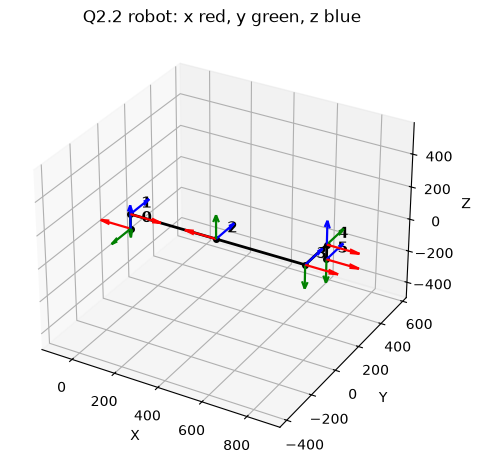

In [12]:
# ---------------- 2A INPUT ----------------
# rows (theta, d, a, alpha): angles in degrees, lengths in mm. q = 0 = the pose drawn in the figure.
ur = Robot([(180,  90,    0, -90),       # row 1                    <-- CHANGE
            (180,   0, -400,   0),       # row 2
            (180,   0,  400,   0),       # row 3
            (  0, 180,    0,  90),       # row 4
            (  0, -90,    0, -90)],      # row 5
           types='RRRRR', name='Q2.2 robot')
ur.show_table()
T_w0 = frame_matrix((0, 0, 0), x='-X', z='+Z')     # frame 0 in the figure: x0 = -X, z0 = +Z   <-- CHANGE
ur.print_frames(T_w0=T_w0)                          # compare each line with the figure
T05 = ur.fk()                                       # prints A1 ... A5 and T05 (in frame-0 axes)
ur.plot(T_w0=T_w0)

### 2B. Frames read off the figure → the DH table (Q2.2, the reverse way)
For each frame write `(origin, x axis, z axis)` in the figure's world axes. This is the fastest way to fill a DH grid: you only read *directions and positions*, and the code does all the angle and sign work.

In [13]:
# ---------------- 2B INPUT ----------------
# Q2.2: X = along the arm (away from the base), Y = sideways (direction of z1), Z = up. Origins in mm.
frames_q22 = [                                     # (origin, x axis, z axis)        <-- CHANGE
    ((  0,   0,  0), '-X', '+Z'),    # frame 0 at the base
    ((  0,   0, 90), '+X', '+Y'),    # frame 1: 90 mm above the base
    ((400,   0, 90), '-X', '+Y'),    # frame 2: end of the first 400 mm link
    ((800,   0, 90), '+X', '+Y'),    # frame 3: end of the second 400 mm link
    ((800, 180, 90), '+X', '+Z'),    # frame 4: 180 mm sideways
    ((800, 180,  0), '+X', '+Y'),    # frame 5: 90 mm down
]
table_q22 = dh_from_frames(frames_q22)
# Expected Q2.2: theta = 180,180,180,0,0 | d = 90,0,0,180,-90 | a = 0,-400,400,0,0 | alpha = -90,0,0,90,-90


DH table from the frames read off the figure

▶ row 1: frame 0 → frame 1
   · z0 = +Z, x0 = -X  |  z1 = +Y, x1 = +X
   · o1 - o0 = [ 0.  0. 90.]
   · θ1 = angle from x0 to x1 about z0  = 180°
   · d1 = (o1 - o0)·z0                 = 90
   · a1 = (o1 - o0)·x1                   = 0
   · α1 = angle from z0 to z1 about x1  = -90°

▶ row 2: frame 1 → frame 2
   · z1 = +Y, x1 = +X  |  z2 = +Y, x2 = -X
   · o2 - o1 = [400.   0.   0.]
   · θ2 = angle from x1 to x2 about z1  = 180°
   · d2 = (o2 - o1)·z1                 = 0
   · a2 = (o2 - o1)·x2                   = -400
   · α2 = angle from z1 to z2 about x2  = 0°

▶ row 3: frame 2 → frame 3
   · z2 = +Y, x2 = -X  |  z3 = +Y, x3 = +X
   · o3 - o2 = [400.   0.   0.]
   · θ3 = angle from x2 to x3 about z2  = 180°
   · d3 = (o3 - o2)·z2                 = 0
   · a3 = (o3 - o2)·x3                   = 400
   · α3 = angle from z2 to z3 about x3  = 0°

▶ row 4: frame 3 → frame 4
   · z3 = +Y, x3 = +X  |  z4 = +Z, x4 = +X
   · o4 - o3 = [  0. 180.   0

### 2C. One $A_i$ matrix → its DH parameters (exam 2016 P2)

In [14]:
# ---------------- 2C INPUT ----------------
r2 = 1 / np.sqrt(2)
dh_from_A([[1,  0,   0, 3],                     # <-- CHANGE: the given 4x4 matrix
           [0, r2, -r2, 0],
           [0, r2,  r2, 0],
           [0,  0,   0, 1]]);                    # expected θ = 0, d = 0, a = 3, α = 45°


DH parameters from one A matrix
   · θ = atan2(A21, A11) = atan2(0, 1) = 0°
   · α = atan2(A32, A33) = atan2(0.7071, 0.7071) = 45°
   · d = A34 = 0
   · a = A14 cosθ + A24 sinθ = 3
   · rebuilt A matches ✔ (a valid DH matrix)

✅ ANSWER: θ = 0°, d = 0, a = 3, α = 45°


### 2D. Symbolic forward kinematics and template robots from the lectures
Use symbols for the joint variables. Plain numbers in the table stay in degrees. Copy a template and change the numbers.

In [15]:
# ---------------- 2D INPUT ----------------
q1, q2, q3, q4, q5, q6 = sp.symbols('q1:7', real=True)            # joint variables (radians / lengths)
l1, l2, d1, a1, a2, d4 = sp.symbols('l1 l2 d1 a1 a2 d4', positive=True)

planar2R = Robot([(0, 0, l1, 0), (0, 0, l2, 0)], 'RR', name='planar 2R')
T02_sym = planar2R.fk([q1, q2])                 # x = l1 c1 + l2 c12, y = l1 s1 + l2 s12

# Templates (DH rows as on the slides; * = variable). Use them with numbers or symbols.
scara = Robot([(0, d1, a1, 0), (0, 0, a2, 180), (0, 0, 0, 0), (0, d4, 0, 0)], 'RRPR', name='SCARA')
cylindrical = Robot([(0, d1, 0, 0), (0, 0, 0, -90), (0, 0, 0, 0)], 'RPP', name='cylindrical RPP')
stanford = Robot([(0, 0, 0, -90), (0, sp.Rational(1, 10), 0, 90), (0, 0, 0, 0),
                  (0, 0, 0, -90), (0, 0, 0, 90), (0, 0, 0, 0)], 'RRPRRR', name='Stanford arm')
puma260 = Robot([(0, 350, 0, -90), (0, 0, 200, 0), (0, -50, 0, 0),
                 (0, 210, 0, 90), (0, 0, 0, 90), (0, 30, 0, 0)], 'RRRRRR', name='PUMA 260 (slide)')
elbow = Robot([(0, d1, 0, 90), (0, 0, a2, 0), (0, 0, l2, 0)], 'RRR', name='elbow RRR')

T_scara = scara.frames([q1, q2, q3, q4])[-1]; pm("T04 SCARA", T_scara)
o6_stanford = stanford.frames([q1, q2, q3, q4, q5, q6])[-1][:3, 3]
pm("Stanford tip position o6 (week 3 P1: c1 d3 s2 - 0.1 s1, d3 s1 s2 + 0.1 c1, c2 d3; here d3 = q3)", o6_stanford)
puma260.show_table()


forward kinematics of planar 2R:  T02 = A1 · A2 · ... · A2
A1 =


⎡cos(q₁)  -sin(q₁)  0  l₁⋅cos(q₁)⎤
⎢                                ⎥
⎢sin(q₁)  cos(q₁)   0  l₁⋅sin(q₁)⎥
⎢                                ⎥
⎢   0        0      1      0     ⎥
⎢                                ⎥
⎣   0        0      0      1     ⎦

A2 =


⎡cos(q₂)  -sin(q₂)  0  l₂⋅cos(q₂)⎤
⎢                                ⎥
⎢sin(q₂)  cos(q₂)   0  l₂⋅sin(q₂)⎥
⎢                                ⎥
⎢   0        0      1      0     ⎥
⎢                                ⎥
⎣   0        0      0      1     ⎦

T02 =


⎡cos(q₁ + q₂)  -sin(q₁ + q₂)  0  l₁⋅cos(q₁) + l₂⋅cos(q₁ + q₂)⎤
⎢                                                            ⎥
⎢sin(q₁ + q₂)  cos(q₁ + q₂)   0  l₁⋅sin(q₁) + l₂⋅sin(q₁ + q₂)⎥
⎢                                                            ⎥
⎢     0              0        1               0              ⎥
⎢                                                            ⎥
⎣     0              0        0               1              ⎦

... (2 outputs left out)

⎡cos(q₁ + q₂ - q₄)  sin(q₁ + q₂ - q₄)   0   a₁⋅cos(q₁) + a₂⋅cos(q₁ + q₂)⎤
⎢                                                                       ⎥
⎢sin(q₁ + q₂ - q₄)  -cos(q₁ + q₂ - q₄)  0   a₁⋅sin(q₁) + a₂⋅sin(q₁ + q₂)⎥
⎢                                                                       ⎥
⎢        0                  0           -1          d₁ - d₄ - q₃        ⎥
⎢                                                                       ⎥
⎣        0                  0           0                1              ⎦

Stanford tip position o6 (week 3 P1: c1 d3 s2 - 0.1 s1, d3 s1 s2 + 0.1 c1, c2 d3; here d3 = q3) =


⎡                     sin(q₁)⎤
⎢q₃⋅sin(q₂)⋅cos(q₁) - ───────⎥
⎢                       10   ⎥
⎢                            ⎥
⎢                     cos(q₁)⎥
⎢q₃⋅sin(q₁)⋅sin(q₂) + ───────⎥
⎢                       10   ⎥
⎢                            ⎥
⎣         q₃⋅cos(q₂)         ⎦

DH table of PUMA 260 (slide)  (angles in deg):
    i type |      theta |          d |          a |    alpha
    1    R |      0+q1* |        350 |          0 |      -90
    2    R |      0+q2* |          0 |        200 |        0
    3    R |      0+q3* |        -50 |          0 |        0
    4    R |      0+q4* |        210 |          0 |       90
    5    R |      0+q5* |          0 |          0 |       90
    6    R |      0+q6* |         30 |          0 |        0


---
# 3. Inverse kinematics (MCQ Q2.3)

### Theory in 60 seconds
* **Planar 2R** (links $a_1, a_2$, tip $(x,y)$):
  $\cos\theta_2=\dfrac{x^2+y^2-a_1^2-a_2^2}{2a_1a_2}$, $\;\theta_2=\text{atan2}(\pm\sqrt{1-\cos^2\theta_2},\cos\theta_2)$, $\;\theta_1=\text{atan2}(y,x)-\text{atan2}(a_2\sin\theta_2,\;a_1+a_2\cos\theta_2)$.
  Two answers: $\theta_2>0$ and $\theta_2<0$ (elbow on either side). **Pick the one that matches the figure**, not a sign rule. If $|\cos\theta_2|>1$ the point is out of reach.
* **Planar 3R with tool angle** $\varphi=\theta_1+\theta_2+\theta_3$: first remove the last link, $(x_w,y_w)=(x-a_3\cos\varphi,\;y-a_3\sin\varphi)$, solve 2R, then $\theta_3=\varphi-\theta_1-\theta_2$.
* **Elbow (articulated) arm** with wrist centre $(x_c,y_c,z_c)$: $\theta_1=\text{atan2}(y_c,x_c)$ (or $+180°$), $r=\sqrt{x_c^2+y_c^2}$, $s=z_c-d_1$, then the 2R formulas in the $(r,s)$ plane. Up to 4 answers.
* **Spherical wrist** (decoupling): wrist centre $o_c=o_6-d_6\,z_6$; orientation $R^3_6=(R^0_3)^TR^0_6$ → ZYZ Euler angles = $(\theta_4,\theta_5,\theta_6)$.
* **Always verify with forward kinematics.** Every solver here prints an FK check.

### Exam traps
* `atan2(y, x)` order. Degrees versus radians.
* "Elbow up / down" depends on the figure's frames: compare the drawn elbow position with each solution's elbow position (`fk_2r` prints both).

In [16]:
# =====================================================================
# 3. TOOLS: analytic IK (2R, 3R, elbow, 4-DoF, spherical wrist) and numerical IK
# =====================================================================

def fk_2r(t1, t2, a1, a2, deg=True):
    """Tip of a planar 2R arm: x = a1 c1 + a2 c12, y = a1 s1 + a2 s12."""
    c = np.deg2rad if deg else (lambda v: v)
    t1, t2 = c(t1), c(t2)
    return np.array([a1 * np.cos(t1) + a2 * np.cos(t1 + t2), a1 * np.sin(t1) + a2 * np.sin(t1 + t2)])


def ik_2r(x, y, a1, a2, deg=True, explain=None):
    """Planar 2R inverse kinematics: both solutions [(theta1, theta2) with theta2 > 0, then theta2 < 0]."""
    ex = _ex(explain)
    D = (x**2 + y**2 - a1**2 - a2**2) / (2 * a1 * a2)
    if ex:
        title(f"IK of a planar 2R arm: a1 = {num(a1)}, a2 = {num(a2)}, target (x, y) = ({num(x)}, {num(y)})")
        step("law of cosines: cos θ2 = (x² + y² - a1² - a2²) / (2 a1 a2)")
        note(f"= ({num(x)}² + {num(y)}² - {num(a1)}² - {num(a2)}²) / (2·{num(a1)}·{num(a2)}) = {D:.6f}")
    if abs(D) > 1 + 1e-12:
        answer(f"UNREACHABLE: |cos θ2| = {abs(D):.4f} > 1 (the target is outside the workspace)")
        return []
    D = float(np.clip(D, -1, 1))
    sols = []
    for sg in (+1, -1):
        t2 = np.arctan2(sg * np.sqrt(1 - D**2), D)
        k1, k2 = a1 + a2 * np.cos(t2), a2 * np.sin(t2)
        t1 = np.arctan2(y, x) - np.arctan2(k2, k1)
        sols.append((wrap180(np.degrees(t1)), float(np.degrees(t2))) if deg else
                    (float(np.arctan2(np.sin(t1), np.cos(t1))), float(t2)))
    if ex:
        step("θ2 = atan2(±sqrt(1 - cos²θ2), cos θ2)")
        note(f"θ2 = ±{num(abs(np.degrees(np.arccos(D))))}°")
        step("θ1 = atan2(y, x) - atan2(a2 sin θ2, a1 + a2 cos θ2)")
        for (t1d, t2d) in sols:
            t2r = np.radians(t2d) if deg else t2d
            sub = atan2d(a2 * np.sin(t2r), a1 + a2 * np.cos(t2r))
            note(f"θ2 = {num(t2d)}: θ1 = {num(atan2d(y, x))} - ({num(sub)}) = {num(t1d)}")
        step("FK check (must give the target) and where the elbow is")
        for (t1d, t2d) in sols:
            elbow_ = a1 * np.array([np.cos(np.radians(t1d) if deg else t1d), np.sin(np.radians(t1d) if deg else t1d)])
            note(f"(θ1, θ2) = ({num(t1d)}, {num(t2d)}): tip = {clean(fk_2r(t1d, t2d, a1, a2, deg))}, elbow at {clean(elbow_)}")
        note("pick the solution whose elbow matches the figure (elbow up / down)")
    answer(f"(θ1, θ2) = {tuple(round(v, 4) for v in sols[0])}  or  {tuple(round(v, 4) for v in sols[1])}"
           f"  [{'deg' if deg else 'rad'}]")
    return sols


def ik_3r_planar(x, y, phi, a1, a2, a3, explain=None):
    """Planar 3R with tool angle phi = theta1 + theta2 + theta3 (degrees).
    1) wrist point (x - a3 cos phi, y - a3 sin phi), 2) 2R IK, 3) theta3 = phi - theta1 - theta2."""
    ex = _ex(explain)
    xw, yw = x - a3 * np.cos(np.radians(phi)), y - a3 * np.sin(np.radians(phi))
    if ex:
        title(f"IK of a planar 3R arm with tool angle φ = {num(phi)}°")
        step("remove the last link: wrist point = (x - a3 cos φ, y - a3 sin φ)")
        note(f"= ({num(xw)}, {num(yw)})")
    sols2 = _quiet(ik_2r, xw, yw, a1, a2)
    sols = []
    for (t1, t2) in sols2:
        t3 = wrap180(phi - t1 - t2)
        sols.append((t1, t2, t3))
        if ex:
            p = fk_2r(t1, t2, a1, a2) + a3 * np.array([np.cos(np.radians(phi)), np.sin(np.radians(phi))])
            note(f"θ1 = {num(t1)}, θ2 = {num(t2)}, θ3 = φ - θ1 - θ2 = {num(t3)}  → FK tip = {clean(p)}")
    answer(" or ".join(str(tuple(round(v, 4) for v in sl)) for sl in sols) + "  [deg]")
    return sols


def ik_elbow(xc, yc, zc, d1, a2, a3, deg=True, explain=None):
    """Elbow manipulator RRR, DH (q1, d1, 0, 90), (q2, 0, a2, 0), (q3, 0, a3, 0). Up to 4 solutions.
    theta1 = atan2(yc, xc) or + 180°;  r = ±sqrt(xc² + yc²), s = zc - d1;
    cos theta3 = (r² + s² - a2² - a3²)/(2 a2 a3);  theta2 = atan2(s, r) - atan2(a3 s3, a2 + a3 c3)."""
    ex = _ex(explain)
    r2 = xc**2 + yc**2; s_ = zc - d1
    D = (r2 + s_**2 - a2**2 - a3**2) / (2 * a2 * a3)
    if ex:
        title(f"IK of the elbow arm for the wrist centre ({num(xc)}, {num(yc)}, {num(zc)})")
        note(f"r = sqrt(xc² + yc²) = {np.sqrt(r2):.4f},  s = zc - d1 = {num(s_)}")
        note(f"cos θ3 = (r² + s² - a2² - a3²)/(2 a2 a3) = {D:.6f}")
    if abs(D) > 1 + 1e-12:
        answer("UNREACHABLE (|cos θ3| > 1)")
        return []
    D = float(np.clip(D, -1, 1))
    rob = Robot([(0, d1, 0, 90), (0, 0, a2, 0), (0, 0, a3, 0)], 'RRR', deg=True)
    sols = []
    for t1, rs, side in ((np.arctan2(yc, xc), 1, "front"), (np.arctan2(yc, xc) + np.pi, -1, "back")):
        for sg in (1, -1):
            t3 = np.arctan2(sg * np.sqrt(1 - D**2), D)
            t2 = np.arctan2(s_, rs * np.sqrt(r2)) - np.arctan2(a3 * np.sin(t3), a2 + a3 * np.cos(t3))
            qd = wrap180(np.degrees([t1, t2, t3]))
            sols.append(qd if deg else np.radians(qd))
            if ex:
                note(f"{side}, θ3 {'>' if sg > 0 else '<'} 0: q = {clean(qd)}  → FK wrist = {clean(rob.frames(qd)[-1][:3, 3])}")
    answer("4 solutions (deg): " + " | ".join(str(clean(q_, 3)) for q_ in sols))
    return sols


def ik_4dof(x, y, z, pitch, d1, a2, a3, a4, q2_offset=0, explain=None):
    """4-DoF arm: base yaw + 3 pitch joints (the usual educational / project arm).
    DH: (q1, d1, 0, 90), (q2_offset + q2, 0, a2, 0), (q3, 0, a3, 0), (q4, 0, a4, 0).
    pitch = angle of the last link (tool) above the horizontal (degrees).
    q2_offset = the constant θ offset of row 2 (the DTU CourseBot has 90°: the arm points UP at q2 = 0).
    Method: q1 = atan2(y, x); in the vertical plane r = sqrt(x²+y²), s = z - d1;
            wrist = (r - a4 cos(pitch), s - a4 sin(pitch)) → 2R gives the link angles φ2 (from the
            horizontal) and q3 → q2 = φ2 - q2_offset, q4 = pitch - φ2 - q3.
            The 'reach back' family uses q1 + 180°, r → -r and pitch → 180° - pitch."""
    ex = _ex(explain)
    rob = Robot([(0, d1, 0, 90), (q2_offset, 0, a2, 0), (0, 0, a3, 0), (0, 0, a4, 0)], 'RRRR', name='4-DoF arm')
    if ex:
        title(f"IK of a 4-DoF arm: target ({num(x)}, {num(y)}, {num(z)}), tool pitch {num(pitch)}°")
    sols = []
    for fam, q1, rsign, pit in (("front", atan2d(y, x), 1, pitch), ("back", atan2d(y, x) + 180, -1, 180 - pitch)):
        r = rsign * np.hypot(x, y); s_ = z - d1
        rw, sw = r - a4 * np.cos(np.radians(pit)), s_ - a4 * np.sin(np.radians(pit))
        if ex:
            step(f"{fam} family: q1 = {num(wrap180(q1))}°, r = {num(r)}, s = z - d1 = {num(s_)}")
            note(f"wrist point (r - a4 cos ψ, s - a4 sin ψ) with ψ = {num(pit)}° → ({num(rw)}, {num(sw)})")
        for (q2, q3) in _quiet(ik_2r, rw, sw, a2, a3):       # q2 here = link-2 angle from the horizontal
            q4 = wrap180(pit - q2 - q3)
            qv = np.array([wrap180(q1), wrap180(q2 - q2_offset), q3, q4])
            T = rob.frames(qv)[-1]
            c1f, s1f = np.cos(np.radians(atan2d(y, x))), np.sin(np.radians(atan2d(y, x)))
            tool_dir = np.array([np.cos(np.radians(pitch)) * c1f, np.cos(np.radians(pitch)) * s1f, np.sin(np.radians(pitch))])
            ok = np.allclose(T[:3, 3], [x, y, z], atol=1e-6) and np.allclose(T[:3, 0], tool_dir, atol=1e-6)
            sols.append(qv)
            if ex:
                note(f"q = {clean(qv)}  → FK tip {clean(T[:3, 3])}, tool direction {'✔' if ok else '✘'}")
    answer("solutions (deg): " + " | ".join(str(clean(q_, 3)) for q_ in sols))
    return sols


def wrist_center(T06, d6, explain=None):
    """Wrist centre o_c = o_6 - d6 · z_6 (z_6 = third column of R06)."""
    T06 = np.asarray(T06, dtype=float)
    oc = T06[:3, 3] - d6 * T06[:3, 2]
    if _ex(explain):
        title("wrist centre:  o_c = o_6 - d6·z_6")
        note(f"o_6 = {clean(T06[:3, 3])}, z_6 = {clean(T06[:3, 2])}, d6 = {num(d6)}")
    answer(f"o_c = {clean(oc)}")
    return oc


def ik_spherical_wrist(R03, R06, explain=None):
    """theta4, theta5, theta6 of a standard spherical wrist = the ZYZ Euler angles of R36 = R03ᵀ R06."""
    R36 = np.asarray(R03, dtype=float).T @ np.asarray(R06, dtype=float)
    if _ex(explain):
        title("spherical wrist:  R36 = (R03)ᵀ R06 → ZYZ angles = (θ4, θ5, θ6)")
        pm("R36", R36)
    return zyz_from_R(R36, explain=explain)


def _jac_num(robot, q):
    """Numeric 6xn geometric Jacobian (Section 4 has the explained version, geometric_jacobian)."""
    Ts = robot.frames(q); on = Ts[-1][:3, 3]; J = np.zeros((6, robot.n))
    for i in range(robot.n):
        z, o = Ts[i][:3, 2], Ts[i][:3, 3]
        if robot.types[i] == 'R':
            J[:3, i] = np.cross(z, on - o); J[3:, i] = z
        else:
            J[:3, i] = z
    return J


def ik_numeric(robot, p_target, R_target=None, q0=None, n_starts=40, iters=300, tol=1e-9, seed=0, explain=None):
    """Numerical IK for ANY Robot: damped least squares (Newton steps with J) from many random starts.
    p_target : wanted tip position (3); R_target : optional wanted 3x3 orientation.
    Returns the distinct solutions found (revolute joints in degrees if robot.deg)."""
    ex = _ex(explain)
    rng = np.random.default_rng(seed)
    conv = DEG if robot.deg else 1.0
    p_target = np.asarray(p_target, dtype=float)
    reach = max(1.0, np.linalg.norm(p_target))
    starts = ([np.asarray(q0, dtype=float)] if q0 is not None else []) + [
        np.array([rng.uniform(-180, 180) / (1 if robot.deg else 1 / DEG) if ty == 'R' else rng.uniform(0, reach)
                  for ty in robot.types]) for _ in range(n_starts)]
    sols = []
    for qs in starts:
        q = qs.astype(float).copy()
        e = np.ones(3)
        for _ in range(iters):
            T = robot.frames(q)[-1]
            e = p_target - T[:3, 3]
            J = _jac_num(robot, q)
            if R_target is not None:
                Rc, Rt = T[:3, :3], np.asarray(R_target, dtype=float)
                e = np.r_[e, 0.5 * sum(np.cross(Rc[:, k], Rt[:, k]) for k in range(3))]
            else:
                J = J[:3]
            if np.linalg.norm(e) < tol:
                break
            lam = 1e-3 * reach
            dq = J.T @ np.linalg.solve(J @ J.T + lam**2 * np.eye(J.shape[0]), e)
            q = q + np.array([dqi / conv if ty == 'R' else dqi for dqi, ty in zip(dq, robot.types)])
        if np.linalg.norm(e) < 1e-6:
            qn = np.array([(wrap180(qi) if robot.deg else float(np.arctan2(np.sin(qi), np.cos(qi)))) if ty == 'R' else qi
                           for qi, ty in zip(q, robot.types)], dtype=float)
            if not any(np.allclose(qn, s_, atol=1e-3) for s_ in sols):
                sols.append(qn)
    if ex:
        title(f"numerical IK of {robot.name} for the target {clean(p_target)}")
        note(f"{len(starts)} random starts, damped least squares; {len(sols)} distinct solution(s) found")
        for q_ in sols:
            note(f"q = {clean(q_)} → FK tip {clean(robot.frames(q_)[-1][:3, 3])}")
    answer(f"{len(sols)} solution(s): " + " | ".join(str(clean(q_, 3)) for q_ in sols))
    return sols


Robot.ik_numeric = lambda self, *a, **k: ik_numeric(self, *a, **k)
print("Section 3 tools loaded ✔")

Section 3 tools loaded ✔


### 3A. Planar 2R arm (Q2.3, exam 2016 P4.5)

In [17]:
# ---------------- 3A INPUT ----------------
ik_2r(x=0, y=592.7, a1=391, a2=302)          # Q2.3: target (0, 592.7) mm, links 391 and 302 mm     <-- CHANGE
# Expected Q2.3 (figure: elbow down): θ1 = 63°, θ2 = 63°   (the other solution, 117° and -63°, is not an option)


IK of a planar 2R arm: a1 = 391, a2 = 302, target (x, y) = (0, 592.7)

▶ law of cosines: cos θ2 = (x² + y² - a1² - a2²) / (2 a1 a2)
   · = (0² + 592.7² - 391² - 302²) / (2·391·302) = 0.453957

▶ θ2 = atan2(±sqrt(1 - cos²θ2), cos θ2)
   · θ2 = ±63.0022°

▶ θ1 = atan2(y, x) - atan2(a2 sin θ2, a1 + a2 cos θ2)
   · θ2 = 63.0022: θ1 = 90 - (27.001) = 62.999
   · θ2 = -63.0022: θ1 = 90 - (-27.001) = 117.001

▶ FK check (must give the target) and where the elbow is
   · (θ1, θ2) = (62.999, 63.0022): tip = [  0.  592.7], elbow at [177.5162 348.3805]
   · (θ1, θ2) = (117.001, -63.0022): tip = [  0.  592.7], elbow at [-177.5162  348.3805]
   · pick the solution whose elbow matches the figure (elbow up / down)

✅ ANSWER: (θ1, θ2) = (62.999, 63.0022)  or  (117.001, -63.0022)  [deg]


[(62.99902757991492, 63.00215714621543), (117.00097242008508, -63.002157146215 ↪

↪ 43)]

In [18]:
ik_2r(x=0, y=-0.1, a1=0.1, a2=0.1);          # exam 2016 P4.5: l1 = l2 = 0.1 m, tip at (0, -0.1)


IK of a planar 2R arm: a1 = 0.1, a2 = 0.1, target (x, y) = (0, -0.1)

▶ law of cosines: cos θ2 = (x² + y² - a1² - a2²) / (2 a1 a2)
   · = (0² + -0.1² - 0.1² - 0.1²) / (2·0.1·0.1) = -0.500000

▶ θ2 = atan2(±sqrt(1 - cos²θ2), cos θ2)
   · θ2 = ±120°

▶ θ1 = atan2(y, x) - atan2(a2 sin θ2, a1 + a2 cos θ2)
   · θ2 = 120: θ1 = -90 - (60) = -150
   · θ2 = -120: θ1 = -90 - (-60) = -30

▶ FK check (must give the target) and where the elbow is
   · (θ1, θ2) = (-150, 120): tip = [ 0.  -0.1], elbow at [-0.0866 -0.05  ]
   · (θ1, θ2) = (-30, -120): tip = [ 0.  -0.1], elbow at [ 0.0866 -0.05  ]
   · pick the solution whose elbow matches the figure (elbow up / down)

✅ ANSWER: (θ1, θ2) = (-150.0, 120.0)  or  (-30.0, -120.0)  [deg]


### 3B. Planar 3R with a tool angle $\varphi$

In [19]:
# ---------------- 3B INPUT ----------------
ik_3r_planar(x=1.4784, y=1.8195, phi=45, a1=1, a2=1, a3=0.5);   # made from (30°, 45°, -30°)   <-- CHANGE


IK of a planar 3R arm with tool angle φ = 45°

▶ remove the last link: wrist point = (x - a3 cos φ, y - a3 sin φ)
   · = (1.1248, 1.4659)
   · θ1 = 30.0017, θ2 = 44.9973, θ3 = φ - θ1 - θ2 = -29.999  → FK tip = [1.4784 1.8195]
   · θ1 = 74.999, θ2 = -44.9973, θ3 = φ - θ1 - θ2 = 14.9983  → FK tip = [1.4784 1.8195]

✅ ANSWER: (30.0017, 44.9973, -29.999) or (74.999, -44.9973, 14.9983)  [deg]


### 3C. Elbow arm, wrist centre and spherical wrist (kinematic decoupling)
Example: build a target pose with known joint angles, then recover them. In the exam you are given `T06` directly.

In [20]:
# ---------------- 3C INPUT ----------------
d1_, a2_, a3_ = 0.3, 0.4, 0.35                                   # elbow arm dimensions [m]   <-- CHANGE
ik_elbow(xc=0.3, yc=0.2, zc=0.5, d1=d1_, a2=a2_, a3=a3_);         # wrist centre [m]            <-- CHANGE

# decoupling demo: a 6-DoF arm = the elbow arm + a spherical wrist (DH rows 4-6) with d6 = 0.1 m
arm6 = Robot([(0, d1_, 0, 90), (0, 0, a2_, 0), (90, 0, 0, 90), (0, a3_, 0, -90), (0, 0, 0, 90), (0, 0.1, 0, 0)],
             'RRRRRR', name='6R with spherical wrist')
q_true = [20, 30, -40, 10, 50, 60]
T06 = arm6.frames(q_true)[-1]                                     # pretend this is the given pose
oc = wrist_center(T06, d6=0.1)                                    # step 1: wrist centre (= origin of frames 4, 5)
ik_elbow(*oc, d1=d1_, a2=a2_, a3=a3_)                             # step 2: q1..q3 → one solution is (20, 30, -40)
R03 = arm6.frames(q_true)[3][:3, :3]                              # step 3: R03 from the chosen q1..q3
ik_spherical_wrist(R03, T06[:3, :3]);                             # step 4: (θ4, θ5, θ6) = (10, 50, 60) is one solution


IK of the elbow arm for the wrist centre (0.3, 0.2, 0.5)
   · r = sqrt(xc² + yc²) = 0.3606,  s = zc - d1 = 0.2
   · cos θ3 = (r² + s² - a2² - a3²)/(2 a2 a3) = -0.401786
   · front, θ3 > 0: q = [ 33.6901 -22.0008 113.6899]  → FK wrist = [0.3 0.2 0.5]
   · front, θ3 < 0: q = [  33.6901   80.0351 -113.6899]  → FK wrist = [0.3 0.2 0.5]
   · back, θ3 > 0: q = [-146.3099   99.9649  113.6899]  → FK wrist = [0.3 0.2 0.5]
   · back, θ3 < 0: q = [-146.3099 -157.9992 -113.6899]  → FK wrist = [0.3 0.2 0.5]

✅ ANSWER: 4 solutions (deg): [ 33.69  -22.001 113.69 ] | [  33.69    80.035 -113.69 ] | [-146.31    99.965  113.69 ] | [-146.31  -157.999 -113.69 ]

wrist centre:  o_c = o_6 - d6·z_6
   · o_6 = [0.7258 0.25   0.5024], z_6 = [0.7634 0.1363 0.6313], d6 = 0.1

✅ ANSWER: o_c = [0.6494 0.2364 0.4392]

IK of the elbow arm for the wrist centre (0.6494, 0.2364, 0.4392)
   · r = sqrt(xc² + yc²) = 0.6911,  s = zc - d1 = 0.1392
   · cos θ3 = (r² + s² - a2² - a3²)/(2 a2 a3) = 0.766044
   · front, θ3 > 0: 

### 3D. A 4-DoF arm: base yaw + 3 pitch joints (the project / CourseBot style)
Give the target point and the wanted tool pitch (the angle of the last link above the horizontal). The numbers below are only an example; use your own robot's dimensions.

In [21]:
# ---------------- 3D INPUT ----------------
sols_4dof = ik_4dof(x=150, y=50, z=120, pitch=-30, d1=50, a2=100, a3=100, a4=50)   # mm and degrees   <-- CHANGE


IK of a 4-DoF arm: target (150, 50, 120), tool pitch -30°

▶ front family: q1 = 18.4349°, r = 158.1139, s = z - d1 = 70
   · wrist point (r - a4 cos ψ, s - a4 sin ψ) with ψ = -30° → (114.8126, 95)
   · q = [  18.4349   -2.2268   83.6647 -111.4379]  → FK tip [150.  50. 120.], tool direction ✔
   · q = [ 18.4349  81.4379 -83.6647 -27.7732]  → FK tip [150.  50. 120.], tool direction ✔

▶ back family: q1 = -161.5651°, r = -158.1139, s = z - d1 = 70
   · wrist point (r - a4 cos ψ, s - a4 sin ψ) with ψ = 210° → (-114.8126, 95)
   · q = [-161.5651   98.5621   83.6647   27.7732]  → FK tip [150.  50. 120.], tool direction ✔
   · q = [-161.5651 -177.7732  -83.6647  111.4379]  → FK tip [150.  50. 120.], tool direction ✔

✅ ANSWER: solutions (deg): [  18.435   -2.227   83.665 -111.438] | [ 18.435  81.438 -83.665 -27.773] | [-161.565   98.562   83.665   27.773] | [-161.565 -177.773  -83.665  111.438]


### 3E. Numerical IK for any robot in DH form
When no formula is obvious: give the DH table and the target, and let it find every solution (position only, or position and orientation).

In [22]:
# ---------------- 3E INPUT ----------------
two_r = Robot([(0, 0, 391, 0), (0, 0, 302, 0)], 'RR', name='Q2.3 arm')   # <-- CHANGE: your DH table
two_r.ik_numeric([0, 592.7, 0]);                                          # <-- CHANGE: target (x, y, z)


numerical IK of Q2.3 arm for the target [  0.  592.7   0. ]
   · 40 random starts, damped least squares; 2 distinct solution(s) found
   · q = [62.999  63.0022] → FK tip [  0.  592.7   0. ]
   · q = [117.001  -63.0022] → FK tip [  0.  592.7   0. ]

✅ ANSWER: 2 solution(s): [62.999 63.002] | [117.001 -63.002]


---
# 4. Velocity kinematics and the Jacobian (MCQ Q3.1)

### Theory in 60 seconds
* $\xi=\begin{bmatrix}v\\\omega\end{bmatrix}=J(q)\,\dot q$, with $J$ of size $6\times n$ (rows 1–3: $J_v$, rows 4–6: $J_\omega$).
* Column $i$: **revolute** $\begin{bmatrix}z_{i-1}\times(o_n-o_{i-1})\\ z_{i-1}\end{bmatrix}$, **prismatic** $\begin{bmatrix}z_{i-1}\\0\end{bmatrix}$. Here $z_{i-1}$ = column 3 of $T^0_{i-1}$ and $o_{i-1}$ = column 4.
* **A point other than the tip** (a centre of mass, a "point A"): use that point instead of $o_n$, and set the columns of the joints *after* its link to zero.
* Inverse: square $J$ → $\dot q=J^{-1}\xi$; redundant → $J^+=J^T(JJ^T)^{-1}$ (plus a null-space term $(I-J^+J)b$); tall → least squares.
* **Singular** where $\det J=0$ (rank drops). Planar 2R: $\det J_v=a_1a_2\sin\theta_2$ → stretched or folded arm.
* **Statics:** $\tau=J^TF$ (joint torques that hold a tip force $F$). A gravity load is a force at each centre of mass.
* Free vectors change frame with $R$ only: $v^0=R^0_1v^1$. A twist uses $\text{diag}(R,R)$.

### Exam traps
* Rates in **rad/s**, not deg/s.
* In a grid "$v_A$ for each $\dot\theta$", the products are easy; the trap is mixing up the columns. `apply_jacobian` prints every product.
* For a planar 2R, column 1 of $J_v$ is $(-y_{tip},\,x_{tip})$. Use it to read the pose from a given $J$ (cell 4B).

In [23]:
# =====================================================================
# 4. TOOLS: geometric Jacobian, point Jacobian, inverse velocity, singularities, statics
# =====================================================================

def geometric_jacobian(robot, q=None, explain=None):
    """6 x n geometric Jacobian of the tip of `robot` at joint values q (numbers or symbols).
    Column i:  revolute  → [z_{i-1} × (o_n - o_{i-1}) ; z_{i-1}]
               prismatic → [z_{i-1} ; 0]
    z_{i-1}, o_{i-1} = columns 3 and 4 of T^0_{i-1} (from forward kinematics)."""
    ex = _ex(explain)
    Ts = robot.frames(q)
    sym = isinstance(Ts[-1], sp.MatrixBase)
    n = robot.n
    on = Ts[-1][:3, 3]
    J = sp.zeros(6, n) if sym else np.zeros((6, n))
    if ex:
        title(f"geometric Jacobian of {robot.name} (6 x {n}):  ξ = [v; ω] = J q̇")
        if not sym:
            note(f"o{n} (the tip) = {clean(on)}")
    for i in range(n):
        z, o = Ts[i][:3, 2], Ts[i][:3, 3]
        if robot.types[i] == 'R':
            Jv = z.cross(on - o) if sym else np.cross(z, on - o)
            Jw = z
        else:
            Jv = z
            Jw = sp.zeros(3, 1) if sym else np.zeros(3)
        J[:3, i] = Jv
        J[3:, i] = Jw
        if ex and not sym:
            if robot.types[i] == 'R':
                step(f"column {i+1}: joint {i+1} is REVOLUTE → [z{i} × (o{n} - o{i}) ; z{i}]")
                note(f"z{i} = {clean(z)},  o{i} = {clean(o)},  o{n} - o{i} = {clean(on - o)}")
                note(f"z{i} × (o{n} - o{i}) = {clean(Jv)}")
            else:
                step(f"column {i+1}: joint {i+1} is PRISMATIC → [z{i} ; 0]")
                note(f"z{i} = {clean(z)}")
    if sym:
        J = sp.simplify(J)
    if ex:
        pm("J", J)
        note("rows 1-3 = J_v (linear velocity), rows 4-6 = J_ω (angular velocity); q̇ in rad/s or length/s")
    return J


def point_jacobian(robot, link, p_local=(0, 0, 0), q=None, explain=None):
    """6 x n Jacobian of a point fixed on link `link` (1..n), given in that link's frame coordinates.
    Example: centre of the 2nd link of a planar arm with a2 = 1 → point_jacobian(rob, 2, (-0.5, 0, 0)),
    because frame 2 sits at the END of link 2. Columns of the joints after `link` are zero."""
    ex = _ex(explain)
    Ts = robot.frames(q)
    sym = isinstance(Ts[-1], sp.MatrixBase)
    Tl = Ts[link]
    p = (Tl * sp.Matrix([*p_local, 1]))[:3, 0] if sym else (Tl @ np.r_[np.asarray(p_local, dtype=float), 1])[:3]
    J = sp.zeros(6, robot.n) if sym else np.zeros((6, robot.n))
    for i in range(link):
        z, o = Ts[i][:3, 2], Ts[i][:3, 3]
        if robot.types[i] == 'R':
            J[:3, i] = z.cross(p - o) if sym else np.cross(z, p - o)
            J[3:, i] = z
        else:
            J[:3, i] = z
    if sym:
        J = sp.simplify(J)
    if ex:
        title(f"Jacobian of a point on link {link} of {robot.name}")
        pm("point position p (frame 0)", p if sym else clean(p))
        note(f"columns 1..{link} use p instead of the tip; columns {link+1}..{robot.n} are zero")
        pm("J_point", J)
    return J


def jacobian_from_expr(p_expr, q_syms, explain=None):
    """Analytic Jacobian by differentiation: J = d p / d q (p = a sympy vector of positions)."""
    J = sp.simplify(sp.Matrix(p_expr).jacobian(list(q_syms)))
    if _ex(explain):
        title("analytic Jacobian  J = ∂p/∂q")
        pm("J", J)
    return J


def apply_jacobian(J, qdot, explain=None):
    """ξ = J · q̇, printing every row as a sum of products (to compare with a grid of options)."""
    ex = _ex(explain)
    J = np.atleast_2d(np.asarray(J, dtype=float)); qd = np.asarray(qdot, dtype=float)
    v = J @ qd
    if ex:
        title(f"J · q̇ for q̇ = {clean(qd)}")
        for r in range(J.shape[0]):
            terms = " + ".join(f"({num(J[r, j])})({num(qd[j])})" for j in range(J.shape[1]))
            print(f"   row {r+1}: {terms} = {num(v[r])}")
    answer(f"for q̇ = {clean(qd)}:  J q̇ = {clean(v)}")
    return v


def joint_rates(J, xi, b=None, explain=None):
    """Solve J q̇ = ξ for the joint rates.
    square and invertible J → q̇ = J⁻¹ ξ.  Otherwise the Moore-Penrose pseudo-inverse J⁺ (what the slides use):
      wide J (redundant)            → J⁺ = Jᵀ (J Jᵀ)⁻¹, the smallest q̇ that gives ξ  (+ (I - J⁺J) b, self-motion)
      tall J / rank-deficient J     → J⁺ from the SVD: least squares, exact when ξ is reachable
    (e.g. the lecture's ball catcher: a 6x4 J with rank 3 because the arm is planar)."""
    ex = _ex(explain)
    J = np.atleast_2d(np.asarray(J, dtype=float)); xi = np.asarray(xi, dtype=float)
    m, n = J.shape
    rank = int(np.linalg.matrix_rank(J))
    if ex:
        title(f"joint rates for the wanted velocity ξ = {clean(xi)}")
        note(f"J is {m}x{n} with rank {rank}")
    if m == n and rank == n:
        if ex:
            note(f"square and invertible: q̇ = J⁻¹ ξ,   det J = {np.linalg.det(J):.6g}")
        qd = np.linalg.solve(J, xi)
    else:
        Jp = np.linalg.pinv(J)
        qd = Jp @ xi
        if b is not None:
            qd = qd + (np.eye(n) - Jp @ J) @ np.asarray(b, dtype=float)
        if ex:
            kind = ("redundant (more joints than independent task rows)" if rank < n else "more task rows than joints")
            note(f"{kind} → pseudo-inverse q̇ = J⁺ ξ" + (" + (I - J⁺J) b" if b is not None else "")
                 + ("   ⚠ J is singular here" if m == n else ""))
    check = J @ qd
    if ex:
        note(f"check J q̇ = {clean(check)}  {'✔ = ξ' if np.allclose(check, xi, atol=1e-6) else '✘ ξ is NOT reachable exactly'}")
    answer(f"q̇ = {clean(qd)}  [rad/s for revolute joints]")
    return qd


def jacobian_numbers(J, explain=None):
    """det (square J), rank, singular values, condition number and manipulability sqrt(det(J Jᵀ))."""
    J = np.atleast_2d(np.asarray(J, dtype=float))
    sv = np.linalg.svd(J, compute_uv=False)
    rank = int(np.sum(sv > 1e-9 * max(1.0, sv.max())))
    manip = float(np.sqrt(max(0.0, np.linalg.det(J @ J.T)))) if J.shape[0] <= J.shape[1] else float(np.prod(sv))
    out = dict(rank=rank, singular_values=sv, condition=(sv.max() / sv.min() if sv.min() > 1e-12 else np.inf),
               manipulability=manip)
    if J.shape[0] == J.shape[1]:
        out["det"] = float(np.linalg.det(J))
    if _ex(explain):
        title("numbers of a Jacobian")
        for k, v in out.items():
            note(f"{k} = {clean(v) if isinstance(v, np.ndarray) else (num(v) if np.isfinite(v) else 'inf')}")
        note("singular configuration ⇔ rank drops (det = 0, condition number → ∞, manipulability = 0)")
    answer(f"rank {rank}" + (f", det J = {out['det']:.6g}" if 'det' in out else "") + f", manipulability {manip:.6g}")
    return out


def singularities(J, q_syms, explain=None):
    """Symbolic singularities: det(J) for a square J, else det(J Jᵀ); factorised and solved = 0."""
    J = sp.Matrix(J)
    d = sp.simplify(J.det() if J.shape[0] == J.shape[1] else (J * J.T).det())
    fd = sp.factor(sp.trigsimp(d))
    if _ex(explain):
        title("singularities: where det J = 0")
        pm("det", fd)
    try:
        sol = sp.solve(fd, list(q_syms), dict=True)
    except Exception as e:                      # some determinants have no closed-form roots
        sol = f"solve failed ({e}); look at the factors above"
    answer(f"det = {fd} = 0  →  {sol}")
    return fd


def statics(J, F, explain=None):
    """Joint torques/forces that balance a wrench F at the tip:  τ = Jᵀ F.
    F has the same number of rows as J (planar J_v: (Fx, Fy); full J: (Fx, Fy, Fz, Mx, My, Mz))."""
    ex = _ex(explain)
    J = np.atleast_2d(np.asarray(J, dtype=float)); F = np.asarray(F, dtype=float)
    tau = J.T @ F
    if ex:
        title(f"statics  τ = Jᵀ F  for F = {clean(F)}")
        for j in range(J.shape[1]):
            terms = " + ".join(f"({num(J[r, j])})({num(F[r])})" for r in range(J.shape[0]))
            print(f"   τ{j+1} = {terms} = {num(tau[j])}")
    answer(f"τ = {clean(tau)}  [N·m for revolute joints, N for prismatic]")
    return tau


def gravity_torques(robot, q, masses, coms_local, g_vec=(0, 0, -9.81), explain=None):
    """Static motor torques that hold the arm still against gravity (project part 3):
        τ = - Σ_i J_v,ci(q)ᵀ · (m_i g)       (= g(q) of the dynamics)
    masses     : [m1, ..., mn]
    coms_local : centre of mass of each link in its OWN frame {i}, e.g. (-a_i/2, 0, 0) for a link of length a_i
    g_vec      : gravity in frame 0 (default -Z)."""
    ex = _ex(explain)
    g_vec = np.asarray(g_vec, dtype=float)
    tau = np.zeros(robot.n)
    if ex:
        title("gravity load on the joints:  τ = - Σ J_v,ciᵀ (m_i g)")
    for i, (m, c) in enumerate(zip(masses, coms_local), 1):
        Jc = _quiet(point_jacobian, robot, i, c, q)[:3]
        ti = -Jc.T @ (m * g_vec)
        tau += ti
        if ex:
            note(f"link {i} (m = {num(m)}): contributes {clean(ti)}")
    answer(f"τ_gravity = {clean(tau)}")
    return tau


def geometry_from_planar_J(Jv, explain=None):
    """Read the pose of a planar 2R arm from its 2x2 J_v (exam Q3.1 trick):
        column 1 = (-y_tip, x_tip)  → tip position
        column 2 = (-(y_tip - y_elbow), x_tip - x_elbow)  → elbow position, then the link lengths."""
    J = np.asarray(Jv, dtype=float)
    tip = np.array([J[1, 0], -J[0, 0]])
    elbow = tip - np.array([J[1, 1], -J[0, 1]])
    a1, a2 = np.linalg.norm(elbow), np.linalg.norm(tip - elbow)
    if _ex(explain):
        title("planar 2R pose from J_v")
        note(f"tip   = (J21, -J11) = {clean(tip)}")
        note(f"elbow = tip - (J22, -J12) = {clean(elbow)}")
        note(f"a1 = |elbow| = {a1:.4f},  a2 = |tip - elbow| = {a2:.4f}")
        note(f"θ1 = atan2(elbow) = {atan2d(elbow[1], elbow[0]):.4f}°,  θ1 + θ2 = {atan2d(*(tip - elbow)[::-1]):.4f}°")
    answer(f"tip {clean(tip)}, elbow {clean(elbow)}, a1 = {a1:.4f}, a2 = {a2:.4f}")
    return tip, elbow, a1, a2


def twist_to_frame(R, xi):
    """Change the frame of a 6-vector twist (or wrench) [v; ω]:  [R v; R ω] = diag(R, R) ξ."""
    R = np.asarray(R, dtype=float)[:3, :3]; xi = np.asarray(xi, dtype=float)
    return np.r_[R @ xi[:3], R @ xi[3:]]


Robot.jacobian = lambda self, q=None, explain=None: geometric_jacobian(self, q, explain)
Robot.point_jacobian = lambda self, link, p_local=(0, 0, 0), q=None, explain=None: point_jacobian(self, link, p_local, q, explain)
print("Section 4 tools loaded ✔")

Section 4 tools loaded ✔


### 4A. Apply a given Jacobian, or invert it (Q3.1)

In [24]:
# ---------------- 4A INPUT ----------------
Jv_q31 = np.array([[-0.597, -0.244],                 # the given J_v [m/rad]                <-- CHANGE
                   [ 0.000, -0.178]])
for qd_option in [(1, 1), (1, -1), (1.371, -3.354), (-0.409, 0)]:    # the joint rates in the grid  <-- CHANGE
    apply_jacobian(Jv_q31, qd_option, explain=False)
# Expected Q3.1: (-0.841, -0.178) | (-0.353, 0.178) | (0, 0.597) | (0.244, 0)
joint_rates(Jv_q31, [0, 0.597]);                     # which q̇ gives a pure y-velocity of 0.597 m/s?


✅ ANSWER: for q̇ = [1. 1.]:  J q̇ = [-0.841 -0.178]

✅ ANSWER: for q̇ = [ 1. -1.]:  J q̇ = [-0.353  0.178]

✅ ANSWER: for q̇ = [ 1.371 -3.354]:  J q̇ = [-0.0001  0.597 ]

✅ ANSWER: for q̇ = [-0.409  0.   ]:  J q̇ = [0.2442 0.    ]

joint rates for the wanted velocity ξ = [0.    0.597]
   · J is 2x2 with rank 2
   · square and invertible: q̇ = J⁻¹ ξ,   det J = 0.106266
   · check J q̇ = [0.    0.597]  ✔ = ξ

✅ ANSWER: q̇ = [ 1.3708 -3.3539]  [rad/s for revolute joints]


### 4B. Read the arm's pose back from a given planar $J_v$

In [25]:
# ---------------- 4B INPUT ----------------
geometry_from_planar_J(Jv_q31);                      # tip (0, 0.597), elbow (0.178, 0.353)


planar 2R pose from J_v
   · tip   = (J21, -J11) = [0.    0.597]
   · elbow = tip - (J22, -J12) = [0.178 0.353]
   · a1 = |elbow| = 0.3953,  a2 = |tip - elbow| = 0.3020
   · θ1 = atan2(elbow) = 63.2405°,  θ1 + θ2 = 126.1111°

✅ ANSWER: tip [0.    0.597], elbow [0.178 0.353], a1 = 0.3953, a2 = 0.3020


### 4C. The Jacobian from a DH table (numeric, explained) and the numbers of $J$

In [26]:
# ---------------- 4C INPUT ----------------
arm2 = Robot([(0, 0, 0.1, 0), (0, 0, 0.1, 0)], 'RR', name='2R arm, 0.1 m links')   # <-- CHANGE
J_arm2 = arm2.jacobian([60, 60])                                                    # <-- CHANGE: q in degrees
jacobian_numbers(J_arm2[:2]);                        # the planar 2x2 part J_v (rows x, y)


geometric Jacobian of 2R arm, 0.1 m links (6 x 2):  ξ = [v; ω] = J q̇
   · o2 (the tip) = [0.     0.1732 0.    ]

▶ column 1: joint 1 is REVOLUTE → [z0 × (o2 - o0) ; z0]
   · z0 = [0. 0. 1.],  o0 = [0. 0. 0.],  o2 - o0 = [0.     0.1732 0.    ]
   · z0 × (o2 - o0) = [-0.1732  0.      0.    ]

▶ column 2: joint 2 is REVOLUTE → [z1 × (o2 - o1) ; z1]
   · z1 = [0. 0. 1.],  o1 = [0.05   0.0866 0.    ],  o2 - o1 = [-0.05    0.0866  0.    ]
   · z1 × (o2 - o1) = [-0.0866 -0.05    0.    ]
J =
[[-0.1732 -0.0866]
 [ 0.     -0.05  ]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 1.      1.    ]]
   · rows 1-3 = J_v (linear velocity), rows 4-6 = J_ω (angular velocity); q̇ in rad/s or length/s

numbers of a Jacobian
   · rank = 2
   · singular_values = [0.195  0.0444]
   · condition = 4.3911
   · manipulability = 0.0087
   · det = 0.0087
   · singular configuration ⇔ rank drops (det = 0, condition number → ∞, manipulability = 0)

✅ ANSWER: rank 2, det J = 0.00866025, manipulability 0.

### 4D. Symbolic Jacobians, singularities, the Jacobian of a point

In [27]:
# ---------------- 4D INPUT ----------------
J_2r_sym = planar2R.jacobian([q1, q2])               # planar 2R with links l1, l2
singularities(J_2r_sym[:2, :], [q1, q2])             # det = l1 l2 sin(q2) → q2 = 0 or π

J_cyl = cylindrical.jacobian([q1, q2, q3])           # week 4 P3: [[-d3 c1, 0, -s1], [-d3 s1, 0, c1], [0, 1, 0], ...]

l3 = sp.symbols('l3', positive=True)
planar3R = Robot([(0, 0, l1, 0), (0, 0, l2, 0), (0, 0, l3, 0)], 'RRR', name='planar 3R')
J_mid2 = planar3R.point_jacobian(2, (-l2 / 2, 0, 0), [q1, q2, q3]);   # week 4 P2: centre of link 2


geometric Jacobian of planar 2R (6 x 2):  ξ = [v; ω] = J q̇


J =


⎡-l₁⋅sin(q₁) - l₂⋅sin(q₁ + q₂)  -l₂⋅sin(q₁ + q₂)⎤
⎢                                               ⎥
⎢l₁⋅cos(q₁) + l₂⋅cos(q₁ + q₂)   l₂⋅cos(q₁ + q₂) ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎣              1                       1        ⎦

   · rows 1-3 = J_v (linear velocity), rows 4-6 = J_ω (angular velocity); q̇ in rad/s or length/s

singularities: where det J = 0
det =


l₁⋅l₂⋅sin(q₂)


✅ ANSWER: det = l1*l2*sin(q2) = 0  →  [{q2: 0}, {q2: pi}]

geometric Jacobian of cylindrical RPP (6 x 3):  ξ = [v; ω] = J q̇
J =


... (2 outputs left out)


Jacobian of a point on link 2 of planar 3R
point position p (frame 0) =


⎡             l₂⋅cos(q₁ + q₂)⎤
⎢l₁⋅cos(q₁) + ───────────────⎥
⎢                    2       ⎥
⎢                            ⎥
⎢             l₂⋅sin(q₁ + q₂)⎥
⎢l₁⋅sin(q₁) + ───────────────⎥
⎢                    2       ⎥
⎢                            ⎥
⎣             0              ⎦

   · columns 1..2 use p instead of the tip; columns 3..3 are zero
J_point =


⎡              l₂⋅sin(q₁ + q₂)  -l₂⋅sin(q₁ + q₂)    ⎤
⎢-l₁⋅sin(q₁) - ───────────────  ─────────────────  0⎥
⎢                     2                 2           ⎥
⎢                                                   ⎥
⎢             l₂⋅cos(q₁ + q₂)    l₂⋅cos(q₁ + q₂)    ⎥
⎢l₁⋅cos(q₁) + ───────────────    ───────────────   0⎥
⎢                    2                  2           ⎥
⎢                                                   ⎥
⎢              0                        0          0⎥
⎢                                                   ⎥
⎢              0                        0          0⎥
⎢                                                   ⎥
⎢              0                        0          0⎥
⎢                                                   ⎥
⎣              1                        1          0⎦

### 4E. Statics $\tau=J^TF$ and the gravity load on the motors

In [28]:
# ---------------- 4E INPUT ----------------
statics(J_arm2[:2], [0, 10])                        # torques that hold a 10 N force in +y at the tip   <-- CHANGE
arm2_vertical = Robot([(0, 0, 0.1, 0), (0, 0, 0.1, 0)], 'RR', name='2R in a vertical plane')
gravity_torques(arm2_vertical, [30, 20], masses=[0.5, 0.3],          # kg                             <-- CHANGE
                coms_local=[(-0.05, 0, 0), (-0.05, 0, 0)],           # centres of mass in each link frame
                g_vec=(0, -9.81, 0));                                # gravity along -y in this plane


statics  τ = Jᵀ F  for F = [ 0. 10.]
   τ1 = (-0.1732)(0) + (0)(10) = 0
   τ2 = (-0.0866)(0) + (-0.05)(10) = -0.5

✅ ANSWER: τ = [ 0.  -0.5]  [N·m for revolute joints, N for prismatic]

gravity load on the joints:  τ = - Σ J_v,ciᵀ (m_i g)
   · link 1 (m = 0.5): contributes [0.2124 0.    ]
   · link 2 (m = 0.3): contributes [0.3495 0.0946]

✅ ANSWER: τ_gravity = [0.5619 0.0946]


### 4F. A velocity in another frame (week 4 P1, exam 2016 P4.2)

In [29]:
# ---------------- 4F INPUT ----------------
R01_w4 = [[0, -1, 0], [1, 0, 0], [0, 0, 1]]
transform_vector(R01_w4, [3, 1, 0])                  # week 4 P1: v0 = (-1, 3, 0)
transform_vector(arm2.frames([60, 60])[-1], [0.5, 0.5, 0]);   # 2016 P4.2: (-0.683, 0.183, 0)


free vector from frame 1 to frame 0:  v0 = R v1
   · v1 = [3, 1, 0] (a vector → only rotated, the origin does not matter)

✅ ANSWER: v0 = [-1.  3.  0.]

free vector from frame 1 to frame 0:  v0 = R v1
   · v1 = [0.5, 0.5, 0] (a vector → only rotated, the origin does not matter)

✅ ANSWER: v0 = [-0.683  0.183  0.   ]


---
# 5. Trajectory planning (MCQ Q3.2)

### Theory in 60 seconds
* A polynomial with $k$ conditions has $k$ coefficients: **cubic** = 4 ($q,\dot q$ at both ends), **quintic** = 6 ($q,\dot q,\ddot q$ at both ends).
* Every condition $q^{(m)}(t_k)=$ value is one row of a linear system $M\,c=b$. That is what `poly_from_conditions` solves, and it prints every row.
* **Shortcut when $t_0=0$:** $c_0=q_0$, $c_1=v_0$, $c_2=a_0/2$ straight away. For a quintic only a $3\times3$ system is left:
$\begin{bmatrix}T^3&T^4&T^5\\3T^2&4T^3&5T^4\\6T&12T^2&20T^3\end{bmatrix}\begin{bmatrix}c_3\\c_4\\c_5\end{bmatrix}=\begin{bmatrix}q_f-c_0-c_1T-c_2T^2\\v_f-c_1-2c_2T\\a_f-2c_2\end{bmatrix}$
* Cubic from rest to rest: $q=q_0+\Delta(3\tau^2-2\tau^3)$, peak speed $1.5\Delta/T$. Quintic from rest to rest: $q_0+\Delta(10\tau^3-15\tau^4+6\tau^5)$, peak speed $1.875\Delta/T$.
* **LSPB** (trapezoidal velocity): blend time $t_b=\dfrac{q_0-q_f+Vt_f}{V}$, valid if $\dfrac{|\Delta|}{t_f}<|V|\le\dfrac{2|\Delta|}{t_f}$. Velocity is continuous; the acceleration jumps.

### Exam traps
* Non-zero start time $t_0$: the shortcut does not apply. `poly_from_conditions` handles any $t_0$.
* Units: $\pi/4$ rad, not 45. Check the end conditions with the printed **check** lines.

In [30]:
# =====================================================================
# 5. TOOLS: polynomials from conditions, cubic/quintic, via points, LSPB, constant jerk
# =====================================================================
_DER = ["q", "q'", "q''", "q'''", "q''''"]          # names of the derivatives


def poly_string(c, var='t', dec=4):
    """Readable polynomial: 0.7854 - 1.982 t^3 + ..."""
    terms = []
    for j, cj in enumerate(c):
        if abs(cj) < 1e-12:
            continue
        mono = "" if j == 0 else (var if j == 1 else f"{var}^{j}")
        terms.append(f"{cj:.{dec}g}" + (f" {mono}" if mono else ""))
    return " + ".join(terms).replace("+ -", "- ") if terms else "0"


def poly_eval(c, tt, k=0):
    """k-th derivative of the polynomial c0 + c1 t + ... at time(s) tt."""
    p = np.polynomial.polynomial.Polynomial(c)
    return p.deriv(k)(tt) if k else p(tt)


def poly_from_conditions(conds, explain=None):
    """Polynomial q(t) = c0 + c1 t + ... + c_{k-1} t^{k-1} through k conditions.
    conds : list of (t_k, m, value) meaning  (d^m q / dt^m)(t_k) = value
            m = 0 position, 1 velocity, 2 acceleration, 3 jerk.
    Row of M for a condition: entry j = j!/(j-m)! · t^(j-m) for j >= m (the m-th derivative of t^j)."""
    ex = _ex(explain)
    n = len(conds)
    M = np.zeros((n, n)); b = np.zeros(n)
    for r, (tk, m, val) in enumerate(conds):
        for j in range(m, n):
            M[r, j] = factorial(j) / factorial(j - m) * tk ** (j - m)
        b[r] = val
    c = np.linalg.solve(M, b)
    if ex:
        title(f"polynomial of degree {n-1} through {n} conditions")
        note("q(t) = " + " + ".join(["c0"] + [f"c{j} t" if j == 1 else f"c{j} t^{j}" for j in range(1, n)]))
        step("each condition is one row of  M · c = b   (columns = c0, c1, c2, ...)")
        for r, (tk, m, val) in enumerate(conds):
            lab = f"{_DER[m]}({num(tk)})"
            print(f"   {lab:>9} = {num(val):>8}   →   [{', '.join(num(x) for x in M[r])}]")
        step("solve M c = b")
        for j, cj in enumerate(c):
            print(f"   c{j} = {cj: .6g}")
        note("q(t) = " + poly_string(c))
        step("check every condition")
        for (tk, m, val) in conds:
            got = poly_eval(c, tk, m)
            lab = f"{_DER[m]}({num(tk)})"
            shown = num(0 if abs(got) < 1e-9 else got, 6)
            print(f"   {lab:>9} = {shown:>9}   (wanted {num(val)}) {'✔' if abs(got - val) < 1e-6 * max(1, abs(val)) else '✘'}")
    answer(f"c0..c{n-1} = {clean(c, 4)}")
    return c


def cubic(q0, qf, t0, tf, v0=0, vf=0, explain=None):
    """Cubic through q(t0) = q0, q'(t0) = v0, q(tf) = qf, q'(tf) = vf."""
    if _ex(explain) and t0 == 0:
        T, D = tf, qf - q0
        title("cubic shortcut (t0 = 0)")
        note(f"c0 = q0 = {num(q0)},  c1 = v0 = {num(v0)}")
        note(f"c2 = (3Δ - (2v0 + vf)T)/T² = (3·{num(D)} - (2·{num(v0)} + {num(vf)})·{num(T)})/{num(T)}² = {(3*D - (2*v0 + vf)*T)/T**2:.6g}")
        note(f"c3 = (-2Δ + (v0 + vf)T)/T³ = {(-2*D + (v0 + vf)*T)/T**3:.6g}")
    return poly_from_conditions([(t0, 0, q0), (t0, 1, v0), (tf, 0, qf), (tf, 1, vf)], explain)


def quintic(q0, qf, t0, tf, v0=0, vf=0, a0=0, af=0, explain=None):
    """Quintic through q, q', q'' at t0 and at tf."""
    if _ex(explain) and t0 == 0:
        T = tf
        c0, c1, c2 = q0, v0, a0 / 2
        M3 = np.array([[T**3, T**4, T**5], [3*T**2, 4*T**3, 5*T**4], [6*T, 12*T**2, 20*T**3]])
        rhs = np.array([qf - c0 - c1*T - c2*T**2, vf - c1 - 2*c2*T, af - 2*c2])
        title("quintic shortcut (t0 = 0): c0, c1, c2 from the start, then a 3x3 system")
        note(f"c0 = q0 = {num(c0)},  c1 = v0 = {num(c1)},  c2 = a0/2 = {num(c2)}")
        pm("   3x3 matrix [[T³, T⁴, T⁵], [3T², 4T³, 5T⁴], [6T, 12T², 20T³]]", M3)
        note(f"right-hand side [qf - c0 - c1T - c2T², vf - c1 - 2c2T, af - 2c2] = {clean(rhs)}")
        note(f"→ (c3, c4, c5) = {clean(np.linalg.solve(M3, rhs))}")
    return poly_from_conditions([(t0, 0, q0), (t0, 1, v0), (t0, 2, a0),
                                 (tf, 0, qf), (tf, 1, vf), (tf, 2, af)], explain)


def traj_table(c, times, explain=None):
    """Table of q, q', q'', q''' at the given times."""
    print(f"   {'t':>8} | {'q':>10} | {'q dot':>10} | {'q ddot':>10} | {'jerk':>10}")
    for tk in times:
        print(f"   {num(tk):>8} | " + " | ".join(f"{poly_eval(c, tk, k): >10.4f}" for k in range(4)))


def traj_extrema(c, t0, tf, explain=None):
    """Largest |velocity| and |acceleration| on [t0, tf], and when they happen."""
    tt = np.linspace(t0, tf, 20001)
    v, a_ = poly_eval(c, tt, 1), poly_eval(c, tt, 2)
    iv, ia = np.argmax(np.abs(v)), np.argmax(np.abs(a_))
    answer(f"max |q dot| = {abs(v[iv]):.4f} at t = {tt[iv]:.4f};  max |q ddot| = {abs(a_[ia]):.4f} at t = {tt[ia]:.4f}")
    return dict(vmax=abs(v[iv]), t_vmax=tt[iv], amax=abs(a_[ia]), t_amax=tt[ia])


def plot_traj(c, t0, tf, title_="trajectory"):
    """Plot q, q', q'', q''' over [t0, tf]."""
    tt = np.linspace(t0, tf, 400)
    fig, axs = plt.subplots(1, 4, figsize=(15, 2.8))
    for k, nm in enumerate(["q", "q dot", "q ddot", "jerk"]):
        axs[k].plot(tt, poly_eval(c, tt, k)); axs[k].set_title(nm); axs[k].grid(True); axs[k].set_xlabel("t [s]")
    fig.suptitle(title_); plt.tight_layout(); plt.show()


def multi_joint(q0, qf, t0, tf, v0=None, vf=None, a0=None, af=None, kind='cubic', explain=None):
    """Coefficients for several joints at once (one row per joint). kind = 'cubic' or 'quintic'."""
    n = len(q0)
    z = [0] * n
    v0, vf, a0, af = (v0 or z), (vf or z), (a0 or z), (af or z)
    rows = []
    for j in range(n):
        if kind == 'cubic':
            cj = _quiet(cubic, q0[j], qf[j], t0, tf, v0[j], vf[j])
        else:
            cj = _quiet(quintic, q0[j], qf[j], t0, tf, v0[j], vf[j], a0[j], af[j])
        rows.append(cj)
    C = np.array(rows)
    if _ex(explain):
        title(f"{kind} coefficients for {n} joints (t from {num(t0)} to {num(tf)})")
        print("   joint | " + " | ".join(f"{'c' + str(k):>9}" for k in range(C.shape[1])))
        for j, row in enumerate(C, 1):
            print(f"   {j:>5} | " + " | ".join(f"{x: >9.4f}" for x in row))
    answer("coefficient table above (row = joint)")
    return C


def piecewise_cubic(times, positions, velocities=None, explain=None):
    """Cubic segments through via points. Each segment uses LOCAL time τ = t - t_k (0 ≤ τ ≤ t_{k+1} - t_k).
    velocities : speeds at the knots; if None, 0 at both ends and the usual heuristic inside
                 (the average of the neighbouring slopes if they have the same sign, otherwise 0)."""
    ex = _ex(explain)
    tk, qk = np.asarray(times, dtype=float), np.asarray(positions, dtype=float)
    N = len(tk)
    if velocities is None:
        sl = np.diff(qk) / np.diff(tk)
        v = np.zeros(N)
        for k in range(1, N - 1):
            v[k] = (sl[k - 1] + sl[k]) / 2 if np.sign(sl[k - 1]) == np.sign(sl[k]) and sl[k - 1] != 0 else 0.0
    else:
        v = np.asarray(velocities, dtype=float)
    segs = []
    if ex:
        title(f"piecewise cubic through {N} points (local time in every segment)")
        note(f"knot velocities = {clean(v)}")
    for k in range(N - 1):
        c = _quiet(cubic, qk[k], qk[k + 1], 0, tk[k + 1] - tk[k], v[k], v[k + 1])
        segs.append(c)
        if ex:
            note(f"segment {k+1} ({num(tk[k])} → {num(tk[k+1])} s): q(τ) = {poly_string(c, 'τ')}")
    answer(f"{N-1} cubic segments (coefficients above)")
    return segs, v


def lspb(q0, qf, tf, V=None, acc=None, explain=None, plot=False):
    """Linear segment with parabolic blends (trapezoidal velocity), t0 = 0.
    Give the cruise speed V, OR the blend acceleration acc.
      from V  : tb = (q0 - qf + V tf)/V,  acc = V/tb          (needs |Δ|/tf < |V| ≤ 2|Δ|/tf)
      from acc: tb = tf/2 - sqrt(acc² tf² - 4 acc Δ)/(2|acc|), V = acc tb   (needs |acc| ≥ 4|Δ|/tf²)
    q(t) = q0 + acc t²/2 (blend) | (qf + q0 - V tf)/2 + V t (cruise) | qf - acc (tf - t)²/2 (blend)."""
    ex = _ex(explain)
    D = qf - q0; sg = 1.0 if D >= 0 else -1.0
    if V is not None:
        V = sg * abs(V)
        lo, hi = abs(D) / tf, 2 * abs(D) / tf
        if not (lo < abs(V) <= hi + 1e-12):
            answer(f"impossible: the cruise speed must satisfy {lo:.4g} < |V| ≤ {hi:.4g}")
            return None
        tb = (q0 - qf + V * tf) / V
        a_ = V / tb
    elif acc is not None:
        a_ = sg * abs(acc)
        amin = 4 * abs(D) / tf**2
        if abs(a_) < amin - 1e-12:
            answer(f"impossible: |acc| must be at least 4|Δ|/tf² = {amin:.4g}")
            return None
        tb = tf / 2 - np.sqrt(a_**2 * tf**2 - 4 * a_ * D) / (2 * abs(a_))
        V = a_ * tb
    else:
        raise ValueError("give V (cruise speed) or acc (blend acceleration)")

    def q(tt):
        tt = np.asarray(tt, dtype=float)
        return np.where(tt <= tb, q0 + a_ / 2 * tt**2,
               np.where(tt <= tf - tb, (qf + q0 - V * tf) / 2 + V * tt, qf - a_ / 2 * (tf - tt)**2))

    if ex:
        title(f"LSPB from {num(q0)} to {num(qf)} in {num(tf)} s")
        note(f"blend time tb = {tb:.4f} s, blend acceleration = {a_:.4f}, cruise speed V = {V:.4f}")
        note(f"0 ≤ t ≤ {tb:.4f}:            q = {num(q0)} + {a_/2:.4f} t²")
        note(f"{tb:.4f} < t ≤ {tf - tb:.4f}:   q = {(qf + q0 - V*tf)/2:.4f} + {V:.4f} t")
        note(f"{tf - tb:.4f} < t ≤ {num(tf)}:   q = {num(qf)} - {a_/2:.4f} ({num(tf)} - t)²")
    if plot:
        tt = np.linspace(0, tf, 400)
        plt.figure(figsize=(6, 2.6)); plt.plot(tt, q(tt)); plt.grid(True); plt.xlabel("t [s]"); plt.title("LSPB position"); plt.show()
    answer(f"tb = {tb:.4f} s, acc = {a_:.4f}, V = {V:.4f}")
    return q, dict(tb=tb, acc=a_, V=V)


def bang_bang(q0, qf, acc, explain=None):
    """Minimum-time motion with a maximum acceleration (no cruise phase):
    accelerate for ts = sqrt(|Δ|/acc), decelerate for ts → tf = 2 ts, peak speed acc·ts."""
    D = abs(qf - q0); ts = np.sqrt(D / abs(acc))
    if _ex(explain):
        title("minimum-time (bang-bang) motion")
        note(f"ts = sqrt(|Δ|/acc) = sqrt({num(D)}/{num(abs(acc))}) = {ts:.4f} s")
    answer(f"switch time ts = {ts:.4f} s, total time tf = {2*ts:.4f} s, peak speed = {abs(acc)*ts:.4f}")
    return ts, 2 * ts, abs(acc) * ts


def jerk_profile(segments, q0=0, v0=0, a0=0):
    """Integrate a piecewise-CONSTANT jerk profile exactly (sympy symbols allowed).
    segments : list of (duration, jerk). Returns [(q, v, a) at the end of every segment]."""
    q, v, a_ = q0, v0, a0
    out = []
    for T, j in segments:
        q = q + v * T + a_ * T**2 / 2 + j * T**3 / 6
        v = v + a_ * T + j * T**2 / 2
        a_ = a_ + j * T
        out.append(tuple(sp.simplify(x) if _is_sym(x) else x for x in (q, v, a_)))
    return out


def motion_profile(pieces, level='acc', s0=0, v0=0, a0=0, explain=None):
    """Integrate a piecewise motion law EXACTLY (sympy), the way the old exams ask it (2016-2020, Problem 3).
    pieces : list of (t_start, t_end, f), where f is the JERK (level='jerk') or the ACCELERATION (level='acc')
             on that interval, written with the time symbol t. Times may contain symbols, e.g.
             (T, T + 2, 10*sp.sin(sp.pi + sp.pi*(t - T))).
    Start values s0, v0 (and a0 when level='jerk'). v and s (and a, from the jerk) are continuous at every break.
    Returns one dict per piece: sympy a(t), v(t), s(t), j(t) and the end values a_end, v_end, s_end."""
    ex = _ex(explain)
    tau = sp.Symbol('tau', real=True)
    a_p, v_p, s_p = sp.nsimplify(a0), sp.nsimplify(v0), sp.nsimplify(s0)
    out = []
    for (ta, tb, f) in pieces:
        ta, tb, f = sp.sympify(ta), sp.sympify(tb), sp.sympify(f)
        if level == 'jerk':
            j_ = f
            a_ = a_p + sp.integrate(f.subs(t, tau), (tau, ta, t))      # a(t) = a(t_start) + ∫ j
        else:
            a_ = f
            j_ = sp.diff(f, t)
        v_ = v_p + sp.integrate(a_.subs(t, tau), (tau, ta, t))         # v(t) = v(t_start) + ∫ a
        s_ = s_p + sp.integrate(v_.subs(t, tau), (tau, ta, t))         # s(t) = s(t_start) + ∫ v
        a_, v_, s_, j_ = (sp.simplify(e) for e in (a_, v_, s_, j_))
        ends = [sp.simplify(e.subs(t, tb)) for e in (a_, v_, s_)]
        out.append(dict(t0=ta, t1=tb, j=j_, a=a_, v=v_, s=s_, a_end=ends[0], v_end=ends[1], s_end=ends[2]))
        a_p, v_p, s_p = ends
    if ex:
        title(f"motion profile from the {'jerk' if level == 'jerk' else 'acceleration'}, integrated piece by piece")
        note("each piece starts where the previous one ended:  v(t) = v(t_start) + ∫a,  s(t) = s(t_start) + ∫v")
        for k, P in enumerate(out, 1):
            step(f"piece {k}:  {P['t0']} ≤ t ≤ {P['t1']}")
            print("   a(t) ="); display(P['a'])
            print("   v(t) ="); display(P['v'])
            print("   s(t) ="); display(P['s'])
            print(f"   at t = {P['t1']}:  a = {P['a_end']},  v = {P['v_end']},  s = {P['s_end']}")
    answer(f"end of the motion: v = {out[-1]['v_end']}, s = {out[-1]['s_end']}  (all piece formulas above)")
    return out


def profile_extrema(prof, subs=None, n=4001, explain=None):
    """Largest |v|, |a| and |jerk| over a motion_profile (substitute the symbols first with subs={T: 13, ...})."""
    subs = subs or {}
    best = {k: (0.0, None) for k in ('v', 'a', 'j')}
    for P in prof:
        t0n, t1n = float(sp.N(P['t0'].subs(subs))), float(sp.N(P['t1'].subs(subs)))
        if t1n <= t0n:
            continue
        tt = np.linspace(t0n, t1n, n)
        for key in best:
            f = sp.lambdify(t, P[key].subs(subs), 'numpy')
            vals = np.broadcast_to(np.asarray(f(tt), dtype=float), tt.shape)
            i = int(np.argmax(np.abs(vals)))
            if abs(vals[i]) > best[key][0]:
                best[key] = (float(abs(vals[i])), float(tt[i]))
    answer(", ".join(f"max |{nm}| = {best[k][0]:.6g} at t = {best[k][1]:.6g}" for k, nm in (('v', 'v'), ('a', 'a'), ('j', 'jerk'))
                     if best[k][1] is not None))
    return best


def profile_at(prof, time, subs=None):
    """(s, v, a) of a motion_profile at a given time (substitute symbols with subs)."""
    subs = subs or {}
    for P in prof:
        t0n, t1n = float(sp.N(P['t0'].subs(subs))), float(sp.N(P['t1'].subs(subs)))
        if t0n - 1e-12 <= time <= t1n + 1e-12:
            vals = [float(sp.N(P[k].subs(subs).subs(t, time))) for k in ('s', 'v', 'a')]
            answer(f"at t = {num(time)}: s = {vals[0]:.6g}, v = {vals[1]:.6g}, a = {vals[2]:.6g}")
            return vals
    answer(f"t = {time} is outside the profile")
    return None


def rest_to_rest_peaks(D, T, explain=None):
    """Peak speed and acceleration of rest-to-rest cubic and quintic moves of size D in time T."""
    out = dict(cubic_vmax=1.5 * D / T, cubic_amax=6 * D / T**2, quintic_vmax=1.875 * D / T,
               quintic_amax=10 / np.sqrt(3) * D / T**2)
    answer(", ".join(f"{k} = {v:.4f}" for k, v in out.items()))
    return out


print("Section 5 tools loaded ✔")

Section 5 tools loaded ✔


### 5A. Quintic (Q3.2)


quintic shortcut (t0 = 0): c0, c1, c2 from the start, then a 3x3 system
   · c0 = q0 = 0.7854,  c1 = v0 = 0,  c2 = a0/2 = 0
   3x3 matrix [[T³, T⁴, T⁵], [3T², 4T³, 5T⁴], [6T, 12T², 20T³]] =
[[  8.  16.  32.]
 [ 12.  32.  80.]
 [ 12.  48. 160.]]
   · right-hand side [qf - c0 - c1T - c2T², vf - c1 - 2c2T, af - 2c2] = [-0.7854  1.      0.    ]
   · → (c3, c4, c5) = [-1.9817  1.6113 -0.3348]

polynomial of degree 5 through 6 conditions
   · q(t) = c0 + c1 t + c2 t^2 + c3 t^3 + c4 t^4 + c5 t^5

▶ each condition is one row of  M · c = b   (columns = c0, c1, c2, ...)
        q(0) =   0.7854   →   [1, 0, 0, 0, 0, 0]
       q'(0) =        0   →   [0, 1, 0, 0, 0, 0]
      q''(0) =        0   →   [0, 0, 2, 0, 0, 0]
        q(2) =        0   →   [1, 2, 4, 8, 16, 32]
       q'(2) =        1   →   [0, 1, 4, 12, 32, 80]
      q''(2) =        0   →   [0, 0, 2, 12, 48, 160]

▶ solve M c = b
   c0 =  0.785398
   c1 =  0
   c2 =  0
   c3 = -1.98175
   c4 =  1.61131
   c5 = -0.334762
   · q(t) = 0.7854 -

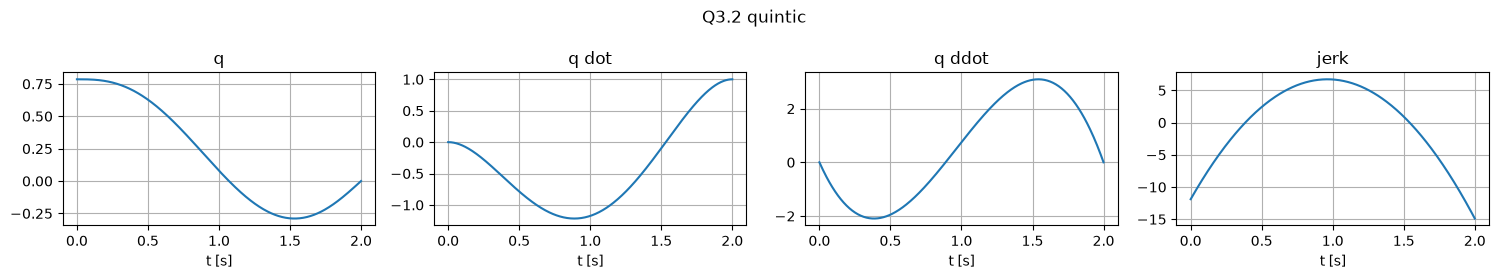

In [31]:
# ---------------- 5A INPUT ----------------
c_q32 = quintic(q0=np.pi / 4, qf=0, t0=0, tf=2,          # positions [rad] and times [s]    <-- CHANGE
                v0=0, vf=1, a0=0, af=0)                  # velocities, accelerations
# Expected Q3.2: c0..c5 = 0.7854, 0, 0, -1.982, 1.611, -0.3348
traj_table(c_q32, [0, 0.5, 1, 1.5, 2])
plot_traj(c_q32, 0, 2, "Q3.2 quintic")

### 5B. Cubic (any start time) and rest-to-rest peaks

In [32]:
# ---------------- 5B INPUT ----------------
c_cub = cubic(q0=10, qf=40, t0=1, tf=3, v0=0, vf=0)       # start at t0 = 1 s: no shortcut needed   <-- CHANGE
traj_extrema(c_cub, 1, 3)
rest_to_rest_peaks(D=30, T=2);


polynomial of degree 3 through 4 conditions
   · q(t) = c0 + c1 t + c2 t^2 + c3 t^3

▶ each condition is one row of  M · c = b   (columns = c0, c1, c2, ...)
        q(1) =       10   →   [1, 1, 1, 1]
       q'(1) =        0   →   [0, 1, 2, 3]
        q(3) =       40   →   [1, 3, 9, 27]
       q'(3) =        0   →   [0, 1, 6, 27]

▶ solve M c = b
   c0 =  40
   c1 = -67.5
   c2 =  45
   c3 = -7.5
   · q(t) = 40 - 67.5 t + 45 t^2 - 7.5 t^3

▶ check every condition
        q(1) =        10   (wanted 10) ✔
       q'(1) =         0   (wanted 0) ✔
        q(3) =        40   (wanted 40) ✔
       q'(3) =         0   (wanted 0) ✔

✅ ANSWER: c0..c3 = [ 40.  -67.5  45.   -7.5]

✅ ANSWER: max |q dot| = 22.5000 at t = 2.0000;  max |q ddot| = 45.0000 at t = 1.0000

✅ ANSWER: cubic_vmax = 22.5000, cubic_amax = 45.0000, quintic_vmax = 28.1250, quintic_amax = 43.3013


### 5C. Several joints at once (lecture example: the ball catcher, $t$ from 0 to 1 s)

In [33]:
# ---------------- 5C INPUT ----------------
pi = np.pi
multi_joint(q0=[0.25 * pi, 0.6 * pi, -0.52 * pi, 0],          # start positions [rad]          <-- CHANGE
            qf=[0.33 * pi, 0.4 * pi, -0.4 * pi, -0.2 * pi],   # end positions [rad]
            t0=0, tf=1,
            vf=[3.596, 9.246, -7.746, -5.096],                # end velocities [rad/s] (from J⁺ ξ)
            kind='cubic');
# Expected: joint 1 → 0.785, 0, -2.842, 3.093 | joint 4 → 0, 0, 3.211, -3.839


cubic coefficients for 4 joints (t from 0 to 1)
   joint |        c0 |        c1 |        c2 |        c3
       1 |    0.7854 |    0.0000 |   -2.8420 |    3.0933
       2 |    1.8850 |    0.0000 |  -11.1310 |   10.5026
       3 |   -1.6336 |    0.0000 |    8.8770 |   -8.5000
       4 |    0.0000 |    0.0000 |    3.2110 |   -3.8394

✅ ANSWER: coefficient table above (row = joint)


### 5D. A polynomial through any conditions, and via points
`(t, m, value)` means $q^{(m)}(t)=$ value. Example: start at rest at 0, pass $0.5$ at $t=1$, stop at $1$ at $t=2$. That is 5 conditions, so a 4th-order polynomial.

In [34]:
# ---------------- 5D INPUT ----------------
c_via = poly_from_conditions([(0, 0, 0), (0, 1, 0), (1, 0, 0.5), (2, 0, 1), (2, 1, 0)])   # <-- CHANGE
piecewise_cubic(times=[0, 1, 3, 4], positions=[0, 20, 50, 40]);                            # <-- CHANGE


polynomial of degree 4 through 5 conditions
   · q(t) = c0 + c1 t + c2 t^2 + c3 t^3 + c4 t^4

▶ each condition is one row of  M · c = b   (columns = c0, c1, c2, ...)
        q(0) =        0   →   [1, 0, 0, 0, 0]
       q'(0) =        0   →   [0, 1, 0, 0, 0]
        q(1) =      0.5   →   [1, 1, 1, 1, 1]
        q(2) =        1   →   [1, 2, 4, 8, 16]
       q'(2) =        0   →   [0, 1, 4, 12, 32]

▶ solve M c = b
   c0 =  0
   c1 =  0
   c2 =  0.75
   c3 = -0.25
   c4 =  0
   · q(t) = 0.75 t^2 - 0.25 t^3

▶ check every condition
        q(0) =         0   (wanted 0) ✔
       q'(0) =         0   (wanted 0) ✔
        q(1) =       0.5   (wanted 0.5) ✔
        q(2) =         1   (wanted 1) ✔
       q'(2) =         0   (wanted 0) ✔

✅ ANSWER: c0..c4 = [ 0.    0.    0.75 -0.25  0.  ]

piecewise cubic through 4 points (local time in every segment)
   · knot velocities = [ 0.  17.5  0.   0. ]
   · segment 1 (0 → 1 s): q(τ) = 42.5 τ^2 - 22.5 τ^3
   · segment 2 (1 → 3 s): q(τ) = 20 + 17.5 τ + 5 

### 5E. LSPB (trapezoidal velocity) and minimum time


LSPB from 0 to 1 in 2 s
   · blend time tb = 0.6667 s, blend acceleration = 1.1250, cruise speed V = 0.7500
   · 0 ≤ t ≤ 0.6667:            q = 0 + 0.5625 t²
   · 0.6667 < t ≤ 1.3333:   q = -0.2500 + 0.7500 t
   · 1.3333 < t ≤ 2:   q = 1 - 0.5625 (2 - t)²


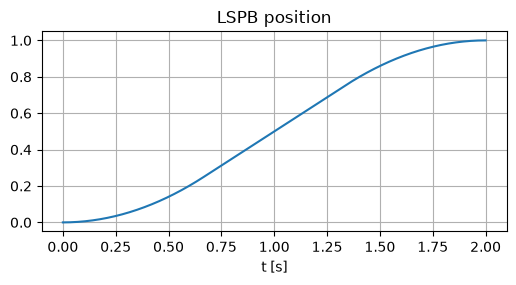


✅ ANSWER: tb = 0.6667 s, acc = 1.1250, V = 0.7500

LSPB from 0 to 1 in 2 s
   · blend time tb = 0.4226 s, blend acceleration = 1.5000, cruise speed V = 0.6340
   · 0 ≤ t ≤ 0.4226:            q = 0 + 0.7500 t²
   · 0.4226 < t ≤ 1.5774:   q = -0.1340 + 0.6340 t
   · 1.5774 < t ≤ 2:   q = 1 - 0.7500 (2 - t)²

✅ ANSWER: tb = 0.4226 s, acc = 1.5000, V = 0.6340

minimum-time (bang-bang) motion
   · ts = sqrt(|Δ|/acc) = sqrt(1/2) = 0.7071 s

✅ ANSWER: switch time ts = 0.7071 s, total time tf = 1.4142 s, peak speed = 1.4142


In [35]:
# ---------------- 5E INPUT ----------------
lspb(q0=0, qf=1, tf=2, V=0.75, plot=True)                 # given the cruise speed        <-- CHANGE
lspb(q0=0, qf=1, tf=2, acc=1.5)                           # given the blend acceleration
bang_bang(q0=0, qf=1, acc=2);

### 5F. Constant-jerk path (exam 2016 P3), solved symbolically
$q(0)=0$, $q(10)=100$, rest at both ends, $|\dddot q|\le 10$. By symmetry: jerk $+10$ for $t_1$, $-10$ for $t_1$, then $0$ until $t=5$, where $q=50$.

In [36]:
# ---------------- 5F INPUT ----------------
t1s = sp.symbols('t1', positive=True)
res = jerk_profile([(t1s, 10), (t1s, -10), (5 - 2 * t1s, 0)])       # (duration, jerk) segments   <-- CHANGE
roots = sp.Poly(sp.expand(res[-1][0] - 50), t1s).nroots()            # condition: q(5) = 50
t1_val = [sp.re(r_) for r_ in roots if abs(sp.im(r_)) < 1e-9 and 0 < sp.re(r_) < 2.5][0]
vmax_2016 = res[1][1].subs(t1s, t1_val)
answer(f"t1 = {float(t1_val):.6f} s, q dot max = {float(vmax_2016):.6f}")     # expected 1.137805 and 12.946


✅ ANSWER: t1 = 1.137805 s, q dot max = 12.946007


---
# 6. Robot vision (MCQ Q4.1–Q4.4, VisionExam)

### Theory in 60 seconds
* Point $(x,y,z)$ in the **camera frame** (z = depth along the optical axis) → image plane in mm: $\;u=\lambda\dfrac{x}{z},\quad v=\lambda\dfrac{y}{z}$.
* Image plane → pixels (exam convention): $\;r=o_r-\alpha_x u,\quad c=o_c-\alpha_y v$, with $\alpha=1/s$ [pixel/mm] and $(o_r,o_c)$ = principal point.
* Camera ↔ base: $p^b=T^b_c\,p^c$ and $p^c=(T^b_c)^{-1}p^b$. **A camera that moved** = a new $T^b_{c}$: express the base points in the new camera frame and project again.
* One image loses depth. To go back from pixels to 3D you need the depth (e.g. the camera height above a table), a known size, or stereo.
* Size and depth: $\dfrac{\text{world length}}{\text{image length [mm]}}=\dfrac{z}{\lambda}$. Pixels are rectangular, so convert $\Delta r$ with $\alpha_x$ and $\Delta c$ with $\alpha_y$ **before** Pythagoras.
* Stereo (parallel cameras, baseline $B$): $z=\dfrac{\lambda B}{u_1-u_2}$ (the disparity $u_1-u_2$ in mm).

### Exam traps
* **Sign convention.** The slides and the MCQ use $r=o_r-\alpha_xu$ (minus). If a figure shows the pixel axes in the same direction as the camera $x, y$, use `sign=+1`. Draw both pairs of axes first.
* Same length unit as $\lambda$ (mm) for $x,y,z$.
* The MCQ rounds pixels to whole numbers: `project` prints the exact value **and** the rounded one.

### Sensors in one minute (conceptual questions)
Encoder → joint angle · tachometer → speed · gyroscope → rate of turn · accelerometer → gravity direction and acceleration · IMU = gyro + accelerometer (+ compass), combined with **sensor fusion** (e.g. a Kalman filter). Eye-in-hand = camera on the end-effector; eye-to-hand = camera fixed in the workspace. **PBVS** = the error is a Cartesian pose; **IBVS** = the error is in image features.

In [37]:
# =====================================================================
# 6. TOOLS: camera model, projection, back-projection, frames, sizes, stereo
# =====================================================================

class Camera:
    """Pinhole camera with the 34753 exam convention.
        image plane [mm]:  u = λ·x/z,   v = λ·y/z             (x, y, z = the point in the CAMERA frame)
        pixels:            r = o_r + sign·α_x·u,   c = o_c + sign·α_y·v
        sign = -1 in the slides and the MCQ  →  r = o_r - α_x u,  c = o_c - α_y v
    lam      : focal length λ [mm]
    alpha_x, alpha_y : pixels per mm (= 1 / pixel size s_x, s_y)
    o_r, o_c : principal point [pixels]
    If the focal length is given in pixels (f = λ·α), use Camera.from_pixels(fx, fy, o_r, o_c)."""

    def __init__(self, lam, alpha_x, alpha_y, o_r, o_c, sign=-1):
        self.lam, self.ax, self.ay, self.o_r, self.o_c, self.sign = lam, alpha_x, alpha_y, o_r, o_c, sign

    @classmethod
    def from_pixels(cls, fx, fy, o_r, o_c, sign=-1):
        """Focal lengths already in pixels: λ = 1 and α = f (so α·u = f·x/z)."""
        return cls(1.0, fx, fy, o_r, o_c, sign)

    def describe(self):
        sg = '-' if self.sign < 0 else '+'
        print(f"camera: λ = {num(self.lam)}, α_x = {num(self.ax)}, α_y = {num(self.ay)}, "
              f"(o_r, o_c) = ({num(self.o_r)}, {num(self.o_c)});  r = o_r {sg} α_x u,  c = o_c {sg} α_y v")

    def K(self):
        """Intrinsic matrix: [r, c, 1]ᵀ ∝ K [x, y, z]ᵀ."""
        return np.array([[self.sign * self.ax * self.lam, 0, self.o_r],
                         [0, self.sign * self.ay * self.lam, self.o_c], [0, 0, 1]])


def project(P_cam, cam, labels=None, explain=None):
    """Points in the CAMERA frame (N x 3, same unit as λ) → image plane (u, v) [mm] and pixels (r, c).
    Returns (uv, rc) as N x 2 arrays (exact values; the printout also shows the rounded pixels)."""
    ex = _ex(explain)
    P = np.atleast_2d(np.asarray(P_cam, dtype=float))
    u = cam.lam * P[:, 0] / P[:, 2]; v = cam.lam * P[:, 1] / P[:, 2]
    r = cam.o_r + cam.sign * cam.ax * u; c = cam.o_c + cam.sign * cam.ay * v
    sg = '-' if cam.sign < 0 else '+'
    if ex:
        title("projection: camera frame → image plane (u, v) → pixels (r, c)")
        cam.describe()
    rows = []
    for i in range(len(P)):
        nm = labels[i] if labels else f"P{i+1}"
        rows.append(f"{nm} = [{round(r[i])}; {round(c[i])}]")
        if ex:
            step(f"{nm} = ({num(P[i,0])}, {num(P[i,1])}, {num(P[i,2])}) in the camera frame")
            note(f"u = λ·x/z = {num(cam.lam)}·{par(P[i,0])}/{par(P[i,2])} = {u[i]:.4f}    "
                 f"v = λ·y/z = {num(cam.lam)}·{par(P[i,1])}/{par(P[i,2])} = {v[i]:.4f}")
            note(f"r = o_r {sg} α_x·u = {num(cam.o_r)} {sg} {num(cam.ax)}·({u[i]:.4f}) = {r[i]:.2f}    "
                 f"c = o_c {sg} α_y·v = {num(cam.o_c)} {sg} {num(cam.ay)}·({v[i]:.4f}) = {c[i]:.2f}")
            note(f"pixel (rounded) = [{round(r[i])}; {round(c[i])}]")
    answer("  ".join(rows))
    return np.c_[u, v], np.c_[r, c]


def to_frame(T_a_b, P_b, explain=None):
    """Points written in frame b (N x 3) → frame a, using T^a_b:  p^a = R p^b + o."""
    P = np.atleast_2d(np.asarray(P_b, dtype=float))
    out = (np.asarray(T_a_b, dtype=float) @ np.c_[P, np.ones(len(P))].T).T[:, :3]
    if _ex(explain):
        title("change of frame:  p_a = T_ab · p_b")
        for p_, o_ in zip(P, out):
            note(f"{clean(p_)} → {clean(o_)}")
    return out


def world_to_pixel(P_world, T_w_c, cam, labels=None, explain=None):
    """Points in the WORLD/base frame → pixels:  p_c = (T^w_c)⁻¹ p_w, then project."""
    Pc = to_frame(Hinv(T_w_c), P_world, explain=False)
    if _ex(explain):
        title("world → camera frame:  p_c = (T_wc)⁻¹ p_w")
        for pw, pc in zip(np.atleast_2d(P_world), Pc):
            note(f"p_w = {clean(pw)} → p_c = {clean(pc)}")
    return project(Pc, cam, labels, explain)


def pixel_to_camera(r, c, z, cam, explain=None):
    """Pixel (r, c) + known depth z → the point in the camera frame (inverse of `project`):
        u = (r - o_r)/(sign·α_x),  v = (c - o_c)/(sign·α_y),  x = u·z/λ,  y = v·z/λ."""
    u = (r - cam.o_r) / (cam.sign * cam.ax); v = (c - cam.o_c) / (cam.sign * cam.ay)
    p = np.array([u * z / cam.lam, v * z / cam.lam, z])
    if _ex(explain):
        title(f"pixel [{num(r)}; {num(c)}] with depth z = {num(z)} → camera frame")
        note(f"u = (r - o_r)/({'-' if cam.sign < 0 else ''}α_x) = {u:.4f} mm,   v = (c - o_c)/({'-' if cam.sign < 0 else ''}α_y) = {v:.4f} mm")
        note(f"x = u·z/λ = {p[0]:.4f},   y = v·z/λ = {p[1]:.4f}")
    answer(f"p_cam = {clean(p)}")
    return p


def pixel_to_world(r, c, z, T_w_c, cam, explain=None):
    """Pixel + depth → camera frame → world frame (p_w = T_wc p_c)."""
    pc = pixel_to_camera(r, c, z, cam, explain)
    pw = to_frame(T_w_c, pc, explain=False)[0]
    answer(f"p_world = {clean(pw)}")
    return pw


def task_frame_from_pixels(pixels, depth, cam, explain=None):
    """Pose of a task frame in the CAMERA frame from the pixels of three points (exam 2017 P4.3):
    pixels = [P0, Px, Py] as [r, c] (origin, a point on the x axis, a point on the y axis / in the xy-plane),
    depth = their distance z from the camera (e.g. the camera height above the table).
    Each pixel is back-projected to the camera frame, then frame_from_points builds T^C_task.
    Chain it with T^B_task to get T^B_C = T^B_task · (T^C_task)^-1, or map points: p_B = T^B_task (T^C_task)^-1 p_C."""
    P = [_quiet(pixel_to_camera, r, c, depth, cam) for r, c in pixels]
    T = _quiet(frame_from_points, *P)
    if _ex(explain):
        title("task frame seen by the camera (from three pixels with known depth)")
        for nm, (r, c), p_ in zip(("P0", "Px", "Py"), pixels, P):
            note(f"{nm}: pixel [{num(r)}; {num(c)}] → camera frame {clean(p_)}")
        pm("T^C_task", T)
    answer("T^C_task printed above (columns: task x, y, z axes and origin, in camera coordinates)")
    return T, P


def pixel_distance(p1, p2, cam, explain=None):
    """Distance between two pixels [r, c] in pixels and in mm on the sensor (each axis converted separately)."""
    dr, dc = p1[0] - p2[0], p1[1] - p2[1]
    d_pix = np.hypot(dr, dc)
    du, dv = dr / cam.ax, dc / cam.ay
    d_mm = np.hypot(du, dv)
    if _ex(explain):
        title("pixel distance → mm on the sensor")
        note(f"Δr = {num(dr)}, Δc = {num(dc)} pixels → {d_pix:.4f} pixels")
        note(f"Δu = Δr/α_x = {du:.4f} mm, Δv = Δc/α_y = {dv:.4f} mm → sqrt(Δu² + Δv²) = {d_mm:.4f} mm")
    answer(f"{d_pix:.4f} pixels = {d_mm:.4f} mm on the sensor")
    return d_pix, d_mm


def depth_from_size(lam, size_world, size_sensor_mm, explain=None):
    """Known real size → depth:  z = λ · L_world / L_image(mm)."""
    z = lam * size_world / size_sensor_mm
    if _ex(explain):
        title("depth from a known size:  z = λ · L_world / L_image")
        note(f"z = {num(lam)} · {num(size_world)} / {size_sensor_mm:.4f}")
    answer(f"z = {z:.4f}  (same unit as L_world, when λ and the image length are both in mm)")
    return z


def size_from_depth(lam, z, size_sensor_mm, explain=None):
    """Known depth → real size:  L_world = L_image(mm) · z / λ."""
    Lw = size_sensor_mm * z / lam
    if _ex(explain):
        title("size from a known depth:  L = L_image · z / λ")
        note(f"L = {size_sensor_mm:.4f} · {num(z)} / {num(lam)}")
    answer(f"L_world = {Lw:.4f}  (same unit as z)")
    return Lw


def stereo_depth(lam, B, u1, u2, explain=None):
    """Parallel stereo: z = λ·B / (u1 - u2)   (u1, u2 = image coordinates of the point in the left/right camera)."""
    z = lam * B / (u1 - u2)
    if _ex(explain):
        title("stereo depth  z = λ B / (u1 - u2)")
        note(f"disparity u1 - u2 = {num(u1 - u2)};  z = {num(lam)}·{num(B)}/{num(u1 - u2)}")
    answer(f"z = {z:.4f}")
    return z


def ibvs_interaction_matrix(u, v, z, lam):
    """📖 Textbook (Spong ch. 11), not in the slides: image Jacobian of a point (u, v in the same unit as λ),
    camera velocity [v_c; ω_c] in the camera frame → (u dot, v dot)."""
    return np.array([[-lam / z, 0, u / z, u * v / lam, -(lam**2 + u**2) / lam, v],
                     [0, -lam / z, v / z, (lam**2 + v**2) / lam, -u * v / lam, -u]])


print("Section 6 tools loaded ✔")

Section 6 tools loaded ✔


### 6A. The camera and the corners of the keyboard on the image plane (Q4.1)
Camera on the end-effector, looking down at a table 500 mm below. Keyboard frame: $x$ right, $y$ down, the same as the camera's $x_c, y_c$.

In [38]:
# ---------------- 6A INPUT ----------------
cam = Camera(lam=8, alpha_x=79.2, alpha_y=120.5, o_r=250, o_c=160)     # λ [mm], α [pix/mm], principal point   <-- CHANGE
T_b_c = np.array([[1,  0,  0,   0],                                    # camera pose in the base frame [mm]    <-- CHANGE
                  [0, -1,  0, 300],
                  [0,  0, -1, 500],
                  [0,  0,  0,   1]], dtype=float)
depth = 500                                                            # table 500 mm below the camera
corners = np.array([[-30, -30, depth], [-30, 0, depth], [20, 0, depth], [20, -30, depth]])   # P1..P4 in the camera frame [mm]
uv_q41, _ = project(corners, cam, labels=["P1", "P2", "P3", "P4"])
pm("Pc (row 1 = u, row 2 = v) [mm]", uv_q41.T)      # expected [[-0.48, -0.48, 0.32, 0.32], [-0.48, 0, 0, -0.48]]


projection: camera frame → image plane (u, v) → pixels (r, c)
camera: λ = 8, α_x = 79.2, α_y = 120.5, (o_r, o_c) = (250, 160);  r = o_r - α_x u,  c = o_c - α_y v

▶ P1 = (-30, -30, 500) in the camera frame
   · u = λ·x/z = 8·(-30)/500 = -0.4800    v = λ·y/z = 8·(-30)/500 = -0.4800
   · r = o_r - α_x·u = 250 - 79.2·(-0.4800) = 288.02    c = o_c - α_y·v = 160 - 120.5·(-0.4800) = 217.84
   · pixel (rounded) = [288; 218]

▶ P2 = (-30, 0, 500) in the camera frame
   · u = λ·x/z = 8·(-30)/500 = -0.4800    v = λ·y/z = 8·0/500 = 0.0000
   · r = o_r - α_x·u = 250 - 79.2·(-0.4800) = 288.02    c = o_c - α_y·v = 160 - 120.5·(0.0000) = 160.00
   · pixel (rounded) = [288; 160]

▶ P3 = (20, 0, 500) in the camera frame
   · u = λ·x/z = 8·20/500 = 0.3200    v = λ·y/z = 8·0/500 = 0.0000
   · r = o_r - α_x·u = 250 - 79.2·(0.3200) = 224.66    c = o_c - α_y·v = 160 - 120.5·(0.0000) = 160.00
   · pixel (rounded) = [225; 160]

▶ P4 = (20, -30, 500) in the camera frame
   · u = λ·x/z = 8·20/500 = 0.3200    v

### 6B. The pixel sequence for typing "CIAO" (Q4.2)

In [39]:
# ---------------- 6B INPUT ----------------
keys = {"C": (-25, -25), "I": (-15, -15), "A": (5, -25), "O": (15, -5)}    # key centres (x, y) in the camera frame [mm]   <-- CHANGE
P_keys = np.array([[x_, y_, depth] for x_, y_ in keys.values()])
_, rc_q42 = project(P_keys, cam, labels=list(keys))
# Expected Q4.2: C = [282; 208], I = [269; 189], A = [244; 208], O = [231; 170]


projection: camera frame → image plane (u, v) → pixels (r, c)
camera: λ = 8, α_x = 79.2, α_y = 120.5, (o_r, o_c) = (250, 160);  r = o_r - α_x u,  c = o_c - α_y v

▶ C = (-25, -25, 500) in the camera frame
   · u = λ·x/z = 8·(-25)/500 = -0.4000    v = λ·y/z = 8·(-25)/500 = -0.4000
   · r = o_r - α_x·u = 250 - 79.2·(-0.4000) = 281.68    c = o_c - α_y·v = 160 - 120.5·(-0.4000) = 208.20
   · pixel (rounded) = [282; 208]

▶ I = (-15, -15, 500) in the camera frame
   · u = λ·x/z = 8·(-15)/500 = -0.2400    v = λ·y/z = 8·(-15)/500 = -0.2400
   · r = o_r - α_x·u = 250 - 79.2·(-0.2400) = 269.01    c = o_c - α_y·v = 160 - 120.5·(-0.2400) = 188.92
   · pixel (rounded) = [269; 189]

▶ A = (5, -25, 500) in the camera frame
   · u = λ·x/z = 8·5/500 = 0.0800    v = λ·y/z = 8·(-25)/500 = -0.4000
   · r = o_r - α_x·u = 250 - 79.2·(0.0800) = 243.66    c = o_c - α_y·v = 160 - 120.5·(-0.4000) = 208.20
   · pixel (rounded) = [244; 208]

▶ O = (15, -5, 500) in the camera frame
   · u = λ·x/z = 8·15/500 = 0.

### 6C. The same keys in the base frame (Q4.3), and back from pixels

In [40]:
# ---------------- 6C INPUT ----------------
P_base_q43 = to_frame(T_b_c, P_keys)          # p_b = T_bc p_c
answer("base frame [mm]: " + " | ".join(f"{k} = {clean(p_)}" for k, p_ in zip(keys, P_base_q43)))
# Expected Q4.3: C = (-25, 325, 0), I = (-15, 315, 0), A = (5, 325, 0), O = (15, 305, 0)
pixel_to_world(282, 208, depth, T_b_c, cam);  # the other way: pixel C + depth → base frame (≈ the C key)


change of frame:  p_a = T_ab · p_b
   · [-25. -25. 500.] → [-25. 325.   0.]
   · [-15. -15. 500.] → [-15. 315.   0.]
   · [  5. -25. 500.] → [  5. 325.   0.]
   · [ 15.  -5. 500.] → [ 15. 305.   0.]

✅ ANSWER: base frame [mm]: C = [-25. 325.   0.] | I = [-15. 315.   0.] | A = [  5. 325.   0.] | O = [ 15. 305.   0.]

pixel [282; 208] with depth z = 500 → camera frame
   · u = (r - o_r)/(-α_x) = -0.4040 mm,   v = (c - o_c)/(-α_y) = -0.3983 mm
   · x = u·z/λ = -25.2525,   y = v·z/λ = -24.8963

✅ ANSWER: p_cam = [-25.2525 -24.8963 500.    ]

✅ ANSWER: p_world = [-25.2525 324.8963   0.    ]


### 6D. The camera moved (Q4.4)
Keys are fixed in the base frame. Express them in the **new** camera frame with $(T^b_{c2})^{-1}$, then project.

In [41]:
# ---------------- 6D INPUT ----------------
T_b_c2 = np.array([[1,  0,  0, -30],               # the NEW camera pose [mm]                 <-- CHANGE
                   [0, -1,  0, 330],
                   [0,  0, -1, 500],
                   [0,  0,  0,   1]], dtype=float)
keys_cam1 = np.array([[-15, -5, depth], [5, -15, depth]])         # keys X and Q in the OLD camera frame
P_base_XQ = to_frame(T_b_c, keys_cam1, explain=False)            # → base frame
_, rc_q44 = world_to_pixel(P_base_XQ, T_b_c2, cam, labels=["X", "Q"])
# Expected Q4.4: X = [231; 112], Q = [206; 131]


world → camera frame:  p_c = (T_wc)⁻¹ p_w
   · p_w = [-15. 305.   0.] → p_c = [ 15.  25. 500.]
   · p_w = [  5. 315.   0.] → p_c = [ 35.  15. 500.]

projection: camera frame → image plane (u, v) → pixels (r, c)
camera: λ = 8, α_x = 79.2, α_y = 120.5, (o_r, o_c) = (250, 160);  r = o_r - α_x u,  c = o_c - α_y v

▶ X = (15, 25, 500) in the camera frame
   · u = λ·x/z = 8·15/500 = 0.2400    v = λ·y/z = 8·25/500 = 0.4000
   · r = o_r - α_x·u = 250 - 79.2·(0.2400) = 230.99    c = o_c - α_y·v = 160 - 120.5·(0.4000) = 111.80
   · pixel (rounded) = [231; 112]

▶ Q = (35, 15, 500) in the camera frame
   · u = λ·x/z = 8·35/500 = 0.5600    v = λ·y/z = 8·15/500 = 0.2400
   · r = o_r - α_x·u = 250 - 79.2·(0.5600) = 205.65    c = o_c - α_y·v = 160 - 120.5·(0.2400) = 131.08
   · pixel (rounded) = [206; 131]

✅ ANSWER: X = [231; 112]  Q = [206; 131]


### 6E. Distances, sizes and depths (VisionExam and the Fall 2025 vision exercises)

In [42]:
# ---------------- 6E INPUT ----------------
cam_ve = Camera(lam=8, alpha_x=79.2, alpha_y=120.5, o_r=250, o_c=250)
# VisionExam Q4.1: a square from -0.1 to 0.2 m, at depth 1 m (P1-P4) and 2 m (P5-P8); metres are fine
# here because only x/z enters u = λ x / z
sq = [(-0.1, -0.1), (0.2, -0.1), (0.2, 0.2), (-0.1, 0.2)]                              # <-- CHANGE
# Expected: P1..P4 = [313;346] [123;346] [123;57] [313;57],  P5..P8 = [282;298] [187;298] [187;154] [282;154]
_, rc_ve = project([[x_, y_, 1] for x_, y_ in sq] + [[x_, y_, 2] for x_, y_ in sq], cam_ve,
                   labels=[f"P{i}" for i in range(1, 9)], explain=False)
# VisionExam Q4.2: two points 0.3 m apart seen at r = 313 and r = 155 (same c) → depth?
_, d_mm_ve = pixel_distance([313, 250], [155, 250], cam_ve, explain=False)
depth_from_size(lam=8, size_world=0.3, size_sensor_mm=d_mm_ve)      # expected 1.2 m
# Vision exercise 1 (drone): pixel distance → mm, the car moved 43 km/h · 3 s
_, d_drone = pixel_distance([476, 380], [147, 117], cam_ve)           # 421 pixels, 4.69 mm
scale = (43 / 3.6 * 3) / d_drone                                       # metres in the world per mm on the sensor
answer(f"scale = {scale:.4f} m/mm → altitude z = λ·scale = {8 * scale:.2f} m")   # ≈ 61.1 m
# Vision exercise 2 (couch): door 0.8 m wide = 63 pixels → wall depth; couch 158 pixels long at that depth
z_wall = depth_from_size(lam=8, size_world=0.8, size_sensor_mm=63 / 79.2, explain=False)
size_from_depth(lam=8, z=z_wall, size_sensor_mm=158 / 79.2, explain=False);   # ≈ 2.0 m


✅ ANSWER: P1 = [313; 346]  P2 = [123; 346]  P3 = [123; 57]  P4 = [313; 57]  P5 = [282; 298]  P6 = [187; 298]  P7 = [187; 154]  P8 = [282; 154]

✅ ANSWER: 158.0000 pixels = 1.9949 mm on the sensor

depth from a known size:  z = λ · L_world / L_image
   · z = 8 · 0.3 / 1.9949

✅ ANSWER: z = 1.2030  (same unit as L_world, when λ and the image length are both in mm)

pixel distance → mm on the sensor
   · Δr = 329, Δc = 263 pixels → 421.2007 pixels
   · Δu = Δr/α_x = 4.1540 mm, Δv = Δc/α_y = 2.1826 mm → sqrt(Δu² + Δv²) = 4.6925 mm

✅ ANSWER: 421.2007 pixels = 4.6925 mm on the sensor

✅ ANSWER: scale = 7.6363 m/mm → altitude z = λ·scale = 61.09 m

✅ ANSWER: z = 8.0457  (same unit as L_world, when λ and the image length are both in mm)

✅ ANSWER: L_world = 2.0063  (same unit as z)


### 6F. Pixel → 3D point, stereo, the lecture's handwritten example

In [43]:
# ---------------- 6F INPUT ----------------
cam16 = Camera.from_pixels(fx=400, fy=400, o_r=320, o_c=240)        # 2016 P4.3: focal length 400 pixels
pixel_to_camera(470, 290, 0.8, cam16)                                # expected (-0.3, -0.1, 0.8)
stereo_depth(lam=1, B=0.1, u1=0.05, u2=-0.05)                        # handwritten example: z = 1 m
cam_hw = Camera.from_pixels(fx=500, fy=500, o_r=320, o_c=240)        # handwritten notes: λ/s = 500 pixels
project([[-0.2, 0, 0.8]], cam_hw, labels=["object"]);               # expected r = 445, c = 240


pixel [470; 290] with depth z = 0.8 → camera frame
   · u = (r - o_r)/(-α_x) = -0.3750 mm,   v = (c - o_c)/(-α_y) = -0.1250 mm
   · x = u·z/λ = -0.3000,   y = v·z/λ = -0.1000

✅ ANSWER: p_cam = [-0.3 -0.1  0.8]

stereo depth  z = λ B / (u1 - u2)
   · disparity u1 - u2 = 0.1;  z = 1·0.1/0.1

✅ ANSWER: z = 1.0000

projection: camera frame → image plane (u, v) → pixels (r, c)
camera: λ = 1, α_x = 500, α_y = 500, (o_r, o_c) = (320, 240);  r = o_r - α_x u,  c = o_c - α_y v

▶ object = (-0.2, 0, 0.8) in the camera frame
   · u = λ·x/z = 1·(-0.2)/0.8 = -0.2500    v = λ·y/z = 1·0/0.8 = 0.0000
   · r = o_r - α_x·u = 320 - 500·(-0.2500) = 445.00    c = o_c - α_y·v = 240 - 500·(0.0000) = 240.00
   · pixel (rounded) = [445; 240]

✅ ANSWER: object = [445; 240]


---
# 7. Control (MCQ Q5.1, Q5.2)

### First: name every symbol by its unit
| unit | what it is | usual names |
|---|---|---|
| V·s/rad (= V per rad/s) | back-emf constant | $K_b$ (the MCQ calls it $K_m$!) |
| N·m/A | torque constant | $K_t$, $K_m$, $K_i$ |
| Ω | armature resistance | $R$ |
| H | armature inductance | $L$ |
| kg·m² | inertia | $J$ |
| N·m·s/rad (= kg·m²/s) | viscous damping | $B$, $D$ |
| – | gear ratio $\theta_m=n\,\theta_\ell$ | $n$, $r$ |
| N·m | load / disturbance torque | $\tau_\ell$, $D$ |
| V/rad | P gain whose output is a **voltage** | $k_p$ |
| N·m/rad | P gain whose output is a **torque** | $K_p$ |

### Theory in 60 seconds
* $G(s)=N(s)/D(s)$. **Poles** = roots of $D$ (how many = the order), zeros = roots of $N$. Stable ⇔ every pole has $\text{Re}<0$.
* Block algebra: series $AB$, parallel $A+B$, negative feedback $\dfrac{A}{1+AB}$; unity loop $\dfrac{CG}{1+CG}$.
* **Final value** $f(\infty)=\lim_{s\to0}sF(s)$ (only if $sF$ is stable). **Initial value** $f(0^+)=\lim_{s\to\infty}sF(s)$.
* **DC motor**, motor side ($J=J_m+J_\ell/n^2$): $(Ls+R)I=V-K_bs\Theta$ and $(Js^2+Bs)\Theta=K_tI-\tau_\ell/n$ ⇒ $\dfrac{\Theta}{V}=\dfrac{K_t}{s[(Ls+R)(Js+B)+K_tK_b]}$.
  **3 poles** with $L$, **2 poles** with $L\approx0$; one of them is at $s=0$. The speed $\Omega/V$ has one pole fewer.
* **P control of the motor with a load:** in steady state $\dot\theta=0$, so $V=Ri$ and $K_ti=\tau_\ell/n$ ⇒ $e_{ss}=\dfrac{R\,\tau_\ell}{n\,K_t\,k_p}$. An integrator (PI or PID) gives $e_{ss}=0$.
* **Joint with torque input** $\tau=(K_p+K_ds)(\theta^d-\theta)$ and a disturbance $D$: $\theta=\dfrac{(K_p+K_ds)\theta^d-D}{Js^2+(B+K_d)s+K_p}$, $e_{ss}=D/K_p$, $\omega_n=\sqrt{K_p/J}$, $\zeta=\dfrac{B+K_d}{2\sqrt{K_pJ}}$.
  Design: $K_p=J\omega_n^2$, $K_d=2\zeta\omega_nJ-B$. PID is stable iff $K_i<(B+K_d)K_p/J$.
* 2nd order: $\%OS=100e^{-\pi\zeta/\sqrt{1-\zeta^2}}$, $t_s\approx4/(\zeta\omega_n)$, $t_p=\pi/(\omega_n\sqrt{1-\zeta^2})$, $t_r\approx1.8/\omega_n$.

### Exam traps
* "The symbols may not be the same as in the slides": trust the **units** (table above).
* Poles of $\Theta/V$ versus $\Omega/V$: the angle has one extra pole at 0.
* Eliminate options by **sign, unit and order of magnitude** first: an angle error in metres, or a negative error for a positive load, is wrong.

In [44]:
# =====================================================================
# 7. TOOLS: transfer functions, block algebra, FVT, Routh, 2nd order, step response, DC motor loops
# =====================================================================

def _coeffs(poly_expr):
    """Numeric coefficients (highest power first) of a polynomial in s, or None if it has other symbols."""
    P = sp.Poly(sp.expand(poly_expr), s)
    try:
        return np.array([complex(c) for c in P.all_coeffs()])
    except TypeError:
        return None


def fmt_c(z, dec=4):
    """A complex number as text: '-10 + 43.59j' (real numbers without j)."""
    z = complex(z)
    if abs(z.imag) < 1e-9:
        return num(z.real, dec)
    return f"{z.real:.{dec}g} {'+' if z.imag > 0 else '-'} {abs(z.imag):.{dec}g}j"


def tf(num_coeffs, den_coeffs):
    """Transfer function from coefficient lists (highest power first): tf([1, 2], [1, 3, 2]) = (s + 2)/(s² + 3s + 2)."""
    N = sum(sp.nsimplify(c) * s**k for k, c in enumerate(reversed(list(num_coeffs))))
    D = sum(sp.nsimplify(c) * s**k for k, c in enumerate(reversed(list(den_coeffs))))
    return N / D


def tf_info(G, name="G", explain=None):
    """Everything about a transfer function: order (= number of poles), poles, zeros, type (poles at 0),
    DC gain, stability, and the time constant (real pole) or ζ, ω_n (complex pair) of every pole."""
    ex = _ex(explain)
    G = sp.cancel(sp.together(sp.sympify(G)))
    n_, d_ = sp.fraction(G)
    dc, nc = _coeffs(d_), _coeffs(n_)
    if ex:
        title(f"transfer function {name}(s)")
        display(G)
        if dc is not None and nc is not None and abs(dc[0] - 1) > 1e-12:     # also show it with a monic denominator
            lc = sp.Poly(d_, s).LC()
            print("same, with the denominator divided by its leading coefficient:")
            display(sp.expand(n_ / lc).evalf(5) / sp.expand(d_ / lc).evalf(5))
    if dc is None or nc is None:
        order = sp.degree(d_, s)
        if ex:
            print("denominator, factored:"); display(sp.factor(d_))
        answer(f"order = number of poles = {order} (symbolic coefficients)")
        return None
    poles = np.roots(dc)
    zeros = np.roots(nc) if len(nc) > 1 else np.array([])
    typ = int(np.sum(np.abs(poles) < 1e-9))
    if np.all(poles.real < -1e-12):
        status = "asymptotically stable (all poles have Re < 0)"
    elif np.any(poles.real > 1e-12):
        status = "UNSTABLE (a pole with Re > 0)"
    else:
        status = "marginally stable (a pole on the imaginary axis, e.g. s = 0)"
    if ex:
        step(f"order = number of poles = degree of the denominator = {len(poles)}")
        for p in poles:
            if abs(p) < 1e-9:
                note("pole s = 0 (an integrator)")
            elif abs(p.imag) < 1e-9:
                note(f"pole s = {fmt_c(p)}  → time constant τ = -1/p = {-1 / p.real:.6g} s" if p.real < 0 else f"pole s = {fmt_c(p)} (unstable)")
            elif p.imag > 0:
                wn = abs(p); z_ = -p.real / wn
                note(f"poles s = {fmt_c(p)} and its conjugate → ω_n = |p| = {wn:.4f} rad/s, ζ = -Re/|p| = {z_:.4f}")
        step("zeros: " + (", ".join(fmt_c(z_) for z_ in zeros) if len(zeros) else "none"))
        step(f"type = number of poles at s = 0 = {typ}")
        if typ == 0:
            note(f"DC gain G(0) ≈ {complex(sp.limit(G, s, 0)).real:.6g}")
        else:
            note("DC gain is infinite (integrator)")
        step(status)
    answer(f"{name}: {len(poles)} pole{'s' if len(poles) != 1 else ''}: "
           + ", ".join(fmt_c(p) for p in poles) + f"  → {status}")
    return poles


def series(*Gs):
    """Blocks in series: G1 · G2 · ..."""
    return sp.simplify(sp.Mul(*Gs))


def parallel(*Gs):
    """Blocks in parallel (outputs added): G1 + G2 + ..."""
    return sp.simplify(sp.Add(*Gs))


def feedback(G, Hs=1, sign=-1):
    """Closed loop of G with feedback Hs: negative feedback (sign = -1) G/(1 + G H); positive G/(1 - G H)."""
    return sp.simplify(G / (1 - sign * G * Hs))


def solve_loop(equations, unknowns, explain=None):
    """Any block diagram: write one equation per summing point / block, then let sympy solve.
    equations : list of sp.Eq(...);  unknowns : the signals you don't know (sympy symbols)."""
    sol = sp.solve(equations, unknowns, dict=True)[0]
    sol = {k: sp.simplify(v) for k, v in sol.items()}
    if _ex(explain):
        title("block diagram solved")
        for k, v in sol.items():
            print(f"{k} ="); display(v)
    return sol


def loop_tf(C, G, ref=None, dist=None, explain=None):
    """THE recurring exam question (2016, 2017, 2020 Problem 5): unity feedback, controller C(s), plant G(s),
    disturbance D SUBTRACTED at the plant input:   q = G · ( C·(q_ref - q) - D )
        ⇒   q(s) = ( F(s) q_ref(s) - H(s) D(s) ) / N(s)      with  F/N = CG/(1+CG),  H/N = G/(1+CG)
    N is scaled so that its leading coefficient is 1 (as MATLAB prints it).
    ref, dist : optional STEP sizes → also the steady-state error e_ss = lim s(q_ref - q)."""
    ex = _ex(explain)
    C, G = sp.nsimplify(C), sp.nsimplify(G)
    Tr = sp.cancel(sp.together(C * G / (1 + C * G)))
    Td = sp.cancel(sp.together(G / (1 + C * G)))
    N = sp.lcm(sp.fraction(Tr)[1], sp.fraction(Td)[1])
    F, Hd = sp.cancel(Tr * N), sp.cancel(Td * N)
    lc = sp.Poly(N, s).LC()
    N, F, Hd = (sp.expand(x / lc) for x in (N, F, Hd))
    if ex:
        title("loop with the disturbance at the plant input:  q = (F q_ref - H D) / N")
        print("C(s) ="); display(C)
        print("G(s) ="); display(G)
        print("F(s) ="); display(F); print("   decimal:", sp.N(F, 4))
        print("H(s) ="); display(Hd); print("   decimal:", sp.N(Hd, 4))
        print("N(s) ="); display(N); print("   decimal:", sp.N(N, 4))
        cc = _coeffs(N)
        if cc is not None:
            poles = np.roots(cc)
            note("closed-loop poles: " + ", ".join(fmt_c(p) for p in poles)
                 + ("  → stable ✔" if np.all(poles.real < 0) else "  → NOT stable ✘"))
    ess = None
    if ref is not None or dist is not None:
        r_, d_ = sp.nsimplify(ref or 0), sp.nsimplify(dist or 0)
        q_s = (F * r_ / s - Hd * d_ / s) / N
        ess = sp.simplify(sp.limit(s * (r_ / s - q_s), s, 0))
        if ex:
            note(f"e_ss = lim_{{s→0}} s (q_ref - q) with q_ref = {ref}/s, D = {dist}/s")
            if ess == 0:
                note("an integrator in C (before the disturbance) → no steady-state error")
    answer("q = (F q_ref - H D)/N with F, H, N above" + (f";  e_ss = {ess}" + (f" ≈ {float(ess):.6g}" if ess.is_number and not ess.is_integer else "")
                                                     if ess is not None else ""))
    return F, Hd, N, ess


def final_value(F, explain=None):
    """f(∞) = lim_{s→0} s F(s). Valid only if every pole of s·F(s) has Re < 0 (checked when numeric)."""
    ex = _ex(explain)
    sF = sp.cancel(sp.together(s * F))
    val = sp.limit(sF, s, 0)
    dc = _coeffs(sp.fraction(sF)[1])
    valid = None if dc is None else (True if len(dc) == 1 else bool(np.all(np.roots(dc).real < -1e-12)))
    if ex:
        title("final value theorem:  f(∞) = lim_{s→0} s·F(s)")
        print("s·F(s) ="); display(sF)
        if valid is False:
            note("⚠ s·F(s) has a pole with Re ≥ 0 → the theorem does NOT apply (no steady state)")
        elif valid:
            note("every pole of s·F(s) has Re < 0 → the theorem applies ✔")
    approx = f" ≈ {complex(val).real:.6g}" if (val.is_number and val.is_finite) else ""
    answer(f"f(∞) = {sp.nsimplify(val) if val.is_number and val.is_finite else val}{approx}")
    return val


def initial_value(F, explain=None):
    """f(0+) = lim_{s→∞} s F(s)."""
    val = sp.limit(s * F, s, sp.oo)
    answer(f"f(0+) = {val}")
    return val


def laplace(f, explain=None):
    """Laplace transform of f(t) (sympy expression in t)."""
    F = sp.simplify(sp.laplace_transform(f, t, s, noconds=True))
    if _ex(explain):
        title("Laplace transform"); display(F)
    return F


def inverse_laplace(F, explain=None):
    """Inverse Laplace transform via partial fractions (Heaviside(t) replaced by 1 for t > 0)."""
    if _ex(explain):
        title("inverse Laplace transform")
        print("partial fractions:"); display(sp.apart(sp.together(F), s))
    f = sp.inverse_laplace_transform(F, s, t)
    f = sp.simplify(f.subs(sp.Heaviside(t), 1))
    if _ex(explain):
        print("f(t) ="); display(f)
    return f


def routh(poly, explain=None):
    """Routh–Hurwitz table of a characteristic polynomial (a sympy expression in s, or the coefficients,
    highest power first). With a positive leading coefficient: stable ⇔ every first-column entry > 0.
    The number of sign changes in the first column = the number of poles in the right half-plane."""
    ex = _ex(explain)
    co = [sp.nsimplify(c) for c in (list(poly) if isinstance(poly, (list, tuple, np.ndarray))
                                     else sp.Poly(sp.expand(poly), s).all_coeffs())]
    n = len(co) - 1
    w = n // 2 + 1
    rows = [co[0::2] + [0] * (w - len(co[0::2])), co[1::2] + [0] * (w - len(co[1::2]))]
    eps = sp.Symbol('epsilon', positive=True)
    for i in range(2, n + 1):
        a_, b_ = rows[i - 2], rows[i - 1]
        if sp.simplify(b_[0]) == 0:               # a zero in the first column: replace it by a small ε
            b_ = [eps] + list(b_[1:]); rows[i - 1] = b_
        rows.append([sp.simplify((b_[0] * a_[j + 1] - a_[0] * b_[j + 1]) / b_[0]) for j in range(w - 1)] + [0])
    first = [sp.simplify(r[0]) for r in rows]
    if ex:
        title("Routh–Hurwitz table")
        for i, r in enumerate(rows):
            print(f"   s^{n - i}: " + "   ".join(str(x) for x in r[:w]))
    if all(x.is_number for x in first):
        vals = [float(x) for x in first]
        changes = sum(1 for a_, b_ in zip(vals, vals[1:]) if a_ * b_ < 0)
        answer(f"first column {clean(vals)} → {changes} sign change(s) → {changes} pole(s) in the right half-plane → "
               + ("STABLE" if changes == 0 and all(v > 0 for v in vals) else "NOT stable"))
        return first
    if any(x.is_number and float(x) <= 0 for x in first):
        answer("a first-column entry is ≤ 0 for every gain → NOT stable")
        return first
    conds = [x for x in first if not x.is_number and sp.Gt(x, 0) is not sp.true]   # drop the always-true ones
    if ex:
        step("stable ⇔ every first-column entry > 0 (entries that are always positive are not listed):")
        for x in conds:
            display(sp.Gt(x, 0))
    if not conds:
        answer("every first-column entry is always > 0 → stable for all positive parameters")
        return first
    free = set().union(*[x.free_symbols for x in conds]) - {eps}
    if len(free) == 1:
        try:
            sol = sp.reduce_inequalities([sp.Gt(x, 0) for x in conds], list(free)[0])
            answer(f"stable for {sol}")
            return first
        except Exception:
            pass
    answer("stable ⇔ " + "  and  ".join(f"{x} > 0" for x in conds))
    return first


def error_constants(Lopen, explain=None):
    """Unity feedback with open loop L(s): type N, Kp = lim L, Kv = lim sL, Ka = lim s²L, and the
    steady-state error to a unit step 1/(1 + Kp), a unit ramp 1/Kv, a unit parabola 1/Ka."""
    Kp_ = sp.limit(Lopen, s, 0); Kv_ = sp.limit(s * Lopen, s, 0); Ka_ = sp.limit(s**2 * Lopen, s, 0)
    inv = lambda K: sp.oo if K == 0 else sp.simplify(1 / K)
    e = dict(step=sp.simplify(1 / (1 + Kp_)) if Kp_ != sp.oo else 0, ramp=inv(Kv_), parabola=inv(Ka_))
    if _ex(explain):
        title("error constants (unity feedback)")
        note(f"Kp = lim L = {Kp_},  Kv = lim sL = {Kv_},  Ka = lim s²L = {Ka_}")
    answer(f"e_ss: step {e['step']}, ramp {e['ramp']}, parabola {e['parabola']}")
    return e


def second_order_specs(zeta, wn, explain=None):
    """Standard 2nd-order step specs from ζ and ω_n."""
    out = {"poles": np.roots([1, 2 * zeta * wn, wn**2])}
    if zeta < 1:
        out["%OS"] = 100 * np.exp(-np.pi * zeta / np.sqrt(1 - zeta**2))
        out["t_peak"] = np.pi / (wn * np.sqrt(1 - zeta**2))
    out["t_settle_2%"] = 4 / (zeta * wn)
    out["t_rise_approx"] = 1.8 / wn
    if _ex(explain):
        title(f"2nd-order specs for ζ = {num(zeta)}, ω_n = {num(wn)} rad/s")
        note("poles = -ζω_n ± ω_n sqrt(ζ² - 1);  %OS = 100 exp(-πζ/sqrt(1-ζ²));  t_p = π/(ω_n sqrt(1-ζ²));  t_s ≈ 4/(ζω_n)")
    answer(", ".join(f"{k} = {', '.join(fmt_c(p) for p in v) if k == 'poles' else f'{v:.4f}'}" for k, v in out.items()))
    return out


def zeta_from_OS(OS_percent, explain=None):
    """ζ from a percent overshoot: ζ = -ln(OS/100) / sqrt(π² + ln²(OS/100))."""
    l_ = np.log(OS_percent / 100); z_ = -l_ / np.sqrt(np.pi**2 + l_**2)
    answer(f"ζ = {z_:.4f}")
    return z_


def second_order_from_poly(den, explain=None):
    """ζ and ω_n from a 2nd-order characteristic polynomial a2 s² + a1 s + a0:  ω_n = sqrt(a0/a2), ζ = a1/(2 sqrt(a0 a2))."""
    a2_, a1_, a0_ = [float(c) for c in sp.Poly(sp.expand(den), s).all_coeffs()]
    wn = np.sqrt(a0_ / a2_); z_ = a1_ / (2 * np.sqrt(a0_ * a2_))
    answer(f"ω_n = {wn:.4f} rad/s, ζ = {z_:.4f}")
    return z_, wn


def _expm(M):
    """Matrix exponential (scaling and squaring + Taylor), so that no scipy is needed."""
    nrm = np.linalg.norm(M, 1)
    k = max(0, int(np.ceil(np.log2(nrm / 0.5)))) if nrm > 0.5 else 0
    A = M / 2**k; E = np.eye(len(M)); term = np.eye(len(M))
    for i in range(1, 25):
        term = term @ A / i; E = E + term
    for _ in range(k):
        E = E @ E
    return E


def step_response(G, t_end=10, amplitude=1, n=3000, plot=True, title_="step response", explain=None):
    """Numeric step response of a NUMERIC proper transfer function G(s); prints final value, overshoot,
    2 % settling time and 10-90 % rise time (exact discretisation of a state-space model)."""
    n_, d_ = sp.fraction(sp.together(sp.simplify(G)))
    nc = np.array([float(c) for c in sp.Poly(sp.expand(n_), s).all_coeffs()])
    dc = np.array([float(c) for c in sp.Poly(sp.expand(d_), s).all_coeffs()])
    nc, dc = nc / dc[0], dc / dc[0]
    N = len(dc) - 1
    nc = np.r_[np.zeros(N + 1 - len(nc)), nc]; Dff = nc[0]; nc = nc - Dff * dc
    A = np.zeros((N, N)); A[:-1, 1:] = np.eye(N - 1); A[-1, :] = -dc[1:][::-1]
    Bv = np.zeros(N); Bv[-1] = 1; Cv = nc[1:][::-1]
    dt = t_end / n
    Maug = np.zeros((N + 1, N + 1)); Maug[:N, :N] = A; Maug[:N, N] = Bv
    E = _expm(Maug * dt); Ad, Bd = E[:N, :N], E[:N, N]
    x = np.zeros(N); y = np.zeros(n + 1); tt = np.linspace(0, t_end, n + 1)
    for k in range(n + 1):
        y[k] = Cv @ x + Dff * amplitude
        x = Ad @ x + Bd * amplitude
    yf = y[-1]; info = {"value at t_end": yf}
    if abs(yf) > 1e-12:
        info["overshoot %"] = max(0.0, (y.max() - yf) / abs(yf) * 100)
        out = np.where(np.abs(y - yf) > 0.02 * abs(yf))[0]
        info["settling time 2%"] = tt[out[-1] + 1] if len(out) and out[-1] + 1 <= n else 0.0
        info["rise time 10-90%"] = tt[np.argmax(y >= 0.9 * yf)] - tt[np.argmax(y >= 0.1 * yf)]
    answer(", ".join(f"{k} = {v:.4f}" for k, v in info.items()))
    if plot:
        plt.figure(figsize=(7, 3)); plt.plot(tt, y); plt.grid(True); plt.xlabel("t [s]"); plt.title(title_); plt.show()
    return tt, y, info


def reflected_inertia(Jm, Jl, n, Bm=0, Bl=0, explain=None):
    """The load seen from the motor shaft through a gear n = θ_m/θ_l:  J = Jm + Jl/n²,  B = Bm + Bl/n²."""
    J = Jm + Jl / n**2; B = Bm + Bl / n**2
    if _ex(explain):
        title("reflected inertia and damping (motor side)")
        note(f"J = Jm + Jl/n² = {num(Jm)} + {num(Jl)}/{num(n)}² = {J:.6g}")
        note(f"B = Bm + Bl/n² = {num(Bm)} + {num(Bl)}/{num(n)}² = {B:.6g}")
    answer(f"J_eq = {J:.6g}, B_eq = {B:.6g}")
    return J, B


def dc_motor_tf(L, R, Kb, Kt, J, B, output='angle', explain=None):
    """Voltage → angle (or speed) of an armature-controlled DC motor (motor side, J and B already reflected).
        angle: Θ/V = Kt / ( s [ (L s + R)(J s + B) + Kt Kb ] )
        speed: Ω/V = Kt / (     (L s + R)(J s + B) + Kt Kb   )"""
    ex = _ex(explain)
    L, R, Kb, Kt, J, B = (sp.nsimplify(v) for v in (L, R, Kb, Kt, J, B))
    G = Kt / ((L * s + R) * (J * s + B) + Kt * Kb)
    if output == 'angle':
        G = G / s
    G = sp.simplify(G)
    if ex:
        title(f"DC motor: V → {'angle Θ' if output == 'angle' else 'speed Ω'}")
        note("Θ/V = Kt / (s[(Ls + R)(Js + B) + Kt Kb])" if output == 'angle' else "Ω/V = Kt / ((Ls + R)(Js + B) + Kt Kb)")
        if L != 0:
            note(f"electrical time constant L/R = {float(L / R):.3g} s, mechanical J/B = {float(J / B) if B != 0 else float('inf'):.3g} s")
            note("with L ≠ 0 the bracket is quadratic → 2 poles (+1 at s = 0 for the angle)")
        else:
            note("L = 0 → the bracket is linear → 1 pole (+1 at s = 0 for the angle)")
    tf_info(G, "Θ/V" if output == 'angle' else "Ω/V", explain=explain)
    return G


def motor_position_loop(C, L, R, Kb, Kt, J, B, n=1, ref=1, tau_l=0, explain=None):
    """Position loop around a DC motor (motor side; J and B already reflected):
         V = C(s)(Θ_ref - Θ),   (L s + R) I = V - Kb s Θ,   (J s² + B s) Θ = Kt I - τ_l / n
    ref and tau_l are STEP sizes. Prints the closed-loop poles and e_ss = lim s(Θ_ref - Θ);
    for a pure P controller it also prints the hand formula e_ss = R τ_l / (n Kt kp)."""
    ex = _ex(explain)
    Th, I_, V_ = sp.symbols('Theta I V')
    Tr, Td = sp.nsimplify(ref) / s, sp.nsimplify(tau_l) / s
    C = sp.nsimplify(C)
    L, R, Kb, Kt, J, B, n = (sp.nsimplify(v) for v in (L, R, Kb, Kt, J, B, n))
    sol = sp.solve([sp.Eq(V_, C * (Tr - Th)),
                    sp.Eq((L * s + R) * I_, V_ - Kb * s * Th),
                    sp.Eq((J * s**2 + B * s) * Th, Kt * I_ - Td / n)], [Th, I_, V_], dict=True)[0]
    Theta = sp.simplify(sol[Th])
    ess = sp.simplify(sp.limit(s * (Tr - Theta), s, 0))
    Gm = Kt / (s * ((L * s + R) * (J * s + B) + Kt * Kb))
    char = sp.fraction(sp.together(1 + C * Gm))[0]
    cc = _coeffs(char)
    if ex:
        title(f"motor position loop with C(s) = {C}, step reference {ref}, step load {tau_l}")
        print("characteristic polynomial (1 + C·G = 0):"); display(sp.expand(char))
        if cc is not None:
            poles = np.roots(cc)
            note("closed-loop poles: " + ", ".join(fmt_c(p) for p in poles)
                 + ("   → stable ✔" if np.all(poles.real < 0) else "   → NOT stable ✘ (e_ss is meaningless)"))
        note("e_ss = lim_{s→0} s (Θ_ref(s) - Θ(s))  (final value theorem)")
        if C.is_number and tau_l != 0:
            note(f"hand check (P control): e_ss = R τ_l/(n Kt kp) = {num(R)}·{num(tau_l)}/({num(n)}·{num(Kt)}·{num(C)}) = "
                 f"{float(R * sp.nsimplify(tau_l) / (n * Kt * C)):.6g}")
    answer(f"e_ss = {ess}" + (f" ≈ {float(ess):.6g} rad" if ess.is_number and ess.is_finite and not ess.is_integer else " rad"))
    return Theta, ess


def joint_loop(J, B, Kp, Kd=0, Ki=0, ref=1, D=0, explain=None):
    """Independent joint with a TORQUE input:  plant 1/(J s² + B s),  τ = (Kp + Kd s + Ki/s)(θ_d - θ) - D.
    Steps: θ_d = ref/s, disturbance D/s.  Prints ω_n, ζ (PD), the PID stability condition and e_ss."""
    ex = _ex(explain)
    Cc = sp.nsimplify(Kp) + sp.nsimplify(Kd) * s + sp.nsimplify(Ki) / s
    Jn, Bn = sp.nsimplify(J), sp.nsimplify(B)
    Thd, Dd = sp.nsimplify(ref) / s, sp.nsimplify(D) / s
    Theta = sp.simplify((Cc * Thd - Dd) / (Jn * s**2 + Bn * s + Cc))
    ess = sp.simplify(sp.limit(s * (Thd - Theta), s, 0))
    char = sp.expand(sp.fraction(sp.together(Jn * s**2 + Bn * s + Cc))[0])
    if ex:
        title(f"joint loop: J = {num(J)}, B = {num(B)}, Kp = {num(Kp)}, Kd = {num(Kd)}, Ki = {num(Ki)}")
        print("characteristic polynomial:"); display(char)
        if Ki == 0 and Kp > 0:
            wn = np.sqrt(Kp / J); z_ = (B + Kd) / (2 * np.sqrt(Kp * J))
            note(f"ω_n = sqrt(Kp/J) = {wn:.4f} rad/s,  ζ = (B + Kd)/(2 sqrt(Kp J)) = {z_:.4f}")
            note(f"PD: e_ss = D/Kp = {num(D)}/{num(Kp)} = {D / Kp:.6g}")
        if Ki != 0:
            lim = (B + Kd) * Kp / J
            note(f"PID stable ⇔ Ki < (B + Kd)Kp/J = {lim:.6g}  → {'stable ✔' if Ki < lim else 'NOT stable ✘'};  e_ss = 0 (integrator)")
    answer(f"e_ss = {ess}" + (f" ≈ {float(ess):.6g}" if ess.is_number and ess.is_finite and not ess.is_integer else ""))
    return Theta, ess


def pd_design(J, B, wn, zeta=1.0, explain=None):
    """PD gains for a wanted ω_n and ζ (match J s² + (B + Kd) s + Kp with J(s² + 2ζω_n s + ω_n²)):
        Kp = J ω_n²,   Kd = 2 ζ ω_n J - B."""
    Kp_ = J * wn**2; Kd_ = 2 * zeta * wn * J - B
    if _ex(explain):
        title("PD design")
        note(f"Kp = J ω_n² = {num(J)}·{num(wn)}² ;  Kd = 2ζω_n J - B = 2·{num(zeta)}·{num(wn)}·{num(J)} - {num(B)}")
    answer(f"Kp = {Kp_:.4f}, Kd = {Kd_:.4f}")
    return Kp_, Kd_


print("Section 7 tools loaded ✔")

Section 7 tools loaded ✔


### 7A. Number of poles of the motor model (Q5.1)
Parameters from the MCQ: $L_m=0.001$ H, $R_m=0.9$ Ω, $K_m=0.12$ V·s/rad (back-emf), $K_i=0.12$ N·m/A (torque), $J_m=0.08$, $D_m=0.027$, $J_l=0.18$, $n=20$.

In [45]:
# ---------------- 7A INPUT ----------------
Lm, Rm, Km, Ki = 0.001, 0.9, 0.12, 0.12        # H, Ω, V·s/rad (back-emf), N·m/A (torque)   <-- CHANGE
Jm, Dm, Jl, n_gear = 0.08, 0.027, 0.18, 20     # kg·m², N·m·s/rad, kg·m², gear ratio          <-- CHANGE
Jeq, Beq = reflected_inertia(Jm, Jl, n_gear, Bm=Dm)
G_motor = dc_motor_tf(Lm, Rm, Km, Ki, Jeq, Beq, output='angle')       # → 3 poles
G_motor_L0 = dc_motor_tf(0, Rm, Km, Ki, Jeq, Beq, output='angle', explain=False)   # L ≈ 0 → 2 poles
# Expected Q5.1: 3 poles (non-negligible electrical dynamics, output = angle)


reflected inertia and damping (motor side)
   · J = Jm + Jl/n² = 0.08 + 0.18/20² = 0.08045
   · B = Bm + Bl/n² = 0.027 + 0/20² = 0.027

✅ ANSWER: J_eq = 0.08045, B_eq = 0.027



DC motor: V → angle Θ
   · Θ/V = Kt / (s[(Ls + R)(Js + B) + Kt Kb])
   · electrical time constant L/R = 0.00111 s, mechanical J/B = 2.98 s
   · with L ≠ 0 the bracket is quadratic → 2 poles (+1 at s = 0 for the angle)

transfer function Θ/V(s)


            2400000            
───────────────────────────────
      3            2           
1609⋅s  + 1448640⋅s  + 774000⋅s

same, with the denominator divided by its leading coefficient:


         1491.6          
─────────────────────────
 3           2           
s  + 900.34⋅s  + 481.04⋅s


▶ order = number of poles = degree of the denominator = 3
   · pole s = -899.801  → time constant τ = -1/p = 0.00111136 s
   · pole s = -0.5346  → time constant τ = -1/p = 1.87052 s
   · pole s = 0 (an integrator)

▶ zeros: none

▶ type = number of poles at s = 0 = 1
   · DC gain is infinite (integrator)

▶ marginally stable (a pole on the imaginary axis, e.g. s = 0)

✅ ANSWER: Θ/V: 3 poles: -899.801, -0.5346, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)

✅ ANSWER: Θ/V: 2 poles: -0.5345, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)


### 7B. Steady-state error, P controller and a constant load torque (Q5.2)
$V=k_p(\theta^\star_m-\theta_m)$, $k_p=3.78$, $\theta^\star_m=1.5$ rad, $\tau_l=0.05$ N·m.

In [46]:
# ---------------- 7B INPUT ----------------
kp_q52 = 3.78                                                               # <-- CHANGE
Theta_q52, ess_q52 = motor_position_loop(C=kp_q52, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq,
                                         n=n_gear, ref=1.5, tau_l=0.05)     # <-- CHANGE: step sizes
answer(f"other reading (kp outputs a torque at the load): e_ss = τ_l/kp = {0.05 / kp_q52:.4f} rad")
# Both readings give the option "approximately 0.01 rad" (0.005 or 0.013)


motor position loop with C(s) = 189/50, step reference 1.5, step load 0.05
characteristic polynomial (1 + C·G = 0):


      3            2                     
1609⋅s  + 1448640⋅s  + 774000⋅s + 9072000

   · closed-loop poles: -899.808, -0.2638 + 2.489j, -0.2638 - 2.489j   → stable ✔
   · e_ss = lim_{s→0} s (Θ_ref(s) - Θ(s))  (final value theorem)
   · hand check (P control): e_ss = R τ_l/(n Kt kp) = 0.9·0.05/(20·0.12·3.78) = 0.00496032

✅ ANSWER: e_ss = 5/1008 ≈ 0.00496032 rad

✅ ANSWER: other reading (kp outputs a torque at the load): e_ss = τ_l/kp = 0.0132 rad


### 7C. Compare controllers: P, PD, PI on the motor, and the independent-joint (torque) model

In [47]:
# ---------------- 7C INPUT ----------------
motor_position_loop(C=kp_q52 + 0.5 * s, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq, n=n_gear, ref=1.5, tau_l=0.05)   # PD: still an error
motor_position_loop(C=kp_q52 + 1.0 / s, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq, n=n_gear, ref=1.5, tau_l=0.05)   # PI: e_ss = 0
joint_loop(J=0.5, B=0.1, Kp=50, Kd=9.9, ref=1, D=2)            # PD with torque input: e_ss = D/Kp = 0.04   <-- CHANGE
joint_loop(J=0.5, B=0.1, Kp=50, Kd=9.9, Ki=20, ref=1, D=2);    # PID: e_ss = 0 if stable


motor position loop with C(s) = s/2 + 189/50, step reference 1.5, step load 0.05


characteristic polynomial (1 + C·G = 0):


      3            2                      
1609⋅s  + 1448640⋅s  + 1974000⋅s + 9072000

   · closed-loop poles: -898.9779, -0.6789 + 2.411j, -0.6789 - 2.411j   → stable ✔
   · e_ss = lim_{s→0} s (Θ_ref(s) - Θ(s))  (final value theorem)

✅ ANSWER: e_ss = 5/1008 ≈ 0.00496032 rad



motor position loop with C(s) = 189/50 + 1/s, step reference 1.5, step load 0.05
characteristic polynomial (1 + C·G = 0):


      4            3           2                      
1609⋅s  + 1448640⋅s  + 774000⋅s  + 9072000⋅s + 2400000

   · closed-loop poles: -899.808, -0.13 - 2.486j, -0.13 + 2.486j, -0.2676   → stable ✔
   · e_ss = lim_{s→0} s (Θ_ref(s) - Θ(s))  (final value theorem)

✅ ANSWER: e_ss = 0 rad

joint loop: J = 0.5, B = 0.1, Kp = 50, Kd = 9.9, Ki = 0
characteristic polynomial:


 2             
s  + 20⋅s + 100

   · ω_n = sqrt(Kp/J) = 10.0000 rad/s,  ζ = (B + Kd)/(2 sqrt(Kp J)) = 1.0000
   · PD: e_ss = D/Kp = 2/50 = 0.04

✅ ANSWER: e_ss = 1/25 ≈ 0.04

joint loop: J = 0.5, B = 0.1, Kp = 50, Kd = 9.9, Ki = 20
characteristic polynomial:


 3       2             
s  + 20⋅s  + 100⋅s + 40

   · PID stable ⇔ Ki < (B + Kd)Kp/J = 1000  → stable ✔;  e_ss = 0 (integrator)

✅ ANSWER: e_ss = 0


### 7D. Block diagrams (exam 2016 P5, control exercise E2)
**2016 P5:** $(q_r-q)(K_p+K_ds)+(3s+0.45)q_r-D=q(3s+0.5)$, with steps $q_r=2/s$ and $D=0.2/s$. For which $K_p$ is $|e_{ss}|\le0.01$?

In [48]:
# ---------------- 7D INPUT ----------------
Kp_s, Kd_s, D_s, qr_s, q_s = sp.symbols('K_p K_d D q_r q')
sol16 = solve_loop([sp.Eq((qr_s - q_s) * (Kp_s + Kd_s * s) + (3 * s + sp.Rational(45, 100)) * qr_s - D_s,
                          q_s * (3 * s + sp.Rational(1, 2)))], [q_s])                                  # <-- CHANGE
E16 = (qr_s - sol16[q_s]).subs({qr_s: 2 / s, D_s: sp.Rational(2, 10) / s})
ess16 = sp.simplify(sp.limit(s * E16, s, 0))
answer(f"e_ss = {ess16};  |e_ss| ≤ 0.01 ⇔ K_p ≥ {sp.solve(sp.Eq(ess16, sp.Rational(1, 100)), Kp_s)[0]}")   # expected 29.5

# Control exercise E2: G1 = 2/(s+1) in series with G2 = 1/(s+2), which has a local feedback H2 = 3;
# a parallel bypass G3 = 0.5; everything closed by a global unity feedback.
inner = feedback(1 / (s + 2), 3)                              # G2/(1 + G2 H2) = 1/(s + 5)
L_e2 = parallel(series(2 / (s + 1), inner), sp.Rational(1, 2))
display(sp.cancel(feedback(L_e2)))                            # expected (0.5 s² + 3 s + 4.5)/(1.5 s² + 9 s + 9.5) = (s²+6s+9)/(3s²+18s+19)


block diagram solved
q =


-20⋅D + 20⋅K_d⋅qᵣ⋅s + 20⋅Kₚ⋅qᵣ + 60⋅qᵣ⋅s + 9⋅qᵣ
───────────────────────────────────────────────
         10⋅(2⋅K_d⋅s + 2⋅Kₚ + 6⋅s + 1)         


✅ ANSWER: e_ss = 3/(5*(2*K_p + 1));  |e_ss| ≤ 0.01 ⇔ K_p ≥ 59/2


   2            
  s  + 6⋅s + 9  
────────────────
   2            
3⋅s  + 18⋅s + 19

### 7E. For which gains is it stable? (Routh–Hurwitz)

In [49]:
# ---------------- 7E INPUT ----------------
Jr, Br, Kpr, Kdr, Kir = sp.symbols('J B K_p K_d K_i', positive=True)
routh(Jr * s**3 + (Br + Kdr) * s**2 + Kpr * s + Kir)          # PID joint: stable ⇔ K_i < (B + K_d) K_p / J
Kr = sp.symbols('K', positive=True)
routh(s**3 + 6 * s**2 + 11 * s + 6 + Kr)                      # one free gain: stable for K < 60          <-- CHANGE
routh([1, 2, 3, 10]);                                         # numeric: 2 sign changes → unstable


Routh–Hurwitz table
   s^3: J   K_p
   s^2: B + K_d   K_i
   s^1: (-J*K_i + K_p*(B + K_d))/(B + K_d)   0
   s^0: K_i   0

▶ stable ⇔ every first-column entry > 0 (entries that are always positive are not listed):


-J⋅Kᵢ + Kₚ⋅(B + K_d)    
──────────────────── > 0
      B + K_d           


✅ ANSWER: stable ⇔ (-J*K_i + K_p*(B + K_d))/(B + K_d) > 0

Routh–Hurwitz table
   s^3: 1   11
   s^2: 6   K + 6
   s^1: 10 - K/6   0
   s^0: K + 6   0

▶ stable ⇔ every first-column entry > 0 (entries that are always positive are not listed):


     K    
10 - ─ > 0
     6    


✅ ANSWER: stable for K < 60

Routh–Hurwitz table
   s^3: 1   3
   s^2: 2   10
   s^1: -2   0
   s^0: 10   0

✅ ANSWER: first column [ 1.  2. -2. 10.] → 2 sign change(s) → 2 pole(s) in the right half-plane → NOT stable


### 7F. Second-order specs, PD design, step response, and the control-exercise numbers


2nd-order specs for ζ = 0.5, ω_n = 10 rad/s
   · poles = -ζω_n ± ω_n sqrt(ζ² - 1);  %OS = 100 exp(-πζ/sqrt(1-ζ²));  t_p = π/(ω_n sqrt(1-ζ²));  t_s ≈ 4/(ζω_n)

✅ ANSWER: poles = -5 + 8.66j, -5 - 8.66j, %OS = 16.3034, t_peak = 0.3628, t_settle_2% = 0.8000, t_rise_approx = 0.1800

✅ ANSWER: ζ = 0.5912

PD design
   · Kp = J ω_n² = 0.5·10² ;  Kd = 2ζω_n J - B = 2·1·10·0.5 - 0.1

✅ ANSWER: Kp = 50.0000, Kd = 9.9000

✅ ANSWER: ω_n = 44.7214 rad/s, ζ = 0.2236

✅ ANSWER: A1 rotor: 1 pole: -4  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: B1 Kp=0.5: 1 pole: -14  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: B1 Kp=1: 1 pole: -24  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: B1 Kp=2: 1 pole: -44  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: B1 Kp=20: 1 pole: -404  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: value at t_end = 1.4984, overshoot % = 71.8565, settling time 2% = 14.1917, rise time 10-90% = 0.4417


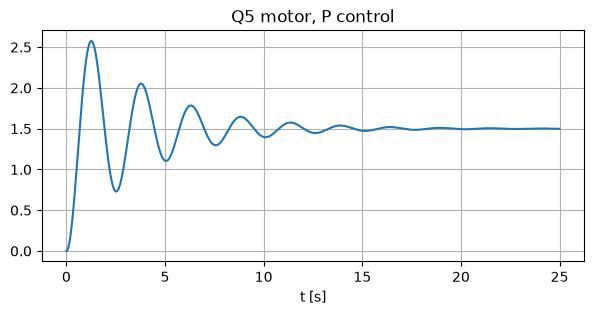

In [50]:
# ---------------- 7F INPUT ----------------
second_order_specs(zeta=0.5, wn=10)                           # <-- CHANGE
zeta_from_OS(10)
pd_design(J=0.5, B=0.1, wn=10, zeta=1)
second_order_from_poly(0.5 * 0.001 * s**2 + 10 * 0.001 * s + 1)     # A2 RLC: ω_n = 44.72, ζ = 0.224
tf_info(1 / (0.05 * s + 0.2), "A1 rotor", explain=False)            # pole -4
for Kp_b1 in (0.5, 1, 2, 20):                                       # B1: P control on A1 → -14, -24, -44, -404
    tf_info(Kp_b1 / (0.05 * s + 0.2 + Kp_b1), f"B1 Kp={Kp_b1}", explain=False)
G_cl_q5 = feedback(kp_q52 * G_motor)                                # Q5 motor with P control, unity feedback
step_response(G_cl_q5, t_end=25, amplitude=1.5, title_="Q5 motor, P control");

### 7G. Laplace, inverse Laplace, initial and final value; the DC motor exercise

In [51]:
# ---------------- 7G INPUT ----------------
final_value(5 / (s * (s**2 + 3 * s + 2)))                            # → 2.5
initial_value(5 / (s + 2))                                           # → 5
inverse_laplace(5 / (s * (s + 1) * (s + 2)))                         # → 5/2 - 5 e^-t + 5/2 e^-2t
laplace(sp.exp(-2 * t) * sp.sin(3 * t))                              # → 3/((s+2)² + 9)
# DC motor exercise: R = 2, L = 2 mH, Km = Kb = 0.08, Jm = 2e-4, Bm = 2e-3 → reduced plant 200/(s(s+26))
dc_motor_tf(0, 2, 0.08, 0.08, 2e-4, 2e-3, explain=False)
dc_motor_tf(0.002, 2, 0.08, 0.08, 2e-4, 2e-3, explain=False);       # with L: electrical pole ≈ -R/L = -1000


final value theorem:  f(∞) = lim_{s→0} s·F(s)
s·F(s) =


     5      
────────────
 2          
s  + 3⋅s + 2

   · every pole of s·F(s) has Re < 0 → the theorem applies ✔

✅ ANSWER: f(∞) = 5/2 ≈ 2.5

✅ ANSWER: f(0+) = 5

inverse Laplace transform
partial fractions:


    5         5      5 
───────── - ───── + ───
2⋅(s + 2)   s + 1   2⋅s

f(t) =


               -2⋅t
5      -t   5⋅ℯ    
─ - 5⋅ℯ   + ───────
2              2   


Laplace transform


     3      
────────────
       2    
(s + 2)  + 9


✅ ANSWER: Θ/V: 2 poles: -26, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)

✅ ANSWER: Θ/V: 3 poles: -983.5656, -26.4344, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)


---
# 8. Dynamics: Euler–Lagrange (project part 4; conceptual in the MCQ)

### Theory in 60 seconds
* $\mathcal K=\sum_i\big(\tfrac12m_iv_{c_i}^Tv_{c_i}+\tfrac12\omega_i^T R_iI_iR_i^T\omega_i\big)=\tfrac12\dot q^TD(q)\dot q$, $\qquad\mathcal P=-\sum_i m_i\,\mathbf g^Tr_{c_i}$.
* $D(q)\ddot q+C(q,\dot q)\dot q+g(q)=\tau$, with $D=\dfrac{\partial^2\mathcal K}{\partial\dot q^2}$, $g_k=\dfrac{\partial\mathcal P}{\partial q_k}$, $C_{kj}=\sum_i c_{ijk}\dot q_i$, $c_{ijk}=\tfrac12\big(\partial_{q_i}d_{kj}+\partial_{q_j}d_{ki}-\partial_{q_k}d_{ij}\big)$.
* Inertias about the centre of mass: box $a\times b\times c$: $I_{xx}=\frac m{12}(b^2+c^2)$, …; rod: $\frac{ml^2}{12}$ (centre), $\frac{ml^2}{3}$ (end). Parallel axes: $I=I_c+md^2$.
* At rest ($\dot q=0$) only $D\ddot q+g$ remain; holding still needs $\tau=g(q)$ (the gravity load of cell 4E).

`robot_dynamics` does the whole recipe from a DH table: centres of mass → $v_c$ and $\omega$ (from $S(\omega)=\dot RR^T$) → $\mathcal K,\mathcal P$ → $D, C, g$.

In [52]:
# =====================================================================
# 8. TOOLS: Euler–Lagrange, energies of rigid links, inertia helpers, numeric τ
# =====================================================================

def euler_lagrange(q, qd, K, P, explain=None):
    """Equations of motion from the energies.
    q, qd : lists of sympy symbols (joint variables and joint rates); K, P : kinetic and potential energy.
    Returns D(q), C(q, q̇), g(q) with D q̈ + C q̇ + g = τ (Christoffel symbols)."""
    n = len(q)
    D = sp.simplify(sp.hessian(K, qd))
    C = sp.zeros(n, n)
    for k in range(n):
        for j in range(n):
            C[k, j] = sp.simplify(sum(sp.Rational(1, 2) * (sp.diff(D[k, j], q[i]) + sp.diff(D[k, i], q[j])
                                                           - sp.diff(D[i, j], q[k])) * qd[i] for i in range(n)))
    g = sp.simplify(sp.Matrix([sp.diff(P, qi) for qi in q]))
    if _ex(explain):
        title("Euler–Lagrange:  D(q) q̈ + C(q, q̇) q̇ + g(q) = τ")
        pm("D(q)", D); pm("C(q, q̇)", C); pm("g(q)", g)
        qdd = sp.Matrix(sp.symbols(f'qdd1:{n+1}'))
        pm("τ (with q̈ = qdd)", sp.simplify(D * qdd + C * sp.Matrix(qd) + g))
    return D, C, g


def link_energy(T0i, m, r_local, I_local, q, qd, g_vec):
    """Kinetic and potential energy of ONE rigid link.
    T0i     : 4x4 sympy pose of the link's frame {i} (robot.frames(q_symbols)[i])
    m       : mass;  r_local : centre of mass in frame {i} coordinates, e.g. (-l/2, 0, 0)
    I_local : 3x3 inertia about the centre of mass, axes parallel to frame {i}, e.g. sp.diag(0, 0, I1)
    g_vec   : gravity in frame 0, e.g. (0, 0, -g)
    K = ½ m v_cᵀ v_c + ½ ωᵀ (R I Rᵀ) ω,  v_c = (∂p_c/∂q) q̇,  S(ω) = Ṙ Rᵀ;   P = -m g_vecᵀ p_c."""
    T0i = sp.Matrix(T0i)
    R = T0i[:3, :3]
    pc = (T0i * sp.Matrix([*r_local, 1]))[:3, 0]
    v = pc.jacobian(list(q)) * sp.Matrix(qd)
    Rdot = sp.zeros(3, 3)
    for qj, qdj in zip(q, qd):
        Rdot += sp.diff(R, qj) * qdj
    S = sp.simplify(Rdot * R.T)
    w = sp.Matrix([S[2, 1], S[0, 2], S[1, 0]])
    K = sp.Rational(1, 2) * m * (v.T * v)[0] + sp.Rational(1, 2) * (w.T * R * sp.Matrix(I_local) * R.T * w)[0]
    P = -m * (sp.Matrix(list(g_vec)).T * pc)[0]
    return sp.simplify(K), sp.simplify(P)


def robot_dynamics(robot, links, q, qd, g_vec, explain=None):
    """D, C, g of a robot from its DH table.
    links : one tuple per link (m, r_com_in_link_frame, I_about_com_in_link_axes)."""
    Ts = robot.frames(q)
    K = 0; P = 0
    for i, (m, r_, I_) in enumerate(links, 1):
        Ki_, Pi_ = link_energy(Ts[i], m, r_, I_, q, qd, g_vec)
        K += Ki_; P += Pi_
    if _ex(explain):
        title(f"dynamics of {robot.name}")
        pm("K", sp.simplify(K)); pm("P", sp.simplify(P))
    return euler_lagrange(q, qd, sp.simplify(K), sp.simplify(P), explain)


def eval_tau(D, C, g, q, qd, q_val, qd_val, qdd_val, params=None, explain=None):
    """Numeric joint torques τ = D q̈ + C q̇ + g at given q, q̇, q̈ (params = {symbol: value})."""
    subs = dict(zip(q, q_val)); subs.update(dict(zip(qd, qd_val))); subs.update(params or {})
    Dn = np.array(D.subs(subs).evalf(), dtype=float)
    Cn = np.array(C.subs(subs).evalf(), dtype=float)
    gn = np.array(g.subs(subs).evalf(), dtype=float).ravel()
    tau = Dn @ np.asarray(qdd_val, dtype=float) + Cn @ np.asarray(qd_val, dtype=float) + gn
    if _ex(explain):
        title("numeric torques τ = D q̈ + C q̇ + g")
        pm("D", Dn); pm("C q̇", Cn @ np.asarray(qd_val, dtype=float)); pm("g", gn)
    answer(f"τ = {clean(tau)}")
    return tau


def kinetic_point_mass(m, p, q, qd):
    """½ m |v|² of a point mass at position p(q) (a sympy 3-vector)."""
    v = sp.Matrix(p).jacobian(list(q)) * sp.Matrix(qd)
    return sp.Rational(1, 2) * m * (v.T * v)[0]


def I_box(m, a, b, c):
    """Box a x b x c about its centre: (Ixx, Iyy, Izz) = m/12 (b²+c², a²+c², a²+b²)."""
    return m * (b**2 + c**2) / 12, m * (a**2 + c**2) / 12, m * (a**2 + b**2) / 12


def I_rod(m, l, about="centre"):
    """Slender rod: m l²/12 about the centre, m l²/3 about one end."""
    return m * l**2 / 12 if about == "centre" else m * l**2 / 3


print("Section 8 tools loaded ✔")

Section 8 tools loaded ✔


### 8A. Planar 2R in a vertical plane (masses $m_i$ at $l_{c_i}$, inertias $I_i$): the textbook closed form
Expected: $D=\begin{bmatrix}a+2b\cos q_2&d+b\cos q_2\\d+b\cos q_2&d\end{bmatrix}$ with $a=I_1+I_2+m_1l_{c1}^2+m_2(l_1^2+l_{c2}^2)$, $b=m_2l_1l_{c2}$, $d=I_2+m_2l_{c2}^2$.

In [53]:
# ---------------- 8A INPUT ----------------
qa, qb, qda, qdb = sp.symbols('q1 q2 qd1 qd2', real=True)
m1, m2, lc1, lc2, I1, I2, g0 = sp.symbols('m1 m2 l_c1 l_c2 I1 I2 g', positive=True)
arm_dyn = Robot([(0, 0, l1, 0), (0, 0, l2, 0)], 'RR', name='planar 2R (vertical plane)')
D2r, C2r, g2r = robot_dynamics(arm_dyn,
                               links=[(m1, (lc1 - l1, 0, 0), sp.diag(0, 0, I1)),    # frame 1 sits at the END of link 1
                                      (m2, (lc2 - l2, 0, 0), sp.diag(0, 0, I2))],
                               q=[qa, qb], qd=[qda, qdb], g_vec=(0, -g0, 0))


dynamics of planar 2R (vertical plane)
K =


              2      ⎛  2    2                2                                ↪
I₂⋅(qd₁ + qd₂)    m₂⋅⎝l₁ ⋅qd₁  + 2⋅l₁⋅l_c2⋅qd₁ ⋅cos(q₂) + 2⋅l₁⋅l_c2⋅qd₁⋅qd₂⋅co ↪
─────────────── + ──────────────────────────────────────────────────────────── ↪
       2                                                                2      ↪

↪             2    2         2               2    2⎞      2 ⎛         2   ⎞
↪ s(q₂) + l_c2 ⋅qd₁  + 2⋅l_c2 ⋅qd₁⋅qd₂ + l_c2 ⋅qd₂ ⎠   qd₁ ⋅⎝I₁ + l_c1 ⋅m₁⎠
↪ ────────────────────────────────────────────────── + ────────────────────
↪                                                               2          

P =


g⋅(l_c1⋅m₁⋅sin(q₁) + m₂⋅(l₁⋅sin(q₁) + l_c2⋅sin(q₁ + q₂)))


Euler–Lagrange:  D(q) q̈ + C(q, q̇) q̇ + g(q) = τ
D(q) =


⎡              2         ⎛  2                           2⎞                     ↪
⎢I₁ + I₂ + l_c1 ⋅m₁ + m₂⋅⎝l₁  + 2⋅l₁⋅l_c2⋅cos(q₂) + l_c2 ⎠  I₂ + l_c2⋅m₂⋅(l₁⋅c ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎣            I₂ + l_c2⋅m₂⋅(l₁⋅cos(q₂) + l_c2)                        I₂ + l_c2 ↪

↪               ⎤
↪ os(q₂) + l_c2)⎥
↪               ⎥
↪ 2             ⎥
↪  ⋅m₂          ⎦

... (2 outputs left out)

g(q) =


⎡g⋅(l_c1⋅m₁⋅cos(q₁) + m₂⋅(l₁⋅cos(q₁) + l_c2⋅cos(q₁ + q₂)))⎤
⎢                                                         ⎥
⎣                 g⋅l_c2⋅m₂⋅cos(q₁ + q₂)                  ⎦

τ (with q̈ = qdd) =


⎡                                                                              ↪
⎢g⋅(l_c1⋅m₁⋅cos(q₁) + m₂⋅(l₁⋅cos(q₁) + l_c2⋅cos(q₁ + q₂))) - l₁⋅l_c2⋅m₂⋅qd₁⋅qd ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎣                                                           g⋅l_c2⋅m₂⋅cos(q₁ + ↪

↪                                                       ⎛              2       ↪
↪ ₂⋅sin(q₂) - l₁⋅l_c2⋅m₂⋅qd₂⋅(qd₁ + qd₂)⋅sin(q₂) + qdd₁⋅⎝I₁ + I₂ + l_c1 ⋅m₁ +  ↪
↪                                                                              ↪
↪                      2                                                       ↪
↪  q₂) + l₁⋅l_c2⋅m₂⋅qd₁ ⋅sin(q₂) + qdd₁⋅(I₂ + l_c2⋅m₂⋅(l₁⋅cos(q₂) + l_c2)) + q ↪

↪    ⎛  2                           2⎞⎞                                        ↪
↪ m₂⋅⎝l₁  + 2⋅l₁⋅l_c2⋅cos(q₂) + l_c2 ⎠⎠ + qdd₂⋅(I₂ + l_c2⋅m₂⋅(l₁⋅cos(q₂) + l_c ↪
↪                         

### 8B. Spatial 2-link arm (control exercises): vertical joint 1, horizontal joint 2, two rods of mass $m$ and length $l$
DH $(q_1,0,0,90°)$, $(q_2,l,0,0)$. Rod 1 lies along $z_1$ (centre at $l/2$), rod 2 along $y_2$ (centre at $l/2$).
Numeric check: $m=2$, $l=3$, $q=(\pi/5,\pi/3)$, $\dot q=(3,7)$, $\ddot q=(4,9)$ → $\tau=(564.54,\,-12.87)$ N·m.

In [54]:
# ---------------- 8B INPUT ----------------
mr, lr = sp.symbols('m l', positive=True)
arm_sp = Robot([(0, 0, 0, 90), (0, lr, 0, 0)], 'RR', name='spatial 2-link')
D_sp, C_sp, g_sp = robot_dynamics(arm_sp,
                                  links=[(mr, (0, 0, lr / 2), sp.diag(mr * lr**2 / 12, mr * lr**2 / 12, 0)),   # rod along z1
                                         (mr, (0, lr / 2, 0), sp.diag(mr * lr**2 / 12, 0, mr * lr**2 / 12))],  # rod along y2
                                  q=[qa, qb], qd=[qda, qdb], g_vec=(0, 0, -g0))
tau_sp = eval_tau(D_sp, C_sp, g_sp, [qa, qb], [qda, qdb],
                  q_val=[np.pi / 5, np.pi / 3], qd_val=[3, 7], qdd_val=[4, 9],     # <-- CHANGE
                  params={mr: 2, lr: 3, g0: 9.81})


dynamics of spatial 2-link
K =


 2   ⎛   2    2            2                          2⎞
l ⋅m⋅⎝qd₁ ⋅sin (q₂) + 4⋅qd₁  - 3⋅qd₁⋅qd₂⋅cos(q₂) + qd₂ ⎠
────────────────────────────────────────────────────────
                           6                            

P =


g⋅l⋅m⋅cos(q₂)
─────────────
      2      


Euler–Lagrange:  D(q) q̈ + C(q, q̇) q̇ + g(q) = τ
D(q) =


⎡ 2   ⎛   2        ⎞    2           ⎤
⎢l ⋅m⋅⎝sin (q₂) + 4⎠  -l ⋅m⋅cos(q₂) ⎥
⎢───────────────────  ──────────────⎥
⎢         3                 2       ⎥
⎢                                   ⎥
⎢    2                      2       ⎥
⎢  -l ⋅m⋅cos(q₂)           l ⋅m     ⎥
⎢  ──────────────          ────     ⎥
⎣        2                  3       ⎦

... (3 outputs left out)

⎡       0       ⎤
⎢               ⎥
⎢-g⋅l⋅m⋅sin(q₂) ⎥
⎢───────────────⎥
⎣       2       ⎦

τ (with q̈ = qdd) =


⎡ 2   ⎛                           2                                            ↪
⎢l ⋅m⋅⎝2⋅qd₁⋅qd₂⋅sin(2⋅q₂) + 3⋅qd₂ ⋅sin(q₂) - qdd₁⋅cos(2⋅q₂) + 9⋅qdd₁ - 3⋅qdd₂ ↪
⎢───────────────────────────────────────────────────────────────────────────── ↪
⎢                                          6                                   ↪
⎢                                                                              ↪
⎢             ⎛                    2                                        ⎞  ↪
⎢         l⋅m⋅⎝-3⋅g⋅sin(q₂) - l⋅qd₁ ⋅sin(2⋅q₂) - 3⋅l⋅qdd₁⋅cos(q₂) + 2⋅l⋅qdd₂⎠  ↪
⎢         ───────────────────────────────────────────────────────────────────  ↪
⎣                                          6                                   ↪

↪         ⎞⎤
↪ ⋅cos(q₂)⎠⎥
↪ ─────────⎥
↪          ⎥
↪          ⎥
↪          ⎥
↪          ⎥
↪          ⎥
↪          ⎦


numeric torques τ = D q̈ + C q̇ + g
D =
[[28.5 -4.5]
 [-4.5  6. ]]
C q̇ = [491.0364 -23.3827]
g = [  0.     -25.4871]

✅ ANSWER: τ = [564.5364 -12.8698]


### 8C. Week-6 exercise: planar 2R made of two bars $L\times0.1L\times0.1L$ (mass $m$)
Expected $D=\dfrac{mL^2}{1200}\begin{bmatrix}2002+1200\cos\theta_2&401+600\cos\theta_2\\401+600\cos\theta_2&401\end{bmatrix}$.

In [55]:
# ---------------- 8C INPUT ----------------
mb, Lb = sp.symbols('m L', positive=True)
Izz_bar = I_box(mb, Lb, Lb / 10, Lb / 10)[2]                       # 101 m L²/1200 about the centre
bars = Robot([(0, 0, Lb, 0), (0, 0, Lb, 0)], 'RR', name='week-6 bars')
D_w6, C_w6, g_w6 = robot_dynamics(bars, links=[(mb, (-Lb / 2, 0, 0), sp.diag(0, 0, Izz_bar)),
                                               (mb, (-Lb / 2, 0, 0), sp.diag(0, 0, Izz_bar))],
                                  q=[qa, qb], qd=[qda, qdb], g_vec=(0, -g0, 0), explain=False)
pm("D · 1200/(m L²)", sp.simplify(D_w6 * 1200 / (mb * Lb**2)))

D · 1200/(m L²) =


⎡1200⋅cos(q₂) + 2002  600⋅cos(q₂) + 401⎤
⎢                                      ⎥
⎣ 600⋅cos(q₂) + 401          401       ⎦

---
# 9. General helpers: any matrix, any linear system, any equations
For the questions that fit no template: build the equations yourself, then let these solve them.

In [56]:
# =====================================================================
# 9. TOOLS: matrix facts, linear systems, symbolic / numeric equation solving
# =====================================================================

def matrix_info(M, explain=None):
    """Everything about a matrix: size, rank, det, inverse, eigenvalues, symmetric? orthogonal?"""
    if isinstance(M, sp.MatrixBase) or _is_sym(*np.ravel(np.asarray(M, dtype=object))):
        M = sp.Matrix(M)
        title("matrix facts (symbolic)")
        pm("M", M)
        if M.shape[0] == M.shape[1]:
            pm("det M", sp.simplify(M.det()))
            if sp.simplify(M.det()) != 0:
                pm("M⁻¹", sp.simplify(M.inv()))
            pm("eigenvalues {value: multiplicity}", M.eigenvals())
        return M
    A = np.asarray(M, dtype=float)
    out = {"shape": A.shape, "rank": int(np.linalg.matrix_rank(A))}
    if _ex(explain):
        title("matrix facts")
        pm("M", A)
        note(f"shape {A.shape}, rank {out['rank']}")
    if A.shape[0] == A.shape[1]:
        out["det"] = float(np.linalg.det(A))
        out["eigenvalues"] = np.linalg.eigvals(A)
        out["symmetric"] = bool(np.allclose(A, A.T))
        out["orthogonal"] = bool(np.allclose(A.T @ A, np.eye(len(A))))
        if _ex(explain):
            note(f"det = {out['det']:.6g}" + ("  → singular (no inverse)" if abs(out['det']) < 1e-12 else ""))
            note("eigenvalues = " + ", ".join(fmt_c(e_) for e_ in out["eigenvalues"]))
            note(f"symmetric: {out['symmetric']},  orthogonal (Mᵀ M = I): {out['orthogonal']}")
            if abs(out['det']) > 1e-12:
                pm("M⁻¹", np.linalg.inv(A))
    shown = lambda v: ('[' + ', '.join(fmt_c(e_) for e_ in v) + ']' if isinstance(v, np.ndarray)
                       else num(v, 6) if isinstance(v, float) else str(v))
    answer(", ".join(f"{k} = {shown(v)}" for k, v in out.items()))
    return out


def lin_solve(A, b, explain=None):
    """Solve A x = b (square A), printing the check A x = b."""
    A = np.asarray(A, dtype=float); b = np.asarray(b, dtype=float)
    x = np.linalg.solve(A, b)
    if _ex(explain):
        title("linear system  A x = b")
        pm("A", A); pm("b", b)
        note(f"det A = {np.linalg.det(A):.6g}")
        note(f"check A x = {clean(A @ x)}")
    answer(f"x = {clean(x, 6)}")
    return x


def solve_eqs(eqs, unknowns, guess=None, explain=None):
    """Solve equations: exact (sympy.solve) first; with a `guess` (or if exact fails) numeric (sympy.nsolve).
    eqs : list of sympy expressions (= 0) or sp.Eq(...);  unknowns : list of symbols;  guess : list of numbers."""
    eqs = [e_.lhs - e_.rhs if isinstance(e_, sp.Equality) else e_ for e_ in eqs]
    if guess is None:
        try:
            sol = sp.solve(eqs, unknowns, dict=True)
            if sol:
                if _ex(explain):
                    title("equations solved exactly")
                    for s_ in sol:
                        display(s_)
                answer(" | ".join(str({k: (v if not v.is_number else sp.N(v, 6)) for k, v in s_.items()}) for s_ in sol))
                return sol
        except Exception:
            pass
        guess = [1.0] * len(unknowns)
    sol = sp.nsolve(eqs, unknowns, guess)
    res = dict(zip(unknowns, [float(v) for v in sol]))
    answer(f"numeric solution from the guess {guess}: {res}")
    return res


def deg(x):
    """radians → degrees"""
    return np.degrees(x)


def rad(x):
    """degrees → radians"""
    return np.radians(x)


print("Section 9 tools loaded ✔")

Section 9 tools loaded ✔


In [57]:
# ---------------- 9 INPUT ----------------
matrix_info([[2, 1], [1, 3]])                                      # det, inverse, eigenvalues    <-- CHANGE
lin_solve([[8, 16, 32], [12, 32, 80], [12, 48, 160]], [-np.pi / 4, 1, 0])   # the 3x3 of Q3.2 → c3, c4, c5
xs, ys = sp.symbols('x y', real=True)
solve_eqs([xs**2 + ys**2 - 4, xs - ys], [xs, ys])                  # exact: (±√2, ±√2)
qq = sp.symbols('qq')
solve_eqs([sp.cos(qq) - qq], [qq], guess=[0.5]);                   # numeric: 0.7391


matrix facts
M =
[[2. 1.]
 [1. 3.]]
   · shape (2, 2), rank 2
   · det = 5
   · eigenvalues = 1.382, 3.618
   · symmetric: True,  orthogonal (Mᵀ M = I): False
M⁻¹ =
[[ 0.6 -0.2]
 [-0.2  0.4]]

✅ ANSWER: shape = (2, 2), rank = 2, det = 5, eigenvalues = [1.382, 3.618], symmetric = True, orthogonal = False

linear system  A x = b
A =
[[  8.  16.  32.]
 [ 12.  32.  80.]
 [ 12.  48. 160.]]
b = [-0.7854  1.      0.    ]
   · det A = 1024
   · check A x = [-0.7854  1.      0.    ]

✅ ANSWER: x = [-1.9817  1.6113 -0.3348]

equations solved exactly


{x: -√2, y: -√2}

{x: √2, y: √2}


✅ ANSWER: {x: -1.41421, y: -1.41421} | {x: 1.41421, y: 1.41421}

✅ ANSWER: numeric solution from the guess [0.5]: {qq: 0.7390851332151607}


---
# 10. Exercise bank: every past exam, weekly exercise and lecture example, solved
Each cell is a **ready template** for one type of question. It solves the original problem, prints the working, then a line
**`📘 OFFICIAL ANSWER`** copied from the official solution, so you can see that the tool reproduces it. For a new exam
question of the same type: copy the cell (or change the lines marked `# <-- CHANGE`) and run it.

| # | Type of question | Source | Official answer reproduced |
|---|---|---|---|
| 10.1 | rotation sequences with symbols; an equivalent sequence; current vs fixed | week 2 P2–P3, lectures 2–3 | ✔ |
| 10.2 | frames read **by observation** and chained ($A^0_1\cdots A^3_4$) | week 2 P6 | ✔ |
| 10.3 | three frames on a box: "transformation from system 1 to 2" | exam 2017 P2 | ✔ |
| 10.4 | $R^0_2$ from $R^0_1$ + a rotation sequence, and $\omega^0_{0,2}$ | exam 2019 P2 | ✔ |
| 10.5 | DH parameters from a full $A$ | exam 2017 P1 | ✔ |
| 10.6 | DH parameters from a **partly known** $A$, then the missing entries | exam 2019 P1 | ✔ |
| 10.7 | DH of a bracket from front / side / top views | exam 2020 P1 | ✔ |
| 10.8 | PUMA 560 DH table and its forward kinematics | exam 2016 P1 | table ✔ |
| 10.9 | robot with a prismatic joint: $T^0_4$ and the tip velocity | exam 2020 P2 | ✔ |
| 10.10 | prismatic + revolute arm with a gripper offset: $T^0_3$ and $J$ | week 4 P4 | ✔ |
| 10.11 | Stanford arm: forward kinematics and yaw-pitch-roll | week 3 P1 | ✔ |
| 10.12 | **the project robot (CourseBot)**: FK, camera frame, IK, Jacobian | project | FK check |
| 10.13 | joint rates with a pseudo-inverse (6×4 Jacobian) | lecture 6 (ball catcher) | ✔ |
| 10.14 | constant-jerk path | exam 2016 P3 | ✔ |
| 10.15 | jerk given as a sine | exam 2017 P3 | ✔ |
| 10.16 | piecewise acceleration in dimensionless time | exam 2019 P3 | ✔ |
| 10.17 | sine acceleration: minimum time for an acceleration limit | exam 2020 P3 | ✔ |
| 10.18 | pixel → camera → world → robot base, then IK | exam 2016 P4.3–4.5 | ✔ |
| 10.19 | task frame from 3 points + camera frame from 3 pixels + object → base | exam 2017 P4 | ✔ (both pixel conventions) |
| 10.20 | task frame, camera on the end-effector, pixel coordinates | exam 2019 P4 | ✔ (both conventions) |
| 10.21 | two task frames, stereo camera, point → base | exam 2020 P4 | ✔ |
| 10.22 | drone, couch and people: sizes and depths from pixels | vision exercises 1–3 | ✔ |
| 10.23 | PI loop: $q=(Fq_r-GD)/N$ and $e_{ss}$ | exam 2017 P5 | ✔ |
| 10.24 | geared motor, $\dot\theta_m/V$ and $e_{ss}$ with a load | exam 2019 P5 | ✔ |
| 10.25 | direct-drive joint with PI: $q=(Fq^\star-H\tau_l)/N$ | exam 2020 P5 | ✔ |
| 10.26 | poles of P / PI / PID loops on a rotor and an RLC circuit | control exercises A–D | ✔ |
| 10.27 | block diagrams with a disturbance, inner loop and bypass | control exercises E1–E2 | ✔ |
| 10.28 | DC motor $\Theta/V$, $\Theta/\tau_\ell$ and PID | control exercise 7.4 | ✔ |
| 10.29 | DC motor model, poles, which P gains are stable | motor exercise (31383) | ✔ |
| 10.30 | why independent joint control works (gear ratio) | control exercise 7.5 | concept |

Also solved elsewhere: MCQ 2025-26 (cells 1A, 1B, 2A/2B, 3A, 4A, 5A, 6A–6D, 7A–7B), exam 2016 P2 (2C), 2016 P4.2 (4F), 2016 P5 (7D),
week 4 P1–P3 (4D, 4F), week 6 dynamics (8C), lecture dynamics example (8B), ball-catcher cubics (5C), VisionExam (6E).

In [58]:
# ---------- the helper used in this section ----------
def official(text):
    """Print the answer of the official solution, to compare with the ✅ line of the tool."""
    if not SILENT:
        print(f"📘 OFFICIAL ANSWER: {text}")


print("exercise bank ready ✔")

exercise bank ready ✔


---
## Frames and rotations
### 10.1 Rotation sequences with symbols (week 2 P2–P3, lectures 2–3)
*Week 2 P2:* rotate $\phi$ about the **world** $x$, then $\psi$ about the **current** $z$, then $\theta$ about the **world** $y$.
*P3:* find a different sequence that gives the same matrix. A product $R_1R_2R_3$ reads left to right as **current** rotations, or right to left as **fixed** rotations.

In [59]:
ph_, ps_, th_ = sp.symbols('phi psi theta', real=True)
R_w2p2 = compose([('rot', 'x', ph_, 'global'), ('rot', 'z', ps_, 'current'), ('rot', 'y', th_, 'global')])[:3, :3]   # <-- CHANGE
R_w2p3 = _quiet(compose, [('rot', 'y', th_, 'current'), ('rot', 'x', ph_, 'current'), ('rot', 'z', ps_, 'current')])[:3, :3]
answer(f"P3: θ about y, then φ about the CURRENT x, then ψ about the CURRENT z gives the same R: {sp.simplify(R_w2p2 - R_w2p3) == sp.zeros(3, 3)}")
official("R = R_y(θ) R_x(φ) R_z(ψ);  P3: rotate θ about y, φ about the current x, ψ about the current z")


compose: a sequence of moves → homogeneous matrix T

▶ move 1: rot x by phi, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Rot_x(phi)

▶ move 2: rot z by psi, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_x(phi) · Rot_z(psi)

▶ move 3: rot y by theta, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Rot_y(theta) · Rot_x(phi) · Rot_z(psi)

▶ final product: fixed moves on the left, current moves on the right
   T = Rot_y(theta) · Rot_x(phi) · Rot_z(psi)
T =


⎡sin(φ)⋅sin(ψ)⋅sin(θ) + cos(ψ)⋅cos(θ)  sin(φ)⋅sin(θ)⋅cos(ψ) - sin(ψ)⋅cos(θ)  s ↪
⎢                                                                              ↪
⎢           sin(ψ)⋅cos(φ)                         cos(φ)⋅cos(ψ)                ↪
⎢                                                                              ↪
⎢sin(φ)⋅sin(ψ)⋅cos(θ) - sin(θ)⋅cos(ψ)  sin(φ)⋅cos(ψ)⋅cos(θ) + sin(ψ)⋅sin(θ)  c ↪
⎢                                                                              ↪
⎣                 0                                     0                      ↪

↪ in(θ)⋅cos(φ)  0⎤
↪                ⎥
↪   -sin(φ)     0⎥
↪                ⎥
↪ os(φ)⋅cos(θ)  0⎥
↪                ⎥
↪      0        1⎦


▶ what the columns mean
   column 1 = x1 seen from frame 0: [sin(phi)*sin(psi)*sin(theta) + cos(psi)*cos(theta), sin(psi)*cos(phi), sin(phi)*sin(psi)*cos(theta) - sin(theta)*cos(psi)]
   column 2 = y1 seen from frame 0: [sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(theta), cos(phi)*cos(psi), sin(phi)*cos(psi)*cos(theta) + sin(psi)*sin(theta)]
   column 3 = z1 seen from frame 0: [sin(theta)*cos(phi), -sin(phi), cos(phi)*cos(theta)]
   column 4 = origin o1 seen from frame 0: [0, 0, 0]

✅ ANSWER: the 4 columns of T above (column 4 = origin of the new frame)



✅ ANSWER: P3: θ about y, then φ about the CURRENT x, then ψ about the CURRENT z gives the same R: True
📘 OFFICIAL ANSWER: R = R_y(θ) R_x(φ) R_z(ψ);  P3: rotate θ about y, φ about the current x, ψ about the current z


In [60]:
# Lecture 2: R_y(45°) then R_z(45°) — both about CURRENT axes, or the second one about the FIXED z
R_cur = _quiet(compose, [('rot', 'y', 45, 'current'), ('rot', 'z', 45, 'current')])[:3, :3]
R_fix = _quiet(compose, [('rot', 'y', 45, 'current'), ('rot', 'z', 45, 'global')])[:3, :3]
pm("both current: R_y45 R_z45", R_cur)
pm("second about the fixed z: R_z45 R_y45", R_fix)
official("[[1/2, -1/2, 1/√2], [1/√2, 1/√2, 0], [-1/2, 1/2, 1/√2]]   and   [[1/2, -1/√2, 1/2], [1/2, 1/√2, 1/2], [-1/√2, 0, 1/√2]]")
# Lecture 3, five steps: θ about current x, φ about current z, α about fixed z, β about current y, δ about fixed x
th5, ph5, al5, be5, de5 = 10, 20, 40, 30, 50                          # example angles [deg]      <-- CHANGE
R_l3 = compose([('rot', 'x', th5, 'current'), ('rot', 'z', ph5, 'current'), ('rot', 'z', al5, 'global'),
                ('rot', 'y', be5, 'current'), ('rot', 'x', de5, 'global')])[:3, :3]
answer(f"equal to R_x(δ) R_z(α) R_x(θ) R_z(φ) R_y(β): {np.allclose(R_l3, rotx(de5) @ rotz(al5) @ rotx(th5) @ rotz(ph5) @ roty(be5))}")
official("R = R_x(δ) R_z(α) R_x(θ) R_z(φ) R_y(β)")

both current: R_y45 R_z45 =
[[ 0.5    -0.5     0.7071]
 [ 0.7071  0.7071  0.    ]
 [-0.5     0.5     0.7071]]
second about the fixed z: R_z45 R_y45 =
[[ 0.5    -0.7071  0.5   ]
 [ 0.5     0.7071  0.5   ]
 [-0.7071  0.      0.7071]]
📘 OFFICIAL ANSWER: [[1/2, -1/2, 1/√2], [1/√2, 1/√2, 0], [-1/2, 1/2, 1/√2]]   and   [[1/2, -1/√2, 1/2], [1/2, 1/√2, 1/2], [-1/√2, 0, 1/√2]]

compose: a sequence of moves → homogeneous matrix T

▶ move 1: rot x by 10, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_x(10°)

▶ move 2: rot z by 20, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_x(10°) · Rot_z(20°)

▶ move 3: rot z by 40, global frame  (FIXED/global axis → multiply on the LEFT)
   · T so far = Rot_z(40°) · Rot_x(10°) · Rot_z(20°)

▶ move 4: rot y by 30, current frame  (CURRENT axis → multiply on the RIGHT)
   · T so far = Rot_z(40°) · Rot_x(10°) · Rot_z(20°) · Rot_y(30°)

▶ move 5: rot x by 50, global frame  (FIXED/global axis → multiply on the 

### 10.2 Frames read by observation, then chained (week 2 P6)
For each frame, write its axes as $\pm$ the axes of the previous frame (or as a tilted vector: here the 30-40-50 triangle gives $\sin\beta=0.6$, $\cos\beta=0.8$) and its origin in the previous frame. Then $A^0_4=A^0_1A^1_2A^2_3A^3_4$.

In [61]:
A01_w6 = _quiet(frame_from_axes, x1='+x0', y1='-y0', z1='-z0', origin=(-0.35, 0.3, 0.1))     # axes of {1} in {0}   <-- CHANGE
A12_w6 = _quiet(frame_from_axes, x1='-y1', y1='-z1', z1='+x1', origin=(0, 0.3, 0.1))          # axes of {2} in {1}
A23_w6 = _quiet(frame_from_axes, x1='+z2', y1=(0.6, -0.8, 0), z1=(0.8, 0.6, 0), origin=(0, 0.5, 0))   # tilted: 0.6/0.8
A34_w6 = _quiet(frame_from_axes, x1='-x3', y1='+y3', z1='-z3', origin=(0.35, 0, 0))
A04_w6 = chain(A01_w6, A12_w6, A23_w6, A34_w6, explain=False)
pm("A04 = A01 A12 A23 A34", A04_w6)
official("A04 = [[-1, 0, 0, 0], [0, 0.6, -0.8, 0], [0, -0.8, -0.6, 0.5], [0, 0, 0, 1]]")

A04 = A01 A12 A23 A34 =
[[-1.   0.   0.   0. ]
 [ 0.   0.6 -0.8  0. ]
 [ 0.  -0.8 -0.6  0.5]
 [ 0.   0.   0.   1. ]]
📘 OFFICIAL ANSWER: A04 = [[-1, 0, 0, 0], [0, 0.6, -0.8, 0], [0, -0.8, -0.6, 0.5], [0, 0, 0, 1]]


### 10.3 Three frames on a box (exam 2017 P2)
Box $A\times C\times B$ (length along $x_1$, depth along $y_1$, height along $z_1$). Read from the figure, in frame-1 axes:
frame 2 at $(A,0,0)$ with $x_2=+y_1$, $y_2=-z_1$, $z_2=-x_1$; frame 3 at $(A,C,B)$ with $x_3=-z_1$, $y_3=-y_1$, $z_3=-x_1$.

**Convention of the official solution:** "the transformation from system 1 to 2" is $T^2_1$: it converts frame-1 coordinates into frame-2 coordinates ($p^2=T^2_1p^1$), i.e. the pose of frame 1 seen from frame 2.

In [62]:
A_bx, B_bx, C_bx = sp.symbols('A B C', positive=True)                                                   # box sizes
T1_2 = _quiet(frame_from_axes, x1='+y', y1='-z', z1='-x', origin=(A_bx, 0, 0))        # frame 2 in frame-1 axes   <-- CHANGE
T1_3 = _quiet(frame_from_axes, x1='-z', y1='-y', z1='-x', origin=(A_bx, C_bx, B_bx))  # frame 3 in frame-1 axes   <-- CHANGE
pm("from 1 to 2:  T^2_1 = (T^1_2)^-1", Hinv(T1_2))
pm("from 2 to 3:  T^3_2 = (T^1_3)^-1 T^1_2", sp.simplify(Hinv(T1_3) * T1_2))
pm("from 3 to 1:  T^1_3", T1_3)
official("[[0,1,0,0],[0,0,-1,0],[-1,0,0,A]] | [[0,1,0,B],[-1,0,0,C],[0,0,1,0]] | [[0,0,-1,A],[0,-1,0,C],[-1,0,0,B]]")

from 1 to 2:  T^2_1 = (T^1_2)^-1 =


⎡0   1  0   0⎤
⎢            ⎥
⎢0   0  -1  0⎥
⎢            ⎥
⎢-1  0  0   A⎥
⎢            ⎥
⎣0   0  0   1⎦

from 2 to 3:  T^3_2 = (T^1_3)^-1 T^1_2 =


⎡0   1  0  B⎤
⎢           ⎥
⎢-1  0  0  C⎥
⎢           ⎥
⎢0   0  1  0⎥
⎢           ⎥
⎣0   0  0  1⎦

from 3 to 1:  T^1_3 =


⎡0   0   -1  A⎤
⎢             ⎥
⎢0   -1  0   C⎥
⎢             ⎥
⎢-1  0   0   B⎥
⎢             ⎥
⎣0   0   0   1⎦

📘 OFFICIAL ANSWER: [[0,1,0,0],[0,0,-1,0],[-1,0,0,A]] | [[0,1,0,B],[-1,0,0,C],[0,0,1,0]] | [[0,0,-1,A],[0,-1,0,C],[-1,0,0,B]]


### 10.4 $R^0_2$ and the angular velocity $\omega^0_{0,2}$ (exam 2019 P2)
$R^0_1=\begin{bmatrix}0&1&0\\0&0&1\\1&0&0\end{bmatrix}$. $R^1_2$: $\theta_1$ about the **fixed** $x$, then $\theta_2$ about the **current** $y$, then $\theta_3$ about the **current** $z$. Use joint angles that are functions of time, then $S(\omega)=\dot RR^T$.

In [63]:
th1f, th2f, th3f = [sp.Function(f'theta{i}')(t) for i in (1, 2, 3)]
R01_19 = sp.Matrix([[0, 1, 0], [0, 0, 1], [1, 0, 0]])                                                      # <-- CHANGE
R12_19 = _quiet(compose, [('rot', 'x', th1f, 'global'), ('rot', 'y', th2f, 'current'), ('rot', 'z', th3f, 'current')])[:3, :3]
R02_19 = sp.simplify(R01_19 * R12_19)
pm("R02 = R01 · R_x(θ1) R_y(θ2) R_z(θ3)", R02_19)
w02_19 = omega_from_R(R02_19, explain=False)
pm("ω^0_{0,2}", w02_19)
official("ωx = cos θ1·θ2' - sin θ1 cos θ2·θ3',  ωy = sin θ1·θ2' + cos θ1 cos θ2·θ3',  ωz = θ1' + sin θ2·θ3'")

R02 = R01 · R_x(θ1) R_y(θ2) R_z(θ3) =


⎡sin(θ₁(t))⋅sin(θ₂(t))⋅cos(θ₃(t)) + sin(θ₃(t))⋅cos(θ₁(t))  -sin(θ₁(t))⋅sin(θ₂( ↪
⎢                                                                              ↪
⎢sin(θ₁(t))⋅sin(θ₃(t)) - sin(θ₂(t))⋅cos(θ₁(t))⋅cos(θ₃(t))  sin(θ₁(t))⋅cos(θ₃(t ↪
⎢                                                                              ↪
⎣                 cos(θ₂(t))⋅cos(θ₃(t))                                     -s ↪

↪ t))⋅sin(θ₃(t)) + cos(θ₁(t))⋅cos(θ₃(t))  -sin(θ₁(t))⋅cos(θ₂(t))⎤
↪                                                               ⎥
↪ )) + sin(θ₂(t))⋅sin(θ₃(t))⋅cos(θ₁(t))   cos(θ₁(t))⋅cos(θ₂(t)) ⎥
↪                                                               ⎥
↪ in(θ₃(t))⋅cos(θ₂(t))                          sin(θ₂(t))      ⎦

ω^0_{0,2} =


⎡                        d                      d        ⎤
⎢- sin(θ₁(t))⋅cos(θ₂(t))⋅──(θ₃(t)) + cos(θ₁(t))⋅──(θ₂(t))⎥
⎢                        dt                     dt       ⎥
⎢                                                        ⎥
⎢            d                                 d         ⎥
⎢ sin(θ₁(t))⋅──(θ₂(t)) + cos(θ₁(t))⋅cos(θ₂(t))⋅──(θ₃(t)) ⎥
⎢            dt                                dt        ⎥
⎢                                                        ⎥
⎢                       d           d                    ⎥
⎢            sin(θ₂(t))⋅──(θ₃(t)) + ──(θ₁(t))            ⎥
⎣                       dt          dt                   ⎦

📘 OFFICIAL ANSWER: ωx = cos θ1·θ2' - sin θ1 cos θ2·θ3',  ωy = sin θ1·θ2' + cos θ1 cos θ2·θ3',  ωz = θ1' + sin θ2·θ3'


---
## DH parameters and forward kinematics
### 10.5 DH parameters from a full matrix (exam 2017 P1)

In [64]:
dh_from_A([[0, -1 / 2, np.sqrt(3) / 2, 0],                     # <-- CHANGE
           [1, 0, 0, 2],
           [0, np.sqrt(3) / 2, 1 / 2, 0],
           [0, 0, 0, 1]])
official("θ = π/2, d = 0, a = 2, α = π/3")


DH parameters from one A matrix
   · θ = atan2(A21, A11) = atan2(1, 0) = 90°
   · α = atan2(A32, A33) = atan2(0.866, 0.5) = 60°
   · d = A34 = 0
   · a = A14 cosθ + A24 sinθ = 2
   · rebuilt A matches ✔ (a valid DH matrix)

✅ ANSWER: θ = 90°, d = 0, a = 2, α = 60°
📘 OFFICIAL ANSWER: θ = π/2, d = 0, a = 2, α = π/3


### 10.6 DH parameters from a partly known matrix (exam 2019 P1)
$A=\begin{bmatrix}?&?&-3/4&1\\?&1/4&?&\sqrt3\\0&?&?&1/3\\0&0&0&1\end{bmatrix}$. Type `None` for every `?`.

In [65]:
sols_19p1 = dh_from_partial([[None, None, -sp.Rational(3, 4), 1],          # <-- CHANGE
                             [None, sp.Rational(1, 4), None, sp.sqrt(3)],
                             [0, None, None, sp.Rational(1, 3)]])
official("d = 1/3, θ = π/3 (60°), α = -π/3 (300°), a = 2;  A = [[1/2, -√3/4, -3/4, 1], [√3/2, 1/4, √3/4, √3], [0, -√3/2, 1/2, 1/3]]")


DH parameters from a partly known matrix
   · known entries: A13 = -0.75, A14 = 1, A22 = 0.25, A24 = 1.7321, A31 = 0, A34 = 0.3333
   · model: [[cθ, -sθcα, sθsα, a cθ], [sθ, cθcα, -cθsα, a sθ], [0, sα, cα, d]]

▶ solution 1: θ = 60°, d = 0.3333, a = 2, α = 300° (= -60°)
   complete matrix =
[[ 0.5    -0.433  -0.75    1.    ]
 [ 0.866   0.25    0.433   1.7321]
 [ 0.     -0.866   0.5     0.3333]
 [ 0.      0.      0.      1.    ]]

▶ solution 2: θ = 240°, d = 0.3333, a = -2, α = 120° (= 120°)
   complete matrix =
[[-0.5    -0.433  -0.75    1.    ]
 [-0.866   0.25    0.433   1.7321]
 [ 0.      0.866  -0.5     0.3333]
 [ 0.      0.      0.      1.    ]]

✅ ANSWER: θ = 60°, d = 0.3333, a = 2, α = 300° | θ = 240°, d = 0.3333, a = -2, α = 120°
📘 OFFICIAL ANSWER: d = 1/3, θ = π/3 (60°), α = -π/3 (300°), a = 2;  A = [[1/2, -√3/4, -3/4, 1], [√3/2, 1/4, √3/4, √3], [0, -√3/2, 1/2, 1/3]]


### 10.7 DH of a bracket from front / side / top views (exam 2020 P1)
Height $h=400$ mm, equilateral triangle of side $\ell=200$ mm in the top view. From the views: $z_0$ up, $x_0$ to the right;
$x_1$ is horizontal at 60° from $x_0$; $z_1$ is horizontal and perpendicular to $x_1$; $o_1$ is $h$ above $o_0$ and $\ell\sin60°$ out along $x_1$.

In [66]:
l_br, h_br = 200, 400                                          # mm                                <-- CHANGE
c60, s60 = np.cos(np.radians(60)), np.sin(np.radians(60))
table_20p1 = dh_from_frames([((0, 0, 0), '+X', '+Z'),
                             ((l_br * s60 * c60, l_br * s60 * s60, h_br), (c60, s60, 0), (-s60, c60, 0))])
pm("T01", Robot(table_20p1, 'R').frames()[-1])
official("θ = π/3, d = h = 400, a = ℓ sin(π/3) = 100√3 = 173.2, α = -π/2;  T01 = [[0.5, 0, -0.866, 86.6], [0.866, 0, 0.5, 150], [0, -1, 0, 400]]")


DH table from the frames read off the figure

▶ row 1: frame 0 → frame 1
   · z0 = +Z, x0 = +X  |  z1 = [-0.866  0.5    0.   ], x1 = [0.5   0.866 0.   ]
   · o1 - o0 = [ 86.6025 150.     400.    ]
   · θ1 = angle from x0 to x1 about z0  = 60°
   · d1 = (o1 - o0)·z0                 = 400
   · a1 = (o1 - o0)·x1                   = 173.2051
   · α1 = angle from z0 to z1 about x1  = -90°

▶ check: rebuild the frames from this table and compare with the figure
   · all frames reproduced ✔

✅ ANSWER: DH table
    i |    theta |        d |        a |    alpha
    1 |       60 |      400 | 173.2051 |      -90
T01 =
[[  0.5      0.      -0.866   86.6025]
 [  0.866    0.       0.5    150.    ]
 [  0.      -1.       0.     400.    ]
 [  0.       0.       0.       1.    ]]
📘 OFFICIAL ANSWER: θ = π/3, d = h = 400, a = ℓ sin(π/3) = 100√3 = 173.2, α = -π/2;  T01 = [[0.5, 0, -0.866, 86.6], [0.866, 0, 0.5, 150], [0, -1, 0, 400]]


### 10.8 PUMA 560 (exam 2016 P1)
The official DH table, as a template. Symbolic link lengths $l_1\dots l_4$.

In [67]:
lp1, lp2, lp3, lp4 = sp.symbols('l1 l2 l3 l4', positive=True)
puma560 = Robot([(0, 0, 0, 90), (0, -lp2, lp1, 0), (0, 0, 0, -90),           # <-- CHANGE: (θ, d, a, α) per joint
                 (0, lp3, 0, 90), (0, 0, 0, 90), (0, lp4, 0, 0)], 'RRRRRR', name='PUMA 560 (exam 2016)')
puma560.show_table()
pm("T06 at q = 0", puma560.frames()[-1])
official("a = (0, l1, 0, 0, 0, 0), d = (0, -l2, 0, l3, 0, l4), α = (π/2, 0, -π/2, π/2, π/2, 0), θ = q1..q6")

DH table of PUMA 560 (exam 2016)  (angles in deg):
    i type |      theta |          d |          a |    alpha
    1    R |      0+q1* |          0 |          0 |       90
    2    R |      0+q2* |        -l2 |         l1 |        0
    3    R |      0+q3* |          0 |          0 |      -90
    4    R |      0+q4* |         l3 |          0 |       90
    5    R |      0+q5* |          0 |          0 |       90
    6    R |      0+q6* |         l4 |          0 |        0
T06 at q = 0 =


⎡1  0   0     l₁   ⎤
⎢                  ⎥
⎢0  -1  0     l₂   ⎥
⎢                  ⎥
⎢0  0   -1  l₃ - l₄⎥
⎢                  ⎥
⎣0  0   0      1   ⎦

📘 OFFICIAL ANSWER: a = (0, l1, 0, 0, 0, 0), d = (0, -l2, 0, l3, 0, l4), α = (π/2, 0, -π/2, π/2, π/2, 0), θ = q1..q6


### 10.9 A robot with a prismatic joint: $T^0_4$ and the tip velocity (exam 2020 P2)
DH: $(\theta_1,100,0,90°)$, $(90°,d_2,0,90°)$ prismatic, $(\theta_3,0,60,90°)$, $(\theta_4,0,0,90°)$. Pose $\theta_1=135°$, $d_2=200$ mm, $\theta_3=45°$, $\theta_4=-60°$; only joint 1 moves, $\dot\theta_1=0.0025\pi$ rad/s.

In [68]:
r20p2 = Robot([(0, 100, 0, 90), (90, 0, 0, 90), (0, 0, 60, 90), (0, 0, 0, 90)], 'RPRR', name='exam 2020 P2')   # <-- CHANGE
q20p2 = [135, 200, 45, -60]                                                                                  # <-- CHANGE
T04_20 = r20p2.frames(q20p2)[-1]
pm("T04", T04_20)
J20p2 = r20p2.jacobian(q20p2, explain=False)
v04_20 = apply_jacobian(J20p2[:3], [0.0025 * np.pi, 0, 0, 0])                                                 # <-- CHANGE: joint rates
official("T04 = [[0.8623, -0.4999, -0.0795, 171.4], [-0.3623, -0.4999, -0.7865, 171.4], [0.3535, 0.7071, -0.6123, 142.4]];  v = (-1.346, 1.346, 0) mm/s")

T04 =
[[  0.8624  -0.5     -0.0795 171.4214]
 [ -0.3624  -0.5     -0.7866 171.4214]
 [  0.3536   0.7071  -0.6124 142.4264]
 [  0.       0.       0.       1.    ]]

J · q̇ for q̇ = [0.0079 0.     0.     0.    ]
   row 1: (-171.4214)(0.0079) + (0.7071)(0) + (30)(0) + (0)(0) = -1.3463
   row 2: (171.4214)(0.0079) + (0.7071)(0) + (30)(0) + (0)(0) = 1.3463
   row 3: (0)(0.0079) + (0)(0) + (-42.4264)(0) + (0)(0) = 0

✅ ANSWER: for q̇ = [0.0079 0.     0.     0.    ]:  J q̇ = [-1.3463  1.3463  0.    ]
📘 OFFICIAL ANSWER: T04 = [[0.8623, -0.4999, -0.0795, 171.4], [-0.3623, -0.4999, -0.7865, 171.4], [0.3535, 0.7071, -0.6123, 142.4]];  v = (-1.346, 1.346, 0) mm/s


### 10.10 Prismatic + revolute arm with a gripper offset (week 4 P4)
A vertical slide $d_1$ (along $Z$, the robot works in the $XZ$ plane), then two revolute joints; the gripper of length $a_3$ points along $z_3$.
DH rows $(0,d_1,0,-90°)$ prismatic, $(\theta_2,0,a_2,0)$, $(\theta_3,0,0,90°)$, plus the fixed **tool** offset $\text{Trans}_z(a_3)$.

In [69]:
d1w, a2w, a3w = sp.symbols('d1 a2 a3', positive=True)
th2w, th3w = sp.symbols('theta2 theta3', real=True)
prr = Robot([(0, 0, 0, -90), (0, 0, a2w, 0), (0, 0, 0, 90)], 'PRR', name='PRR + gripper', tool=trans(z=a3w))   # <-- CHANGE
pm("T03", prr.frames([d1w, th2w, th3w])[-1])
J_prr = prr.jacobian([d1w, th2w, th3w], explain=False)
pm("J (6x3)", J_prr)
official("T03 = [[c23, 0, s23, a2 c2 + a3 s23], [0, 1, 0, 0], [-s23, 0, c23, d1 - a2 s2 + a3 c23]];  "
         "J = [[0, -a2 s2 + a3 c23, a3 c23], [0,0,0], [1, -a2 c2 - a3 s23, -a3 s23], [0,0,0], [0,1,1], [0,0,0]]")

T03 =

⎡cos(θ₂ + θ₃)   0  sin(θ₂ + θ₃)     a₂⋅cos(θ₂) + a₃⋅sin(θ₂ + θ₃)   ⎤
⎢                                                                  ⎥
⎢      0        1       0                        0                 ⎥
⎢                                                                  ⎥
⎢-sin(θ₂ + θ₃)  0  cos(θ₂ + θ₃)  -a₂⋅sin(θ₂) + a₃⋅cos(θ₂ + θ₃) + d₁⎥
⎢                                                                  ⎥
⎣      0        0       0                        1                 ⎦

J (6x3) =


⎡0  -a₂⋅sin(θ₂) + a₃⋅cos(θ₂ + θ₃)  a₃⋅cos(θ₂ + θ₃) ⎤
⎢                                                  ⎥
⎢0                0                       0        ⎥
⎢                                                  ⎥
⎢1  -a₂⋅cos(θ₂) - a₃⋅sin(θ₂ + θ₃)  -a₃⋅sin(θ₂ + θ₃)⎥
⎢                                                  ⎥
⎢0                0                       0        ⎥
⎢                                                  ⎥
⎢0                1                       1        ⎥
⎢                                                  ⎥
⎣0                0                       0        ⎦

📘 OFFICIAL ANSWER: T03 = [[c23, 0, s23, a2 c2 + a3 s23], [0, 1, 0, 0], [-s23, 0, c23, d1 - a2 s2 + a3 c23]];  J = [[0, -a2 s2 + a3 c23, a3 c23], [0,0,0], [1, -a2 c2 - a3 s23, -a3 s23], [0,0,0], [0,1,1], [0,0,0]]


### 10.11 Stanford arm: forward kinematics and yaw-pitch-roll (week 3 P1)
$d_2=0.1$ m, $d_3$ prismatic. With symbols the orientation gives the general formulas; with numbers you get the angles.

In [70]:
o6_st = stanford.frames([q1, q2, q3, q4, q5, q6])[-1][:3, 3]
pm("tip position o6 (d3 = q3)", o6_st)
official("o6 = (c1 d3 s2 - 0.1 s1, d3 s1 s2 + 0.1 c1, c2 d3);  YPR: θ = atan2(-r31, ±sqrt(r11² + r21²)), ψ = atan2(r32, r33), φ = atan2(r21, r11)")
R06_num = np.array(stanford.frames([30, 45, 0.5, 10, 20, 30])[-1][:3, :3].evalf(), dtype=float)   # numeric pose, d3 = 0.5 m  <-- CHANGE
rpy_from_R(R06_num);

tip position o6 (d3 = q3) =


⎡                     sin(q₁)⎤
⎢q₃⋅sin(q₂)⋅cos(q₁) - ───────⎥
⎢                       10   ⎥
⎢                            ⎥
⎢                     cos(q₁)⎥
⎢q₃⋅sin(q₁)⋅sin(q₂) + ───────⎥
⎢                       10   ⎥
⎢                            ⎥
⎣         q₃⋅cos(q₂)         ⎦

📘 OFFICIAL ANSWER: o6 = (c1 d3 s2 - 0.1 s1, d3 s1 s2 + 0.1 c1, c2 d3);  YPR: θ = atan2(-r31, ±sqrt(r11² + r21²)), ψ = atan2(r32, r33), φ = atan2(r21, r11)



roll-pitch-yaw from R   (R = Rz(yaw) Ry(pitch) Rx(roll))
   · r11 = -0.0606, r21 = 0.6967, r31 = -0.7147, r32 = 0.5544, r33 = 0.4263

▶ solution 1 (cos pitch > 0): pitch = atan2(-r31, +sqrt(r11²+r21²)), yaw = atan2(r21, r11), roll = atan2(r32, r33)
   · (roll, pitch, yaw) = (52.4446, 45.6227, 94.9737)

▶ solution 2 (cos pitch < 0): the signs inside atan2 flipped
   · (roll, pitch, yaw) = (-127.5554, 134.3773, -85.0263)

✅ ANSWER: (roll_x, pitch_y, yaw_z) = (52.4446, 45.6227, 94.9737)  or  (-127.5554, 134.3773, -85.0263)  [deg]


### 10.12 The project robot (DTU CourseBot)
DH from the project: $(\theta_1,50,0,90°)$, $(\theta_2+90°,0,93,0)$, $(\theta_3,0,93,0)$, $(\theta_4,0,50,0)$ [mm]; the camera frame {5} is $-15$ mm along $x_4$ and $+45$ mm along $y_4$.
At $q=0$ the arm points **straight up**. The IK below puts the stylus tip at a point of the project's circle (centre (150, 0, 120), radius 32) with the stylus horizontal.

In [71]:
coursebot = Robot([(0, 50, 0, 90), (90, 0, 93, 0), (0, 0, 93, 0), (0, 0, 50, 0)], 'RRRR', name='CourseBot')
coursebot.print_frames()                                                        # q = 0: everything stacked vertically
cam_cb = Robot(coursebot.table, 'RRRR', name='CourseBot camera {5}', tool=H(None, (-15, 45, 0)))
pm("T05 (camera) at q = 0", cam_cb.frames()[-1])
sols_cb = ik_4dof(150, 32, 120, pitch=0, d1=50, a2=93, a3=93, a4=50, q2_offset=90)   # target [mm], stylus horizontal  <-- CHANGE
J_cb = coursebot.jacobian(sols_cb[1], explain=False)
jacobian_numbers(J_cb[:3], explain=False);                                     # rank 3 → not singular at this pose

frames of CourseBot written in frame 0:
   frame 0: origin [0. 0. 0.]                 x0 = +x0     y0 = +y0     z0 = +z0
   frame 1: origin [ 0.  0. 50.]              x1 = +x0     y1 = +z0     z1 = -y0
   frame 2: origin [  0.   0. 143.]           x2 = +z0     y2 = -x0     z2 = -y0
   frame 3: origin [  0.   0. 236.]           x3 = +z0     y3 = -x0     z3 = -y0
   frame 4: origin [  0.   0. 286.]           x4 = +z0     y4 = -x0     z4 = -y0
T05 (camera) at q = 0 =
[[  0.  -1.   0. -45.]
 [  0.   0.  -1.   0.]
 [  1.   0.   0. 271.]
 [  0.   0.   0.   1.]]

IK of a 4-DoF arm: target (150, 32, 120), tool pitch 0°

▶ front family: q1 = 12.0426°, r = 153.3754, s = z - d1 = 70
   · wrist point (r - a4 cos ψ, s - a4 sin ψ) with ψ = 0° → (103.3754, 70)
   · q = [  12.0426 -103.7355   95.6784  -81.9428]  → FK tip [150.  32. 120.], tool direction ✔
   · q = [ 12.0426  -8.0572 -95.6784  13.7355]  → FK tip [150.  32. 120.], tool direction ✔

▶ back family: q1 = -167.9574°, r = -153.3754, s = z - 

---
## Velocity kinematics
### 10.13 Joint rates with a pseudo-inverse (lecture 6, the ball catcher)
At the catch the arm's Jacobian (6×4, rank 3: the arm is planar) and the wanted tip velocity $v=(-9.89,-1.5,0)$, $\omega=0$ are given. $\dot q=J^+\xi$.

In [72]:
J_bc = np.array([[-1.5, -1.0, -0.6, -0.02],          # <-- CHANGE: the given Jacobian
                 [ 0.4,  0.1,  0.4,  0.15],
                 [ 0.0,  0.0,  0.0,  0.0],
                 [ 0.0,  0.0,  0.0,  0.0],
                 [ 0.0,  0.0,  0.0,  0.0],
                 [ 1.0,  1.0,  1.0,  1.0]])
qd_bc = joint_rates(J_bc, [-9.89, -1.5, 0, 0, 0, 0])   # <-- CHANGE: wanted [v; ω]
official("q̇(t_B) = (3.596, 9.246, -7.746, -5.096) rad/s")


joint rates for the wanted velocity ξ = [-9.89 -1.5   0.    0.    0.    0.  ]
   · J is 6x4 with rank 3
   · redundant (more joints than independent task rows) → pseudo-inverse q̇ = J⁺ ξ
   · check J q̇ = [-9.89 -1.5   0.    0.    0.    0.  ]  ✔ = ξ

✅ ANSWER: q̇ = [ 3.5956  9.2464 -7.7463 -5.0956]  [rad/s for revolute joints]
📘 OFFICIAL ANSWER: q̇(t_B) = (3.596, 9.246, -7.746, -5.096) rad/s


---
## Trajectories defined by jerk or acceleration
`motion_profile` integrates any piecewise law exactly; unknown times (like $T$) stay symbols and are solved at the end.
### 10.14 Constant-jerk path (exam 2016 P3)
$q(0)=0$, $q(10)=100$, rest at both ends, $|\dddot q|\le10$; by symmetry jerk $+10$ on $[0,t_1]$, $-10$ on $[t_1,2t_1]$, $0$ until $t=5$ where $q=50$.

In [73]:
t1c = sp.symbols('t1', positive=True)
prof16 = motion_profile([(0, t1c, 10), (t1c, 2 * t1c, -10), (2 * t1c, 5, 0)], level='jerk', explain=False)   # <-- CHANGE
roots16 = [r_ for r_ in sp.Poly(sp.expand(prof16[-1]['s_end'] - 50), t1c).nroots() if abs(sp.im(r_)) < 1e-12 and 0 < sp.re(r_) < 2.5]
t1_16 = sp.re(roots16[0])
answer(f"q(5) = {sp.expand(prof16[-1]['s_end'])} = 50  →  t1 = {float(t1_16):.9f} s,  q̇max = 10 t1² = {float(prof16[1]['v_end'].subs(t1c, t1_16)):.8f}")
for k_, P_ in enumerate(prof16, 1):
    print(f"   piece {k_}: q(t) = {sp.expand(P_['s'].subs(t1c, t1_16)).evalf(10)}")
official("t1 = 1.137805202, q̇max = 12.94600678;  q = 5/3 t³ | -5/3 t³ + 11.378 t² - 12.946 t + 4.910 | 12.946 t - 14.730")


✅ ANSWER: end of the motion: v = 10*t1**2, s = 10*t1**2*(5 - t1)  (all piece formulas above)

✅ ANSWER: q(5) = -10*t1**3 + 50*t1**2 = 50  →  t1 = 1.137805202 s,  q̇max = 10 t1² = 12.94600677
   piece 1: q(t) = 1.666666667*t**3
   piece 2: q(t) = -1.666666667*t**3 + 11.37805202*t**2 - 12.94600677*t + 4.91001128
   piece 3: q(t) = 12.94600677*t - 14.73003384
📘 OFFICIAL ANSWER: t1 = 1.137805202, q̇max = 12.94600678;  q = 5/3 t³ | -5/3 t³ + 11.378 t² - 12.946 t + 4.910 | 12.946 t - 14.730


### 10.15 Jerk given as a sine (exam 2017 P3)
$j=10\sin(\pi t)$ on $[0,2]$, $0$ on $[2,T]$, $10\sin(\pi+\pi(t-T))$ on $[T,T+2]$; start at rest. Find $v_{max}$, $s(2)$, and $T$ such that $s(T+2)=20$ m.

In [74]:
T_s = sp.symbols('T', positive=True)
prof17 = motion_profile([(0, 2, 10 * sp.sin(sp.pi * t)), (2, T_s, 0),                       # <-- CHANGE
                         (T_s, T_s + 2, 10 * sp.sin(sp.pi + sp.pi * (t - T_s)))], level='jerk')
T17 = sp.solve(sp.Eq(prof17[-1]['s_end'], 20), T_s)
answer(f"v_max = v(2) = {prof17[0]['v_end']} ≈ {float(prof17[0]['v_end']):.4f} m/s,  s(2) = {prof17[0]['s_end']} m,  T = {T17}")
official("v_max = 20/π m/s, s(2) = 20/π m, T = π s")


motion profile from the jerk, integrated piece by piece
   · each piece starts where the previous one ended:  v(t) = v(t_start) + ∫a,  s(t) = s(t_start) + ∫v

▶ piece 1:  0 ≤ t ≤ 2
   a(t) =


10⋅(1 - cos(π⋅t))
─────────────────
        π        

   v(t) =


10⋅(π⋅t - sin(π⋅t))
───────────────────
         2         
        π          

   s(t) =


  ⎛ 2  2                 ⎞
5⋅⎝π ⋅t  + 2⋅cos(π⋅t) - 2⎠
──────────────────────────
             3            
            π             

... (9 outputs left out)

10⋅(π⋅(T - t + 2) - sin(π⋅(T - t)))
───────────────────────────────────
                 2                 
                π                  

   s(t) =


  ⎛ 2 ⎛   2            2          ⎞                       ⎞
5⋅⎝π ⋅⎝- T  + 2⋅T⋅t - t  + 4⋅t - 4⎠ - 2⋅cos(π⋅(T - t)) + 2⎠
───────────────────────────────────────────────────────────
                             3                             
                            π                              

   at t = T + 2:  a = 0,  v = 0,  s = 20*T/pi

✅ ANSWER: end of the motion: v = 0, s = 20*T/pi  (all piece formulas above)

✅ ANSWER: v_max = v(2) = 20/pi ≈ 6.3662 m/s,  s(2) = 20/pi m,  T = [pi]
📘 OFFICIAL ANSWER: v_max = 20/π m/s, s(2) = 20/π m, T = π s


### 10.16 Piecewise acceleration (exam 2019 P3)
$a=2\bar t$ on $[0,1]$, $3-\bar t$ on $[1,3]$, $0$ on $[3,T]$, $T-\bar t$ on $[T,T+2]$, $2\bar t-6-2T$ on $[T+2,T+3]$. Find $v_{max}$, $s(3)$, $T$ for $s(T+3)=40$, and the largest jerk.

In [75]:
prof19 = motion_profile([(0, 1, 2 * t), (1, 3, 3 - t), (3, T_s, 0), (T_s, T_s + 2, T_s - t),   # <-- CHANGE
                         (T_s + 2, T_s + 3, 2 * t - 6 - 2 * T_s)], level='acc', explain=False)
T19 = sp.solve(sp.Eq(prof19[-1]['s_end'], 40), T_s)
answer(f"s(3) = {prof19[1]['s_end']} m,  s(T+3) = {sp.expand(prof19[-1]['s_end'])} = 40 → T = {T19}")
ext19 = profile_extrema(prof19, {T_s: T19[0]})
official("v_max = 3 m/s, s(3) = 5 m, T = 13, max jerk = 2 m/s³")


✅ ANSWER: end of the motion: v = 0, s = 3*T + 1  (all piece formulas above)

✅ ANSWER: s(3) = 5 m,  s(T+3) = 3*T + 1 = 40 → T = [13]



✅ ANSWER: max |v| = 3 at t = 3, max |a| = 2 at t = 1, max |jerk| = 2 at t = 0
📘 OFFICIAL ANSWER: v_max = 3 m/s, s(3) = 5 m, T = 13, max jerk = 2 m/s³


### 10.17 Sine acceleration and the minimum time (exam 2020 P3)
$a(t)=a_{max}\sin(2\pi t/t_a)$, $s(0)=0$, $\dot s(0)=0$, $s(t_a)=s_a=0.03$ m, $a_{max}=100g$ with $g=9.82$.

In [76]:
am_s, ta_s = sp.symbols('a_max t_a', positive=True)
prof20 = motion_profile([(0, ta_s, am_s * sp.sin(2 * sp.pi * t / ta_s))], level='acc')                  # <-- CHANGE
ta20 = sp.solve(sp.Eq(prof20[0]['s_end'].subs(am_s, 100 * 9.82), sp.Rational(3, 100)), ta_s)[0]       # <-- CHANGE: limit, distance
answer(f"s(t_a) = {prof20[0]['s_end']} = s_a  →  t_a = sqrt(2π s_a / a_max) = {float(ta20):.5f} s")
ext20 = profile_extrema(prof20, {am_s: 982, ta_s: ta20})
official("t_a = 0.01385 s, v_max = 4.33 m/s (at t_a/2), j_max = 4.453·10⁵ m/s³ (at t = 0 and t_a)")


motion profile from the acceleration, integrated piece by piece
   · each piece starts where the previous one ended:  v(t) = v(t_start) + ∫a,  s(t) = s(t_start) + ∫v

▶ piece 1:  0 ≤ t ≤ t_a
   a(t) =


        ⎛2⋅π⋅t⎞
aₘₐₓ⋅sin⎜─────⎟
        ⎝ tₐ  ⎠

   v(t) =


           2⎛π⋅t⎞
aₘₐₓ⋅tₐ⋅sin ⎜───⎟
            ⎝tₐ ⎠
─────────────────
        π        

   s(t) =


        ⎛              ⎛2⋅π⋅t⎞⎞
aₘₐₓ⋅tₐ⋅⎜2⋅π⋅t - tₐ⋅sin⎜─────⎟⎟
        ⎝              ⎝ tₐ  ⎠⎠
───────────────────────────────
                2              
             4⋅π               

   at t = t_a:  a = 0,  v = 0,  s = a_max*t_a**2/(2*pi)

✅ ANSWER: end of the motion: v = 0, s = a_max*t_a**2/(2*pi)  (all piece formulas above)

✅ ANSWER: s(t_a) = a_max*t_a**2/(2*pi) = s_a  →  t_a = sqrt(2π s_a / a_max) = 0.01385 s

✅ ANSWER: max |v| = 4.33068 at t = 0.00692731, max |a| = 982 at t = 0.00346366, max |jerk| = 445345 at t = 0
📘 OFFICIAL ANSWER: t_a = 0.01385 s, v_max = 4.33 m/s (at t_a/2), j_max = 4.453·10⁵ m/s³ (at t = 0 and t_a)


---
## Vision: camera, task frames, robot base
### 10.18 Pixel → camera → world → robot base, then IK (exam 2016 P4.3–4.5)
Intrinsics $p_x=320$, $p_y=240$, $f_x=f_y=400$ pixels; ball at pixel $[170,190]$, depth $z_c=0.8$ m.
**This exam uses the standard sign** $u=p_x+f_x\,x/z$ (`sign=+1`). With the course's minus convention the same ball is at $[470,290]$, and the answer is identical.

In [77]:
cam16s = Camera.from_pixels(fx=400, fy=400, o_r=320, o_c=240, sign=+1)          # <-- CHANGE (sign=+1: standard convention)
pc16 = pixel_to_camera(170, 190, 0.8, cam16s)                                     # <-- CHANGE: pixel, depth
T0w_16 = np.array([[0, 1, 0, 0], [1, 0, 0, 0.3], [0, 0, -1, 0], [0, 0, 0, 1]], dtype=float)     # T^0_w   <-- CHANGE
Tcw_16 = np.array([[1, 0, 0, 0.1], [0, 1, 0, -0.1], [0, 0, 1, 0.5], [0, 0, 0, 1]], dtype=float)  # T^c_w
p0_16 = (T0w_16 @ Hinv(Tcw_16) @ np.r_[pc16, 1])[:3]                              # p0 = T^0_w (T^c_w)^-1 p_c
answer(f"ball in the robot base frame: {clean(p0_16)}")
ik_2r(p0_16[0], p0_16[1], 0.1, 0.1, explain=False)
official("p_c = (-0.3, -0.1, 0.8);  p_0 = (0, -0.1, -0.3);  (q1, q2) = (-30°, -120°) or (-150°, 120°)")


pixel [170; 190] with depth z = 0.8 → camera frame
   · u = (r - o_r)/(α_x) = -0.3750 mm,   v = (c - o_c)/(α_y) = -0.1250 mm
   · x = u·z/λ = -0.3000,   y = v·z/λ = -0.1000

✅ ANSWER: p_cam = [-0.3 -0.1  0.8]

✅ ANSWER: ball in the robot base frame: [ 0.  -0.1 -0.3]

✅ ANSWER: (θ1, θ2) = (-150.0, 120.0)  or  (-30.0, -120.0)  [deg]
📘 OFFICIAL ANSWER: p_c = (-0.3, -0.1, 0.8);  p_0 = (0, -0.1, -0.3);  (q1, q2) = (-30°, -120°) or (-150°, 120°)


### 10.19 Task frame + camera frame from 3 pixels + object → base (exam 2017 P4)
UR-5 base coordinates of $P_0$, $P_x$ (on the task $x$ axis), $P_y$ (on the task $y$ axis); camera 1.00 m above the table, principal point [320, 240], $f=500$ pixels; image points $P_0=[270,140]$, $P_x=[270,390]$, $P_y=[420,140]$; object at [340, 360].
The two official solutions use **opposite pixel signs** and still reach the same base point, because $T^C_{task}$ is built from the same pixels.

In [78]:
Tbt17 = frame_from_points([0.3, 0.2, 0.1], [0.6536, 0.5536, 0.1], [0.0879, 0.4121, 0.1])           # T^B_task   <-- CHANGE
obj17 = []
for sg in (+1, -1):                                                              # both pixel conventions
    cam17 = Camera.from_pixels(fx=500, fy=500, o_r=320, o_c=240, sign=sg)
    Tct17, _ = _quiet(task_frame_from_pixels, [[270, 140], [270, 390], [420, 140]], 1.0, cam17)       # <-- CHANGE
    pobj_c = _quiet(pixel_to_camera, 340, 360, 1.0, cam17)                       # the object in the camera frame
    pobj_B = (Tbt17 @ Hinv(Tct17) @ np.r_[pobj_c, 1])[:3]                        # p_B = T^B_task (T^C_task)^-1 p_C
    obj17.append(pobj_B)
    answer(f"sign {sg:+d}: T^C_task origin {clean(Tct17[:3, 3])}, object in the camera frame {clean(pobj_c)} → base {clean(pobj_B)}")
official("T^B_task = [[0.7071, -0.7071, 0, 0.3], [0.7071, 0.7071, 0, 0.2], [0, 0, 1, 0.1]];  object = (0.5122, 0.6101, 0.1)")


frame from 3 points
   · x = (P1 - P0)/|P1 - P0| = [0.7071 0.7071 0.    ]
   · z = x × (P2 - P0), normalised = [0. 0. 1.]
   · y = z × x = [-0.7071  0.7071  0.    ]
T =
[[ 0.7071 -0.7071  0.      0.3   ]
 [ 0.7071  0.7071  0.      0.2   ]
 [ 0.      0.      1.      0.1   ]
 [ 0.      0.      0.      1.    ]]

✅ ANSWER: T of the task frame printed above

✅ ANSWER: sign +1: T^C_task origin [-0.1 -0.2  1. ], object in the camera frame [0.04 0.24 1.  ] → base [0.5121 0.6101 0.1   ]

✅ ANSWER: sign -1: T^C_task origin [0.1 0.2 1. ], object in the camera frame [-0.04 -0.24  1.  ] → base [0.5121 0.6101 0.1   ]
📘 OFFICIAL ANSWER: T^B_task = [[0.7071, -0.7071, 0, 0.3], [0.7071, 0.7071, 0, 0.2], [0, 0, 1, 0.1]];  object = (0.5122, 0.6101, 0.1)


### 10.20 Task frame, camera on the end-effector, pixel coordinates (exam 2019 P4)
$T^B_C$ given, object at $P_o=(0.1,0.1,0.1)$ in the base frame, principal point [320, 240], $f=500$ pixels. The official solution gives **both** pixel answers.

In [79]:
frame_from_points([0.25, 0.25, 0.1], [0.4526, 0.3357, 0.1], [0.0942, 0.6184, 0.1])                 # T^B_task1   <-- CHANGE
TBC_19 = np.array([[1, 0, 0, 0.3], [0, -1, 0, 0.1], [0, 0, -1, 0.9], [0, 0, 0, 1]], dtype=float)    # <-- CHANGE
px19 = []
for sg in (-1, +1):                                                              # course (-) and standard (+) sign
    px19.append(world_to_pixel([[0.1, 0.1, 0.1]], TBC_19, Camera.from_pixels(500, 500, 320, 240, sign=sg),
                               labels=[f"Po (sign {sg:+d})"], explain=False)[1][0])
official("T^B_task1 = [[0.9210, -0.3895, 0, 0.25], [0.3896, 0.9210, 0, 0.25], [0, 0, 1, 0.1]];  P_o in camera = (-0.2, 0, 0.8);  pixels [445, 240] or [195, 240]")


frame from 3 points
   · x = (P1 - P0)/|P1 - P0| = [0.921  0.3896 0.    ]
   · z = x × (P2 - P0), normalised = [0. 0. 1.]
   · y = z × x = [-0.3896  0.921   0.    ]
T =
[[ 0.921  -0.3896  0.      0.25  ]
 [ 0.3896  0.921   0.      0.25  ]
 [ 0.      0.      1.      0.1   ]
 [ 0.      0.      0.      1.    ]]

✅ ANSWER: T of the task frame printed above

✅ ANSWER: Po (sign -1) = [445; 240]

✅ ANSWER: Po (sign +1) = [195; 240]
📘 OFFICIAL ANSWER: T^B_task1 = [[0.9210, -0.3895, 0, 0.25], [0.3896, 0.9210, 0, 0.25], [0, 0, 1, 0.1]];  P_o in camera = (-0.2, 0, 0.8);  pixels [445, 240] or [195, 240]


### 10.21 Two task frames and a stereo camera (exam 2020 P4)
Task 1: $P_x$ on the $x$ axis, $P_y$ on the $y$ axis. Task 2: $P_1$ on the $x$ axis, $P_2$ anywhere in the $xy$-plane ($z=\vec{P_0P_1}\times\vec{P_0P_2}$).
Stereo: baseline $B=0.1$ m, $\lambda=1$ m, $(u_1,v_1)=(0.05,0)$, $(u_2,v_2)=(-0.05,0)$, then camera 1 → base with $T^B_{c1}$.

In [80]:
T_task1 = _quiet(frame_from_points, [0.25, 0.25, 0.15], [0.4526, 0.3357, 0.15], [0.0942, 0.6184, 0.15])   # Task 1   <-- CHANGE
T_task2 = _quiet(frame_from_points, [0.4, 0.2, 0.15], [0.6388, 0.2240, 0.15], [0.5321, 0.2903, 0.15])     # Task 2
pm("T^B_task1", T_task1)
pm("T^B_task2", T_task2)
z_st = stereo_depth(lam=1, B=0.1, u1=0.05, u2=-0.05, explain=False)               # <-- CHANGE
pc1_st = np.array([0.05 * z_st / 1, 0 * z_st / 1, z_st])                          # x = u z/λ, y = v z/λ
TBc1 = np.array([[1, 0, 0, 0.4], [0, -1, 0, 0.2], [0, 0, -1, 1.0], [0, 0, 0, 1]], dtype=float)     # <-- CHANGE
answer(f"z = {z_st:.4f} m, P in camera 1 = {clean(pc1_st)}, P in the base = {clean(to_frame(TBc1, pc1_st, explain=False)[0])}")
official("z = 1 m;  P_c1 = (0.05, 0, 1);  P_B = (0.45, 0.2, 0)  (from the official script sol4_2020.m)")

T^B_task1 =
[[ 0.921  -0.3896  0.      0.25  ]
 [ 0.3896  0.921   0.      0.25  ]
 [ 0.      0.      1.      0.15  ]
 [ 0.      0.      0.      1.    ]]
T^B_task2 =
[[ 0.995 -0.1    0.     0.4  ]
 [ 0.1    0.995  0.     0.2  ]
 [ 0.     0.     1.     0.15 ]
 [ 0.     0.     0.     1.   ]]

✅ ANSWER: z = 1.0000

✅ ANSWER: z = 1.0000 m, P in camera 1 = [0.05 0.   1.  ], P in the base = [0.45 0.2  0.  ]
📘 OFFICIAL ANSWER: z = 1 m;  P_c1 = (0.05, 0, 1);  P_B = (0.45, 0.2, 0)  (from the official script sol4_2020.m)


### 10.22 Drone, couch and people (vision exercises 1–3)
λ = 8 mm, $\alpha_y=120.5$ pix/mm, $(o_r,o_c)=(250,250)$. The sheet says $\alpha_x=79.3$, but the official numbers are computed with **79.2**, so 79.2 is used here.

In [81]:
cam_v = Camera(lam=8, alpha_x=79.2, alpha_y=120.5, o_r=250, o_c=250)          # <-- CHANGE
# Exercise 1, drone: the car moves from pixel [476, 380] to [147, 117] in 3 s at 43 km/h
_, dmm = pixel_distance([476, 380], [147, 117], cam_v, explain=False)
ds = 43 / 3.6 * 3
scale = ds / dmm                                                               # metres per mm on the sensor
xH = (450 - 250) / 79.2 * scale; yH = (50 - 250) / 120.5 * scale               # take-off point H at pixel [450, 50]
answer(f"{dmm:.4f} mm on the sensor, {ds:.2f} m travelled, {scale:.3f} m/mm → altitude z = λ·scale = {8 * scale:.2f} m, camera above H at ({xH:.2f}, {yH:.2f}, {8 * scale:.2f}) m")
official("421 pixels, 4.6925 mm, 35.83 m, 7.636 m/mm, camera at (19.28, -12.67, 61.09) m")
# Exercise 2, couch: door 0.8 m = 63 pixels wide; couch 158 px long, 109 px high; front edge 123 px high
z_wall = depth_from_size(8, 0.8, 63 / 79.2, explain=False)
L_c = size_from_depth(8, z_wall, 158 / 79.2, explain=False); H_c = size_from_depth(8, z_wall, 109 / 120.5, explain=False)
z_front = depth_from_size(8, H_c, 123 / 120.5, explain=False)
answer(f"wall depth {z_wall:.3f} m; couch {L_c:.3f} m long, {H_c:.3f} m high, {z_wall - z_front:.3f} m deep → does NOT pass a 0.8 m door")
official("8.046 m, length 2.003 m, height 0.910 m, front at 7.130 m (depth ≈ 0.92 m); it cannot pass")
# Exercise 3, people: person 1 at 5 m spans 485 - 154 px, person 2 at 8 m spans 401 - 190 px (vertical, so α_y)
h_people = (_quiet(size_from_depth, 8, 5, (485 - 154) / 120.5), _quiet(size_from_depth, 8, 8, (401 - 190) / 120.5))
answer(f"person 1: {h_people[0]:.3f} m, person 2: {h_people[1]:.3f} m")
official("1.72 m and 1.75 m (from one image alone you cannot tell who is taller: depth is needed)")


✅ ANSWER: 421.2007 pixels = 4.6925 mm on the sensor

✅ ANSWER: 4.6925 mm on the sensor, 35.83 m travelled, 7.636 m/mm → altitude z = λ·scale = 61.09 m, camera above H at (19.28, -12.67, 61.09) m
📘 OFFICIAL ANSWER: 421 pixels, 4.6925 mm, 35.83 m, 7.636 m/mm, camera at (19.28, -12.67, 61.09) m

✅ ANSWER: z = 8.0457  (same unit as L_world, when λ and the image length are both in mm)

✅ ANSWER: L_world = 2.0063  (same unit as z)

✅ ANSWER: L_world = 0.9097  (same unit as z)

✅ ANSWER: z = 7.1299  (same unit as L_world, when λ and the image length are both in mm)

✅ ANSWER: wall depth 8.046 m; couch 2.006 m long, 0.910 m high, 0.916 m deep → does NOT pass a 0.8 m door
📘 OFFICIAL ANSWER: 8.046 m, length 2.003 m, height 0.910 m, front at 7.130 m (depth ≈ 0.92 m); it cannot pass

✅ ANSWER: person 1: 1.717 m, person 2: 1.751 m
📘 OFFICIAL ANSWER: 1.72 m and 1.75 m (from one image alone you cannot tell who is taller: depth is needed)


---
## Control
### 10.23 PI loop with a disturbance at the plant input (exam 2017 P5)
Controller $(k_ps+k_i)/s$, $k_p=0.3$, $k_i=0.03$, joint $1/(2s^2+s)$, $D$ subtracted before the joint; step $q_r=1.5$, $D=0.1$.

In [82]:
F17, H17, N17, e17 = loop_tf(C=(0.3 * s + 0.03) / s, G=1 / (2 * s**2 + s), ref=1.5, dist=0.1)        # <-- CHANGE
official("q = ((0.15 s + 0.015) q_r - 0.5 s D) / (s³ + 0.5 s² + 0.15 s + 0.015);  integrator in the controller → e_ss = 0")


loop with the disturbance at the plant input:  q = (F q_ref - H D) / N
C(s) =


3⋅s    3 
─── + ───
10    100
─────────
    s    

G(s) =


   1    
────────
   2    
2⋅s  + s

F(s) =


3⋅s    3 
─── + ───
20    200

   decimal: 0.15*s + 0.015
H(s) =


s
─
2

   decimal: 0.5*s
N(s) =


      2            
 3   s    3⋅s    3 
s  + ── + ─── + ───
     2    20    200

   decimal: s**3 + 0.5*s**2 + 0.15*s + 0.015
   · closed-loop poles: -0.1722 + 0.2584j, -0.1722 - 0.2584j, -0.1556  → stable ✔
   · e_ss = lim_{s→0} s (q_ref - q) with q_ref = 1.5/s, D = 0.1/s
   · an integrator in C (before the disturbance) → no steady-state error

✅ ANSWER: q = (F q_ref - H D)/N with F, H, N above;  e_ss = 0
📘 OFFICIAL ANSWER: q = ((0.15 s + 0.015) q_r - 0.5 s D) / (s³ + 0.5 s² + 0.15 s + 0.015);  integrator in the controller → e_ss = 0


### 10.24 Geared motor, speed TF and steady-state error (exam 2019 P5)
$n=1/50$ ($\dot\theta_l=n\dot\theta_m$, the load torque enters as $n\tau_l$), fast electrics $i=(V-K_b\dot\theta_m)/R$, $K_m=0.7$, $K_b=0.7$, $R=100$, $J_m=0.01$, $D_m=0.003$; P control $K_P=1.2$ V/rad.
In `motor_position_loop` the gear is $n=\theta_m/\theta_l=50$ and the load enters as $\tau_l/n$: the same thing.

In [83]:
G19 = dc_motor_tf(L=0, R=100, Kb=0.7, Kt=0.7, J=0.01, B=0.003, output='speed', explain=False)   # θ̇m/V   <-- CHANGE
_, e19a = motor_position_loop(C=1.2, L=0, R=100, Kb=0.7, Kt=0.7, J=0.01, B=0.003, n=50, ref=1.0, tau_l=0.0, explain=False)
_, e19b = motor_position_loop(C=1.2, L=0, R=100, Kb=0.7, Kt=0.7, J=0.01, B=0.003, n=50, ref=1.5, tau_l=0.1, explain=False)
official("θ̇m/V = 0.007/(0.01 s + 0.0079) = 0.7/(s + 0.79);  e_ss = 0 (no load);  e_ss = 0.2381 rad (load 0.1 N·m)")


✅ ANSWER: Ω/V: 1 pole: -0.79  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: e_ss = 0 rad


✅ ANSWER: e_ss = 5/21 ≈ 0.238095 rad
📘 OFFICIAL ANSWER: θ̇m/V = 0.007/(0.01 s + 0.0079) = 0.7/(s + 0.79);  e_ss = 0 (no load);  e_ss = 0.2381 rad (load 0.1 N·m)


### 10.25 Direct-drive joint with a PI controller (exam 2020 P5)
$G(s)=\dfrac{1}{0.2s^2+0.8s}$, $K(s)=k_p+k_i/s$, $k_p=0.5$, $k_i=0.1$; the load torque $\tau_l$ is subtracted at the motor; steps $q^\star=1$ rad, $\tau_l=0.1$ N·m.

In [84]:
F20, H20, N20, e20 = loop_tf(C=0.5 + 0.1 / s, G=1 / (0.2 * s**2 + 0.8 * s), ref=1.0, dist=0.1)      # <-- CHANGE
official("F/N = KG/(1+KG), H/N = G/(1+KG): q = ((0.5 s + 0.1) q* - s τl) / (0.2 s³ + 0.8 s² + 0.5 s + 0.1);  e_ss = 0 (integrator)")


loop with the disturbance at the plant input:  q = (F q_ref - H D) / N


C(s) =


1    1  
─ + ────
2   10⋅s

G(s) =


   1    
────────
 2      
s    4⋅s
── + ───
5     5 

F(s) =


... (2 outputs left out)

5⋅s

   decimal: 5.0*s
N(s) =


 3      2   5⋅s   1
s  + 4⋅s  + ─── + ─
             2    2

   decimal: s**3 + 4.0*s**2 + 2.5*s + 0.5
   · closed-loop poles: -3.2854, -0.3573 + 0.1566j, -0.3573 - 0.1566j  → stable ✔
   · e_ss = lim_{s→0} s (q_ref - q) with q_ref = 1.0/s, D = 0.1/s
   · an integrator in C (before the disturbance) → no steady-state error

✅ ANSWER: q = (F q_ref - H D)/N with F, H, N above;  e_ss = 0
📘 OFFICIAL ANSWER: F/N = KG/(1+KG), H/N = G/(1+KG): q = ((0.5 s + 0.1) q* - s τl) / (0.2 s³ + 0.8 s² + 0.5 s + 0.1);  e_ss = 0 (integrator)


### 10.26 Poles of P / PI / PID loops (control exercises A1–D2)
Rotor $G_1=1/(Js+b)$ with $J=0.05$, $b=0.2$; RLC circuit $G_2=1/(LCs^2+RCs+1)$ with $R=10$, $L=0.5$, $C=0.001$; unity feedback.

In [85]:
G1x = 1 / (0.05 * s + 0.2)                                         # <-- CHANGE
G2x = 1 / (0.5 * 0.001 * s**2 + 10 * 0.001 * s + 1)
for kp_, ki_, kd_ in [(0.5, 0, 0), (1, 0, 0), (2, 0, 0), (20, 0, 0), (2, 1, 0), (2, 5, 0), (20, 5, 0), (2, 1, 0.01), (2, 5, 0.03), (20, 5, 0.10)]:
    Cx = kp_ + ki_ / s + kd_ * s
    tf_info(feedback(Cx * G1x), f"rotor  Kp={kp_} Ki={ki_} Kd={kd_}", explain=False)
    tf_info(feedback(Cx * G2x), f"RLC    Kp={kp_} Ki={ki_} Kd={kd_}", explain=False)
official("B1: -14, -24, -44, -404 | B2: -10 ± 53.85j, ± 62.45j, ± 76.81j, ± 204.69j | C1: (-43.5, -0.46), (-41.6, -2.40), (-403.8, -0.25) | "
         "C2: -9.83 ± 76.79j & -0.34, -9.16 ± 76.72j & -1.68, -9.88 ± 204.7j & '-0.0.0024' | D1: (-36.2, -0.46), (-25.0, -2.50), (-134.4, -0.25) | "
         "D2: -19.8 ± 74.8j & -0.33, -39.1 ± 65.8j & -1.70, -109.9 ± 172j & '-0.0024'")
note("the sheet's third pole '-0.0024' (C2 and D2 with Kp = 20) is a typo: the root is ≈ -Ki/(1+Kp) = -5/21 ≈ -0.238, as computed above")


✅ ANSWER: rotor  Kp=0.5 Ki=0 Kd=0: 1 pole: -14  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: RLC    Kp=0.5 Ki=0 Kd=0: 2 poles: -10 + 53.85j, -10 - 53.85j  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=1 Ki=0 Kd=0: 1 pole: -24  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=1 Ki=0 Kd=0: 2 poles: -10 + 62.45j, -10 - 62.45j  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=2 Ki=0 Kd=0: 1 pole: -44  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=2 Ki=0 Kd=0: 2 poles: -10 + 76.81j, -10 - 76.81j  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=20 Ki=0 Kd=0: 1 pole: -404  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=20 Ki=0 Kd=0: 2 poles: -10 + 204.7j, -10 - 204.7j  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=2 Ki=1 Kd=0: 2 poles: -43.5407, -0.4593  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: RLC    Kp=2 Ki=1 Kd=0: 3 poles: -9.833 + 76.79j, -9.833 - 76.79j, -0.3337  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: rotor  Kp=2 Ki=5 Kd=0: 2 poles: -41.5959, -2.4041  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=2 Ki=5 Kd=0: 3 poles: -9.162 + 76.72j, -9.162 - 76.72j, -1.6752  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=20 Ki=5 Kd=0: 2 poles: -403.7523, -0.2477  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=20 Ki=5 Kd=0: 3 poles: -9.881 + 204.7j, -9.881 - 204.7j, -0.2381  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=2 Ki=1 Kd=0.01: 2 poles: -36.2063, -0.4603  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=2 Ki=1 Kd=0.01: 3 poles: -19.83 + 74.79j, -19.83 - 74.79j, -0.3341  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=2 Ki=5 Kd=0.03: 2 poles: -25, -2.5  → asymptotically stable (all poles have Re < 0)



✅ ANSWER: RLC    Kp=2 Ki=5 Kd=0.03: 3 poles: -39.15 + 65.83j, -39.15 - 65.83j, -1.7046  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: rotor  Kp=20 Ki=5 Kd=0.1: 2 poles: -134.4187, -0.248  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: RLC    Kp=20 Ki=5 Kd=0.1: 3 poles: -109.9 + 172.8j, -109.9 - 172.8j, -0.2384  → asymptotically stable (all poles have Re < 0)
📘 OFFICIAL ANSWER: B1: -14, -24, -44, -404 | B2: -10 ± 53.85j, ± 62.45j, ± 76.81j, ± 204.69j | C1: (-43.5, -0.46), (-41.6, -2.40), (-403.8, -0.25) | C2: -9.83 ± 76.79j & -0.34, -9.16 ± 76.72j & -1.68, -9.88 ± 204.7j & '-0.0.0024' | D1: (-36.2, -0.46), (-25.0, -2.50), (-134.4, -0.25) | D2: -19.8 ± 74.8j & -0.33, -39.1 ± 65.8j & -1.70, -109.9 ± 172j & '-0.0024'
   · the sheet's third pole '-0.0024' (C2 and D2 with Kp = 20) is a typo: the root is ≈ -Ki/(1+Kp) = -5/21 ≈ -0.238, as computed above


### 10.27 Block diagrams (control exercises E1–E2)
**E1:** $C=k$, $P=1/(ms+b)$, disturbance added at the plant input. **E2:** $G_1=2/(s+1)$, $G_2=1/(s+2)$ with a local feedback $H_2=3$, bypass $G_3=0.5$, global unity feedback.

In [86]:
k_s, m_s, b_s = sp.symbols('k m b', positive=True)
P_e1 = 1 / (m_s * s + b_s)
pm("E1: G_yr = CP/(1 + CP)", sp.simplify(feedback(k_s * P_e1)))
pm("E1: G_yd = P/(1 + CP)", sp.simplify(P_e1 / (1 + k_s * P_e1)))
G_e2 = feedback(parallel(series(2 / (s + 1), feedback(1 / (s + 2), 3)), sp.Rational(1, 2)))     # <-- CHANGE
pm("E2: G_yr", sp.cancel(G_e2))
official("E1: k/(ms + b + k), 1/(ms + b + k);  E2: (0.5 s² + 3 s + 4.5)/(1.5 s² + 9 s + 9.5)")

E1: G_yr = CP/(1 + CP) =


     k     
───────────
b + k + m⋅s

E1: G_yd = P/(1 + CP) =


     1     
───────────
b + k + m⋅s

E2: G_yr =


   2            
  s  + 6⋅s + 9  
────────────────
   2            
3⋅s  + 18⋅s + 19

📘 OFFICIAL ANSWER: E1: k/(ms + b + k), 1/(ms + b + k);  E2: (0.5 s² + 3 s + 4.5)/(1.5 s² + 9 s + 9.5)


### 10.28 DC motor with a gear: $\Theta_m/V$, $\Theta_m/\tau_\ell$, and a PID (control exercise 7.4)
$(Ls+R)I_a+K_b\Omega_m=V$, $(J_ms+B_m)\Omega_m=K_mI_a-\tau_\ell/r$, $\Theta_m=\Omega_m/s$. Numbers: $R=2$, $L=2$ mH, $K_m=K_b=0.08$, $J_m=2\cdot10^{-4}$, $B_m=2\cdot10^{-3}$; PID $0.12$, $2.2$, $0.01$.

Θm/V  (τ_l = 0) =


                     Kₘ                      
─────────────────────────────────────────────
  ⎛                      2                  ⎞
s⋅⎝Bₘ⋅L⋅s + Bₘ⋅R + Jₘ⋅L⋅s  + Jₘ⋅R⋅s + K_b⋅Kₘ⎠

Θm/τ_l  (V = 0) =


                  -(L⋅s + R)                   
───────────────────────────────────────────────
    ⎛                      2                  ⎞
r⋅s⋅⎝Bₘ⋅L⋅s + Bₘ⋅R + Jₘ⋅L⋅s  + Jₘ⋅R⋅s + K_b⋅Kₘ⎠


✅ ANSWER: Θ/V: 3 poles: -983.5656, -26.4344, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)



✅ ANSWER: PID loop: 4 poles: -981.4966, -28.2161, -0.1437 + 3.983j, -0.1437 - 3.983j  → asymptotically stable (all poles have Re < 0)

✅ ANSWER: value at t_end = 0.8513, overshoot % = 116.3269, settling time 2% = 5.9900, rise time 10-90% = 0.2620


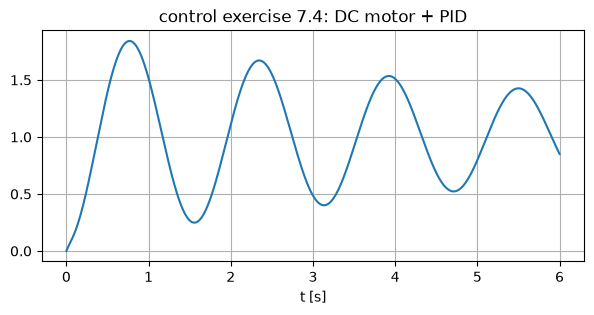

📘 OFFICIAL ANSWER: Θm/V = Km / (s[(Ls + R)(Jm s + Bm) + Kb Km]);  Θm/τl = -((Ls + R)/r) / (s[(Ls + R)(Jm s + Bm) + Kb Km])


In [87]:
Lm_s, Rm_s, Kb_s, Km_s, Jm_s, Bm_s, r_s, V_s, Ia_s, Om_s, tl_s = sp.symbols('L R K_b K_m J_m B_m r V I_a Omega_m tau_l')
sol_m = solve_loop([sp.Eq((Lm_s * s + Rm_s) * Ia_s + Kb_s * Om_s, V_s),
                    sp.Eq((Jm_s * s + Bm_s) * Om_s, Km_s * Ia_s - tl_s / r_s)], [Ia_s, Om_s], explain=False)
Th_m = sp.simplify(sol_m[Om_s] / s)
G74_V = sp.factor(sp.simplify(Th_m.subs(tl_s, 0) / V_s)); pm("Θm/V  (τ_l = 0)", G74_V)
G74_T = sp.factor(sp.simplify(Th_m.subs(V_s, 0) / tl_s)); pm("Θm/τ_l  (V = 0)", G74_T)
G_74 = dc_motor_tf(0.002, 2, 0.08, 0.08, 2e-4, 2e-3, explain=False)                                   # <-- CHANGE
tf_info(feedback((0.12 + 2.2 / s + 0.01 * s) * G_74), "PID loop", explain=False)
step_response(feedback((0.12 + 2.2 / s + 0.01 * s) * G_74), t_end=6, title_="control exercise 7.4: DC motor + PID")
official("Θm/V = Km / (s[(Ls + R)(Jm s + Bm) + Kb Km]);  Θm/τl = -((Ls + R)/r) / (s[(Ls + R)(Jm s + Bm) + Kb Km])")

### 10.29 DC motor model, poles, and which P gains are stable (motor exercise 31383)
$V_a=(R_a+L_as)I_a+K_b\omega$, $T_m=K_mI_a=Js^2\theta+bs\theta$; $J=2$, $K_m=10$, $R_a=1$, $L_a=1$, $b=0.5$, $K_b=0.1$.


✅ ANSWER: Θ/V: 3 poles: -0.625 + 0.5995j, -0.625 - 0.5995j, 0  → marginally stable (a pole on the imaginary axis, e.g. s = 0)

Routh–Hurwitz table
   s^3: 4   3
   s^2: 5   20*K_p
   s^1: 3 - 16*K_p   0
   s^0: 20*K_p   0

▶ stable ⇔ every first-column entry > 0 (entries that are always positive are not listed):


3 - 16⋅Kₚ > 0


✅ ANSWER: stable for K_p < 3/16



✅ ANSWER: value at t_end = 0.9998, overshoot % = 6.1752, settling time 2% = 7.6933, rise time 10-90% = 1.6133


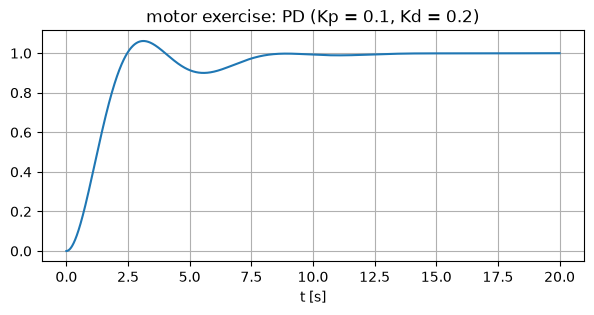

📘 OFFICIAL ANSWER: G = Km / ((J s² + b s)(Ra + La s) + Km Kb s); poles 0 and -0.625 ± 0.599j; P-only is unstable for Kp > 0.1875


In [88]:
G_31383 = dc_motor_tf(L=1, R=1, Kb=0.1, Kt=10, J=2, B=0.5, explain=False)            # <-- CHANGE
Kp_r = sp.symbols('K_p', positive=True)
first_31383 = routh(sp.fraction(sp.together(1 + Kp_r * G_31383))[0])                 # P control: stable for Kp < 3/16
tt_, y_, info_ = step_response(feedback((0.1 + 0.2 * s) * G_31383), t_end=20, title_="motor exercise: PD (Kp = 0.1, Kd = 0.2)")
official("G = Km / ((J s² + b s)(Ra + La s) + Km Kb s); poles 0 and -0.625 ± 0.599j; P-only is unstable for Kp > 0.1875")

### 10.30 Why independent joint control works (control exercise 7.5)
With gear ratio $r$, $\tilde D(q)=D(q)+\text{diag}(J_{m1}r_1^2,J_{m2}r_2^2)$: the diagonal grows with $r^2$, so the coupling becomes small.
The numbers below are **my example values** (the sheet gives only plots), to show the effect.

In [89]:
num_2r = {m1: 1.0, m2: 1.0, l1: 0.5, l2: 0.5, lc1: 0.25, lc2: 0.25, I1: 0.02, I2: 0.02}      # example link data  <-- CHANGE
D_ex = np.array(D2r.subs(num_2r).subs(qb, np.pi / 4).evalf(), dtype=float)
for r_g in (1, 20, 100):
    Dt = D_ex + np.diag([1e-4 * r_g**2] * 2)                                          # J_m = 1e-4 kg·m² per motor
    answer(f"r = {r_g:>3}: D~ = {clean(Dt, 3).tolist()} → off-diagonal / diagonal = {abs(Dt[0, 1]) / min(Dt[0, 0], Dt[1, 1]):.3f}")
official("the larger r, the more diagonal D~ (coupling torque τ_cpl = (D~ - diag D~) q̈ + C q̇ becomes small)")


✅ ANSWER: r =   1: D~ = [[0.592, 0.171], [0.171, 0.083]] → off-diagonal / diagonal = 2.069

✅ ANSWER: r =  20: D~ = [[0.632, 0.171], [0.171, 0.122]] → off-diagonal / diagonal = 1.395

✅ ANSWER: r = 100: D~ = [[1.592, 0.171], [0.171, 1.082]] → off-diagonal / diagonal = 0.158
📘 OFFICIAL ANSWER: the larger r, the more diagonal D~ (coupling torque τ_cpl = (D~ - diag D~) q̈ + C q̇ becomes small)


---
# 11. Self-test: re-solve every past-exam example above and check the answers
Sections 1–9 check the MCQ and the examples; the second half checks every **official answer** of the exercise bank (Section 10).
If this cell prints **ALL CHECKS PASSED**, every solver works on your machine. Run it at home before the exam: **Run All**, then look here.
If a line shows ✘, restart the kernel and **Run All** again (a changed INPUT cell can also make its check fail, which is fine).

In [90]:
_saved = (EXPLAIN, SILENT)
EXPLAIN, SILENT = False, True                    # no printing while checking
checks = {}
try:
    # ---- Section 1
    T_chk = compose(steps)
    checks["Q1.1 transform"] = np.allclose(T_chk[:3, :], [[0.766, -0.321, 0.557, 13.93],
                                                          [0.643, 0.383, -0.663, 19.15],
                                                          [0, 0.866, 0.5, 43.30]], atol=2e-3)
    checks["week-2 P1 rotation"] = np.allclose(T_w2[:3, :3], [[0.433, 0.75, 0.5], [0.25, 0.433, -0.866], [-0.866, 0.5, 0]], atol=1e-3)
    checks["Q1.2 symbolic frame"] = sp.simplify(H01 - sp.Matrix([[0, 1, 0, L - ell], [1, 0, 0, a],
                                                                 [0, 0, -1, Hgt - h], [0, 0, 0, 1]])) == sp.zeros(4, 4)
    checks["lecture ω from S"] = np.allclose(omega_from_S([[0, 3, -1], [-3, 0, -4], [1, 4, 0]])[0], [4, -1, -3])
    checks["ZYZ round trip"] = np.allclose(zyz_from_R(R_from_zyz(30, 45, 60))[0], (30, 45, 60))
    checks["RPY of the Q1.1 rotation"] = np.allclose(rpy_from_R(T_chk[:3, :3])[0], (60, 0, 40), atol=1e-6)
    # ---- Section 2
    checks["Q2.2 DH table from frames"] = np.allclose(np.array(dh_from_frames(frames_q22)),
                                                      [[180, 90, 0, -90], [180, 0, -400, 0], [180, 0, 400, 0],
                                                       [0, 180, 0, 90], [0, -90, 0, -90]])
    _dA = dh_from_A([[1, 0, 0, 3], [0, r2, -r2, 0], [0, r2, r2, 0], [0, 0, 0, 1]])
    checks["2016 P2 DH from A"] = np.allclose([_dA['theta'], _dA['d'], _dA['a'], _dA['alpha']], [0, 0, 3, 45])
    checks["Stanford tip position"] = sp.simplify(o6_stanford - sp.Matrix(
        [q3 * sp.sin(q2) * sp.cos(q1) - sp.sin(q1) / 10, q3 * sp.sin(q1) * sp.sin(q2) + sp.cos(q1) / 10, q3 * sp.cos(q2)])) == sp.zeros(3, 1)
    # ---- Section 3
    checks["Q2.3 IK (63°, 63°)"] = np.allclose(ik_2r(0, 592.7, 391, 302)[0], (63, 63), atol=0.05)
    checks["2016 P4.5 IK"] = np.allclose(ik_2r(0, -0.1, 0.1, 0.1), [(-150, 120), (-30, -120)], atol=1e-6)
    _rob4 = Robot([(0, 50, 0, 90), (0, 0, 100, 0), (0, 0, 100, 0), (0, 0, 50, 0)], 'RRRR')
    checks["4-DoF IK (FK check)"] = len(sols_4dof) == 4 and all(np.allclose(_rob4.frames(q_)[-1][:3, 3], [150, 50, 120]) for q_ in sols_4dof)
    checks["decoupling: elbow + wrist"] = (any(np.allclose(q_, (20, 30, -40), atol=1e-6) for q_ in ik_elbow(*oc, d1=d1_, a2=a2_, a3=a3_))
                                          and any(np.allclose(q_, (10, 50, 60), atol=1e-6) for q_ in ik_spherical_wrist(R03, T06[:3, :3])))
    checks["numerical IK"] = any(np.allclose(q_, (63, 63), atol=0.05) for q_ in two_r.ik_numeric([0, 592.7, 0]))
    # ---- Section 4
    checks["Q3.1 J q̇ grid"] = np.allclose([apply_jacobian(Jv_q31, qd_) for qd_ in [(1, 1), (1, -1), (1.371, -3.354), (-0.409, 0)]],
                                          [[-0.841, -0.178], [-0.353, 0.178], [0, 0.597], [0.244, 0]], atol=2e-3)
    _tip, _elb, _, _ = geometry_from_planar_J(Jv_q31)
    checks["Q3.1 geometry from J"] = np.allclose(_tip, [0, 0.597]) and np.allclose(_elb, [0.178, 0.353])
    _c1, _s1 = sp.cos(q1), sp.sin(q1)
    checks["cylindrical Jacobian"] = sp.simplify(J_cyl - sp.Matrix([[-q3 * _c1, 0, -_s1], [-q3 * _s1, 0, _c1], [0, 1, 0],
                                                                    [0, 0, 0], [0, 0, 0], [1, 0, 0]])) == sp.zeros(6, 3)
    checks["2R singularity det"] = sp.simplify(singularities(J_2r_sym[:2, :], [q1, q2]) - l1 * l2 * sp.sin(q2)) == 0
    checks["2016 P4.2 free vector"] = np.allclose(transform_vector(arm2.frames([60, 60])[-1], [0.5, 0.5, 0]), [-0.683, 0.183, 0], atol=1e-3)
    # ---- Section 5
    checks["Q3.2 quintic"] = np.allclose(quintic(np.pi / 4, 0, 0, 2, 0, 1, 0, 0), [0.7854, 0, 0, -1.982, 1.611, -0.3348], atol=1e-3)
    _C = multi_joint([0.25 * pi, 0.6 * pi, -0.52 * pi, 0], [0.33 * pi, 0.4 * pi, -0.4 * pi, -0.2 * pi], 0, 1,
                     vf=[3.596, 9.246, -7.746, -5.096])
    checks["ball-catcher cubics"] = np.allclose(_C[[0, 3]], [[0.785, 0, -2.842, 3.093], [0, 0, 3.211, -3.839]], atol=2e-3)
    checks["2016 P3 constant jerk"] = abs(float(t1_val) - 1.137805) < 1e-5 and abs(float(vmax_2016) - 12.946) < 1e-3
    # ---- Section 6
    checks["Q4.1 image plane"] = np.allclose(uv_q41.T, [[-0.48, -0.48, 0.32, 0.32], [-0.48, 0, 0, -0.48]])
    checks["Q4.2 pixels CIAO"] = np.allclose(np.round(rc_q42), [[282, 208], [269, 189], [244, 208], [231, 170]])
    checks["Q4.3 base frame"] = np.allclose(P_base_q43, [[-25, 325, 0], [-15, 315, 0], [5, 325, 0], [15, 305, 0]])
    checks["Q4.4 moved camera"] = np.allclose(np.round(rc_q44), [[231, 112], [206, 131]])
    checks["VisionExam Q4.1"] = np.allclose(np.round(rc_ve), [[313, 346], [123, 346], [123, 57], [313, 57],
                                                              [282, 298], [187, 298], [187, 154], [282, 154]])
    checks["VisionExam Q4.2 depth"] = abs(depth_from_size(8, 0.3, d_mm_ve) - 1.2) < 0.01
    checks["2016 P4.3 back-projection"] = np.allclose(pixel_to_camera(470, 290, 0.8, cam16), [-0.3, -0.1, 0.8])
    # ---- Section 7
    checks["Q5.1 poles (3 with L, 2 without)"] = len(tf_info(G_motor)) == 3 and len(tf_info(G_motor_L0)) == 2
    checks["Q5.2 e_ss = 0.00496"] = abs(float(ess_q52) - 5 / 1008) < 1e-9
    checks["2016 P5 Kp ≥ 29.5"] = sp.solve(sp.Eq(ess16, sp.Rational(1, 100)), Kp_s)[0] == sp.Rational(59, 2)
    checks["E2 block reduction"] = sp.simplify(feedback(L_e2) - (s**2 + 6 * s + 9) / (3 * s**2 + 18 * s + 19)) == 0
    checks["B1 poles -14 -24 -44 -404"] = all(np.isclose(tf_info(k_ / (0.05 * s + 0.2 + k_))[0].real, -(0.2 + k_) / 0.05)
                                              for k_ in (0.5, 1, 2, 20))
    checks["DC motor exercise 200/(s(s+26))"] = sp.simplify(dc_motor_tf(0, 2, 0.08, 0.08, 2e-4, 2e-3) - 200 / (s * (s + 26))) == 0
    _first = routh(Jr * s**3 + (Br + Kdr) * s**2 + Kpr * s + Kir)
    checks["PID Routh condition"] = sp.simplify(_first[2] - ((Br + Kdr) * Kpr - Jr * Kir) / (Br + Kdr)) == 0
    checks["Routh K < 60"] = sp.simplify(routh(s**3 + 6 * s**2 + 11 * s + 6 + Kr)[2] - (60 - Kr) / 6) == 0
    checks["final value 2.5"] = final_value(5 / (s * (s**2 + 3 * s + 2))) == sp.Rational(5, 2)
    # ---- Section 8
    _cq = sp.cos(qb)
    _a = I1 + I2 + m1 * lc1**2 + m2 * (l1**2 + lc2**2); _b = m2 * l1 * lc2; _d = I2 + m2 * lc2**2
    checks["2R dynamics closed form"] = sp.simplify(D2r - sp.Matrix([[_a + 2 * _b * _cq, _d + _b * _cq], [_d + _b * _cq, _d]])) == sp.zeros(2, 2)
    checks["spatial 2-link τ = (564.54, -12.87)"] = np.allclose(tau_sp, [564.54, -12.87], atol=0.01)
    checks["week-6 bars D"] = sp.simplify(D_w6 * 1200 / (mb * Lb**2) - sp.Matrix([[2002 + 1200 * _cq, 401 + 600 * _cq],
                                                                                [401 + 600 * _cq, 401]])) == sp.zeros(2, 2)
    # ---- Section 9
    checks["linear system (the Q3.2 3x3)"] = np.allclose(lin_solve([[8, 16, 32], [12, 32, 80], [12, 48, 160]], [-np.pi / 4, 1, 0]),
                                                         [-1.9817, 1.6113, -0.3348], atol=1e-3)
    checks["numeric equation cos q = q"] = abs(solve_eqs([sp.cos(qq) - qq], [qq], guess=[0.5])[qq] - 0.739085) < 1e-5
    # ---- Section 10: exercise bank against the OFFICIAL answers
    r2_ = 1 / np.sqrt(2)
    checks["W2 P2/P3: equivalent rotation sequence"] = sp.simplify(R_w2p2 - R_w2p3) == sp.zeros(3, 3)
    checks["L2: current vs fixed (R_y45, R_z45)"] = (np.allclose(R_cur, [[0.5, -0.5, r2_], [r2_, r2_, 0], [-0.5, 0.5, r2_]])
                                                    and np.allclose(R_fix, [[0.5, -r2_, 0.5], [0.5, r2_, 0.5], [-r2_, 0, r2_]]))
    checks["L3: five-step product order"] = np.allclose(R_l3, rotx(de5) @ rotz(al5) @ rotx(th5) @ rotz(ph5) @ roty(be5))
    checks["W2 P6: frame chain A04"] = np.allclose(A04_w6, [[-1, 0, 0, 0], [0, 0.6, -0.8, 0], [0, -0.8, -0.6, 0.5], [0, 0, 0, 1]])
    checks["2017 P2: box frames"] = (sp.simplify(Hinv(T1_2) - sp.Matrix([[0, 1, 0, 0], [0, 0, -1, 0], [-1, 0, 0, A_bx], [0, 0, 0, 1]])) == sp.zeros(4, 4)
                                     and sp.simplify(Hinv(T1_3) * T1_2 - sp.Matrix([[0, 1, 0, B_bx], [-1, 0, 0, C_bx], [0, 0, 1, 0], [0, 0, 0, 1]])) == sp.zeros(4, 4)
                                     and sp.simplify(T1_3 - sp.Matrix([[0, 0, -1, A_bx], [0, -1, 0, C_bx], [-1, 0, 0, B_bx], [0, 0, 0, 1]])) == sp.zeros(4, 4))
    _dt = [sp.diff(f_, t) for f_ in (th1f, th2f, th3f)]
    _w_off = sp.Matrix([sp.cos(th1f) * _dt[1] - sp.sin(th1f) * sp.cos(th2f) * _dt[2],
                        sp.sin(th1f) * _dt[1] + sp.cos(th1f) * sp.cos(th2f) * _dt[2], _dt[0] + sp.sin(th2f) * _dt[2]])
    checks["2019 P2: angular velocity"] = sp.simplify(w02_19 - _w_off) == sp.zeros(3, 1)
    _d17 = dh_from_A([[0, -0.5, np.sqrt(3) / 2, 0], [1, 0, 0, 2], [0, np.sqrt(3) / 2, 0.5, 0], [0, 0, 0, 1]])
    checks["2017 P1: DH from A"] = np.allclose([_d17['theta'], _d17['d'], _d17['a'], _d17['alpha']], [90, 0, 2, 60])
    checks["2019 P1: DH from a partial A"] = np.allclose(sols_19p1[0], [60, 1 / 3, 2, 300], atol=1e-5)
    checks["2020 P1: bracket DH"] = np.allclose(table_20p1[0], [60, 400, 100 * np.sqrt(3), -90], atol=1e-4)
    checks["2020 P2: T04"] = (np.allclose(T04_20[:3, :3], [[0.8623, -0.4999, -0.07945], [-0.3623, -0.4999, -0.7865], [0.3535, 0.7071, -0.6123]], atol=3e-4)
                              and np.allclose(T04_20[:3, 3], [171.4, 171.4, 142.4], atol=0.05))
    checks["2020 P2: tip velocity"] = np.allclose(v04_20, [-1.346, 1.346, 0], atol=1e-3)
    _c2, _s2, _c23, _s23 = sp.cos(th2w), sp.sin(th2w), sp.cos(th2w + th3w), sp.sin(th2w + th3w)
    checks["W4 P4: T03 and J with a tool"] = (
        sp.simplify(prr.frames([d1w, th2w, th3w])[-1] - sp.Matrix([[_c23, 0, _s23, a2w * _c2 + a3w * _s23], [0, 1, 0, 0],
                                                                   [-_s23, 0, _c23, d1w - a2w * _s2 + a3w * _c23], [0, 0, 0, 1]])) == sp.zeros(4, 4)
        and sp.simplify(J_prr - sp.Matrix([[0, -a2w * _s2 + a3w * _c23, a3w * _c23], [0, 0, 0], [1, -a2w * _c2 - a3w * _s23, -a3w * _s23],
                                           [0, 0, 0], [0, 1, 1], [0, 0, 0]])) == sp.zeros(6, 3))
    checks["CourseBot IK (FK check)"] = len(sols_cb) == 4 and all(np.allclose(coursebot.frames(q_)[-1][:3, 3], [150, 32, 120]) for q_ in sols_cb)
    checks["L6: ball catcher J⁺ξ"] = np.allclose(qd_bc, [3.596, 9.246, -7.746, -5.096], atol=1e-3)
    checks["2016 P3: constant jerk (profile)"] = abs(float(t1_16) - 1.137805202) < 1e-8
    checks["2017 P3: sine jerk"] = (sp.simplify(prof17[0]['v_end'] - 20 / sp.pi) == 0 and sp.simplify(prof17[0]['s_end'] - 20 / sp.pi) == 0
                                    and T17 == [sp.pi])
    checks["2019 P3: piecewise acceleration"] = (prof19[1]['s_end'] == 5 and T19 == [13] and abs(ext19['v'][0] - 3) < 1e-9
                                                and abs(ext19['j'][0] - 2) < 1e-9)
    checks["2020 P3: minimum time"] = abs(float(ta20) - 0.01385) < 1e-5 and abs(ext20['v'][0] - 4.33) < 0.01 and abs(ext20['j'][0] - 4.453e5) < 100
    checks["2016 P4.3-4.4: pixel → base"] = np.allclose(pc16, [-0.3, -0.1, 0.8]) and np.allclose(p0_16, [0, -0.1, -0.3])
    checks["2017 P4: object → base (both signs)"] = np.allclose(obj17, [[0.5122, 0.6101, 0.1]] * 2, atol=2e-4)
    checks["2019 P4: pixels [445;240] / [195;240]"] = np.allclose(np.round(px19), [[445, 240], [195, 240]])
    checks["2020 P4: task frames"] = (np.allclose(T_task1[:2, :2], [[0.921, -0.3896], [0.3896, 0.921]], atol=1e-3)
                                      and np.allclose(T_task2[:2, :2], [[0.995, -0.1], [0.1, 0.995]], atol=1e-3))
    checks["2020 P4: stereo point → base"] = np.allclose(to_frame(TBc1, pc1_st)[0], [0.45, 0.2, 0])
    checks["vision ex. 1-3: drone, couch, people"] = (abs(dmm - 4.6925) < 1e-3 and abs(8 * scale - 61.09) < 0.02 and abs(xH - 19.28) < 0.01
                                                      and abs(H_c - 0.910) < 0.003 and abs(z_front - 7.130) < 0.003
                                                      and abs(h_people[0] - 1.72) < 0.005 and abs(h_people[1] - 1.75) < 0.005)
    checks["2017 P5: F, H, N, e_ss"] = (sp.simplify(F17 - (sp.Rational(15, 100) * s + sp.Rational(15, 1000))) == 0
                                        and sp.simplify(H17 - s / 2) == 0 and e17 == 0
                                        and sp.simplify(N17 - (s**3 + s**2 / 2 + sp.Rational(15, 100) * s + sp.Rational(15, 1000))) == 0)
    checks["2019 P5: 0.7/(s+0.79), e_ss 0 and 0.2381"] = (sp.simplify(G19 - sp.Rational(7, 10) / (s + sp.Rational(79, 100))) == 0
                                                         and e19a == 0 and abs(float(e19b) - 0.2381) < 1e-4)
    _N20 = sp.Rational(2, 10) * s**3 + sp.Rational(8, 10) * s**2 + sp.Rational(1, 2) * s + sp.Rational(1, 10)
    checks["2020 P5: F/N and H/N"] = (sp.simplify(F20 / N20 - (s / 2 + sp.Rational(1, 10)) / _N20) == 0
                                      and sp.simplify(H20 / N20 - s / _N20) == 0 and e20 == 0)
    _pl = lambda G_: sorted(tf_info(G_), key=lambda z: (z.real, z.imag))
    checks["control ex. pole tables (B2, C1, D1, D2)"] = (
        np.allclose(_pl(feedback(0.5 * G2x)), [-10 - 53.85j, -10 + 53.85j], atol=0.01)
        and np.allclose(_pl(feedback((2 + 1 / s) * G1x)), [-43.54, -0.4593], atol=0.01)
        and np.allclose(_pl(feedback((20 + 5 / s + 0.1 * s) * G1x)), [-134.42, -0.248], atol=0.01)
        and np.allclose(_pl(feedback((2 + 5 / s + 0.03 * s) * G2x)), [-39.15 - 65.83j, -39.15 + 65.83j, -1.7046], atol=0.01))
    checks["control ex. E1"] = sp.simplify(feedback(k_s * P_e1) - k_s / (m_s * s + b_s + k_s)) == 0
    _brk = (Lm_s * s + Rm_s) * (Jm_s * s + Bm_s) + Kb_s * Km_s
    checks["control ex. 7.4: Θ/V and Θ/τ"] = (sp.simplify(G74_V - Km_s / (s * _brk)) == 0
                                             and sp.simplify(G74_T + (Lm_s * s + Rm_s) / (r_s * s * _brk)) == 0)
    checks["motor exercise: poles, Kp < 0.1875"] = (np.allclose(_pl(G_31383), [-0.625 - 0.5995j, -0.625 + 0.5995j, 0], atol=1e-3)
                                                   and sp.solve(first_31383[2], Kp_r) == [sp.Rational(3, 16)])
finally:
    EXPLAIN, SILENT = _saved

for k_, v_ in checks.items():
    print(("✔ " if v_ else "✘ ") + k_)
print(f"\n{sum(checks.values())}/{len(checks)} checks passed")
print("ALL CHECKS PASSED ✔" if all(checks.values()) else "SOMETHING FAILED ✘  (see the ✘ lines above)")

✔ Q1.1 transform
✔ week-2 P1 rotation
✔ Q1.2 symbolic frame
✔ lecture ω from S
✔ ZYZ round trip
✔ RPY of the Q1.1 rotation
✔ Q2.2 DH table from frames
✔ 2016 P2 DH from A
✔ Stanford tip position
✔ Q2.3 IK (63°, 63°)
✔ 2016 P4.5 IK
✔ 4-DoF IK (FK check)
✔ decoupling: elbow + wrist
✔ numerical IK
✔ Q3.1 J q̇ grid
✔ Q3.1 geometry from J
✔ cylindrical Jacobian
✔ 2R singularity det
✔ 2016 P4.2 free vector
✔ Q3.2 quintic
✔ ball-catcher cubics
✔ 2016 P3 constant jerk
✔ Q4.1 image plane
✔ Q4.2 pixels CIAO
✔ Q4.3 base frame
✔ Q4.4 moved camera
✔ VisionExam Q4.1
✔ VisionExam Q4.2 depth
✔ 2016 P4.3 back-projection
✔ Q5.1 poles (3 with L, 2 without)
✔ Q5.2 e_ss = 0.00496
✔ 2016 P5 Kp ≥ 29.5
✔ E2 block reduction
✔ B1 poles -14 -24 -44 -404
✔ DC motor exercise 200/(s(s+26))
✔ PID Routh condition
✔ Routh K < 60
✔ final value 2.5
✔ 2R dynamics closed form
✔ spatial 2-link τ = (564.54, -12.87)
✔ week-6 bars D
✔ linear system (the Q3.2 3x3)
✔ numeric equation cos q = q
✔ W2 P2/P3: equivalent rotation se

---
### If something goes wrong in the exam
* **NameError** (a function is not defined): run the setup and tools cells again (simplest: **Run All**).
* **Wrong kernel**: top right, choose *Python 3.14* (the global one), not `.venvrobotics`.
* **A weird answer**: check the units (mm or m, degrees or radians), the sign convention (current or global, pixel sign) and the input order. Every solver prints its formula: compare it with the one on the exam sheet.
* **Too much text**: `EXPLAIN = False` in the setup cell, then re-run the cell you need.